# Production de bar plot

## Boxplot

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


Lecture du fichiers

In [15]:
count = pd.read_csv("raw_counts.txt",skiprows=1,sep="\t")
count = count.iloc[:, [0]+list(range(6, count.shape[1]))]
count["gene_ID"] = (count["Geneid"].str.split(".").str[0])
count.columns = (count.columns.str.replace("../results/", "", regex=False).str.replace("_Aligned.sortedByCoord.out.bam", "", regex=False))
count = count.drop(columns="Geneid")
outlier = ["RNAseq1-KO5_S17","RNAseq2-KOind2_S44","RNAseq2-KOind4_S46"]
count = count.drop(columns=outlier)

# mettre gene_ID en index
count = count.set_index("gene_ID")

print("Matrice counts")
print(count.head())

Matrice counts
                 RNAseq1-KO1_S13  RNAseq1-KO2_S14  RNAseq1-KO3_S15  \
gene_ID                                                              
ENSG00000290825                0                0                0   
ENSG00000223972                0                0                0   
ENSG00000310526              235              248              178   
ENSG00000227232                0                0                0   
ENSG00000278267                0                0                0   

                 RNAseq1-KO4_S16  RNAseq1-KO6_S18  RNAseq1-KOind1_S19  \
gene_ID                                                                 
ENSG00000290825                0                0                   0   
ENSG00000223972                0                0                   0   
ENSG00000310526              207              405                 205   
ENSG00000227232                0                0                   0   
ENSG00000278267                0                0       

Annotation à l'aide de Biomart

In [16]:
biomart = pd.read_csv("biomart.csv")
biomart = biomart.rename(columns={"Gene stable ID":"gene_ID"})
print(biomart.head())

biomart["gene_ID"] = (biomart["gene_ID"].str.split(".").str[0])
biomart_clean = biomart[["gene_ID","Gene name"]]
biomart_clean = biomart_clean.drop_duplicates(subset="gene_ID")
print(biomart_clean.head())

# Ajout des noms
count_annot = (count.reset_index().merge(biomart_clean,on="gene_ID",how="left"))
print(count_annot.head())

           gene_ID Gene stable ID version Transcript stable ID  \
0  ENSG00000210049      ENSG00000210049.1      ENST00000387314   
1  ENSG00000211459      ENSG00000211459.2      ENST00000389680   
2  ENSG00000210077      ENSG00000210077.1      ENST00000387342   
3  ENSG00000210082      ENSG00000210082.2      ENST00000387347   
4  ENSG00000209082      ENSG00000209082.1      ENST00000386347   

  Transcript stable ID version Gene name  
0            ENST00000387314.1     MT-TF  
1            ENST00000389680.2   MT-RNR1  
2            ENST00000387342.1     MT-TV  
3            ENST00000387347.2   MT-RNR2  
4            ENST00000386347.1    MT-TL1  
           gene_ID Gene name
0  ENSG00000210049     MT-TF
1  ENSG00000211459   MT-RNR1
2  ENSG00000210077     MT-TV
3  ENSG00000210082   MT-RNR2
4  ENSG00000209082    MT-TL1
           gene_ID  RNAseq1-KO1_S13  RNAseq1-KO2_S14  RNAseq1-KO3_S15  \
0  ENSG00000290825                0                0                0   
1  ENSG00000223972       

In [18]:
deseq_KO_WT = pd.read_csv("results_KO_WT.csv")
deseq_KO_WT_induced = pd.read_csv("results_KO_WT_induced.csv")

deseq_KO_WT=deseq_KO_WT.rename(columns={"Unnamed: 0": "gene_ID"})
deseq_KO_WT_induced=deseq_KO_WT_induced.rename(columns={"Unnamed: 0": "gene_ID"})

deseq_KO_WT["gene_ID"] = (deseq_KO_WT["gene_ID"].str.split(".").str[0])
deseq_KO_WT_induced["gene_ID"] = (deseq_KO_WT_induced["gene_ID"].str.split(".").str[0])

# vérifier colonnes
print(deseq_KO_WT.columns)
print("KO_WT")
print(deseq_KO_WT.head())
if "Gene name" not in deseq_KO_WT.columns:
    deseq_KO_WT = deseq_KO_WT.merge(biomart_clean,on="gene_ID",how="left")

if "Gene name" not in deseq_KO_WT_induced.columns:
    deseq_KO_WT_induced = deseq_KO_WT_induced.merge(biomart_clean,on="gene_ID",how="left")

print(deseq_KO_WT)

Index(['gene_ID', 'baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue',
       'padj'],
      dtype='object')
KO_WT
           gene_ID    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
0  ENSG00000310526  219.713955        0.307920  0.142171  2.165835  0.030324   
1  ENSG00000243485    1.872687        0.217570  0.723234  0.300829  0.763545   
2  ENSG00000308361    0.217830       -0.474298  2.608873 -0.181802  0.855738   
3  ENSG00000241860   16.567196        0.022844  0.330535  0.069112  0.944900   
4  ENSG00000233750   24.751765       -0.395688  0.219779 -1.800386  0.071800   

       padj  
0  0.118961  
1       NaN  
2       NaN  
3  0.974120  
4  0.215428  
               gene_ID     baseMean  log2FoldChange     lfcSE      stat  \
0      ENSG00000310526   219.713955        0.307920  0.142171  2.165835   
1      ENSG00000243485     1.872687        0.217570  0.723234  0.300829   
2      ENSG00000308361     0.217830       -0.474298  2.608873 -0.181802   
3      ENSG00000

In [12]:
# Liste des gènes d'intêret
selected_genes = ['SOX2','FOXG1','TBR2','TBR1','BCL11B','SATB2','CUX1','MBP','PRDM1','RAX','VSX2',
'OTX2','CRX','NEUROD1','RCVRN','RORB','THRB','USH2A','NRL','NR2E3','NR2F1','PAX6','FOXP2','GAD1',
'MKI67','FABP7','NES','MED13L','UNC5D','TBXT','LMX1A','SOX11','ZIC5','ZIC1','PAX3','POU4F1','POU4F2',
'RXRG', 'IL33', "NHIP"]

# Normalisarion CPM pour la visualtion
count_numeric = count.copy()
library_size = (count_numeric.sum(axis=0))

count_cpm = (count_numeric.div(library_size, axis=1)*1000000)

count_log = np.log2(count_cpm + 1)

count_log = (count_log.reset_index().merge(biomart_clean,on="gene_ID",how="left"))

count_long = count_log.melt(id_vars=["gene_ID","Gene name"],var_name="sample",value_name="Expression")
print(count_long.head())

# Lecture des métadata
metadata = pd.read_csv("Fibro/metadata.csv")
metadata = metadata.rename(columns={"Unnamed: 0":"sample"})
count_long = count_long.merge(metadata[["sample","Condition"]],on="sample",how="left")
print(count_long.head())


           gene_ID  Gene name           sample  Expression
0  ENSG00000290825   DDX11L16  RNAseq1-KO1_S13    0.000000
1  ENSG00000223972    DDX11L1  RNAseq1-KO1_S13    0.000000
2  ENSG00000310526     WASH7P  RNAseq1-KO1_S13    2.098923
3  ENSG00000227232     WASH7P  RNAseq1-KO1_S13    0.000000
4  ENSG00000278267  MIR6859-1  RNAseq1-KO1_S13    0.000000
           gene_ID  Gene name           sample  Expression Condition
0  ENSG00000290825   DDX11L16  RNAseq1-KO1_S13    0.000000        KO
1  ENSG00000223972    DDX11L1  RNAseq1-KO1_S13    0.000000        KO
2  ENSG00000310526     WASH7P  RNAseq1-KO1_S13    2.098923        KO
3  ENSG00000227232     WASH7P  RNAseq1-KO1_S13    0.000000        KO
4  ENSG00000278267  MIR6859-1  RNAseq1-KO1_S13    0.000000        KO


Plot : SOX2


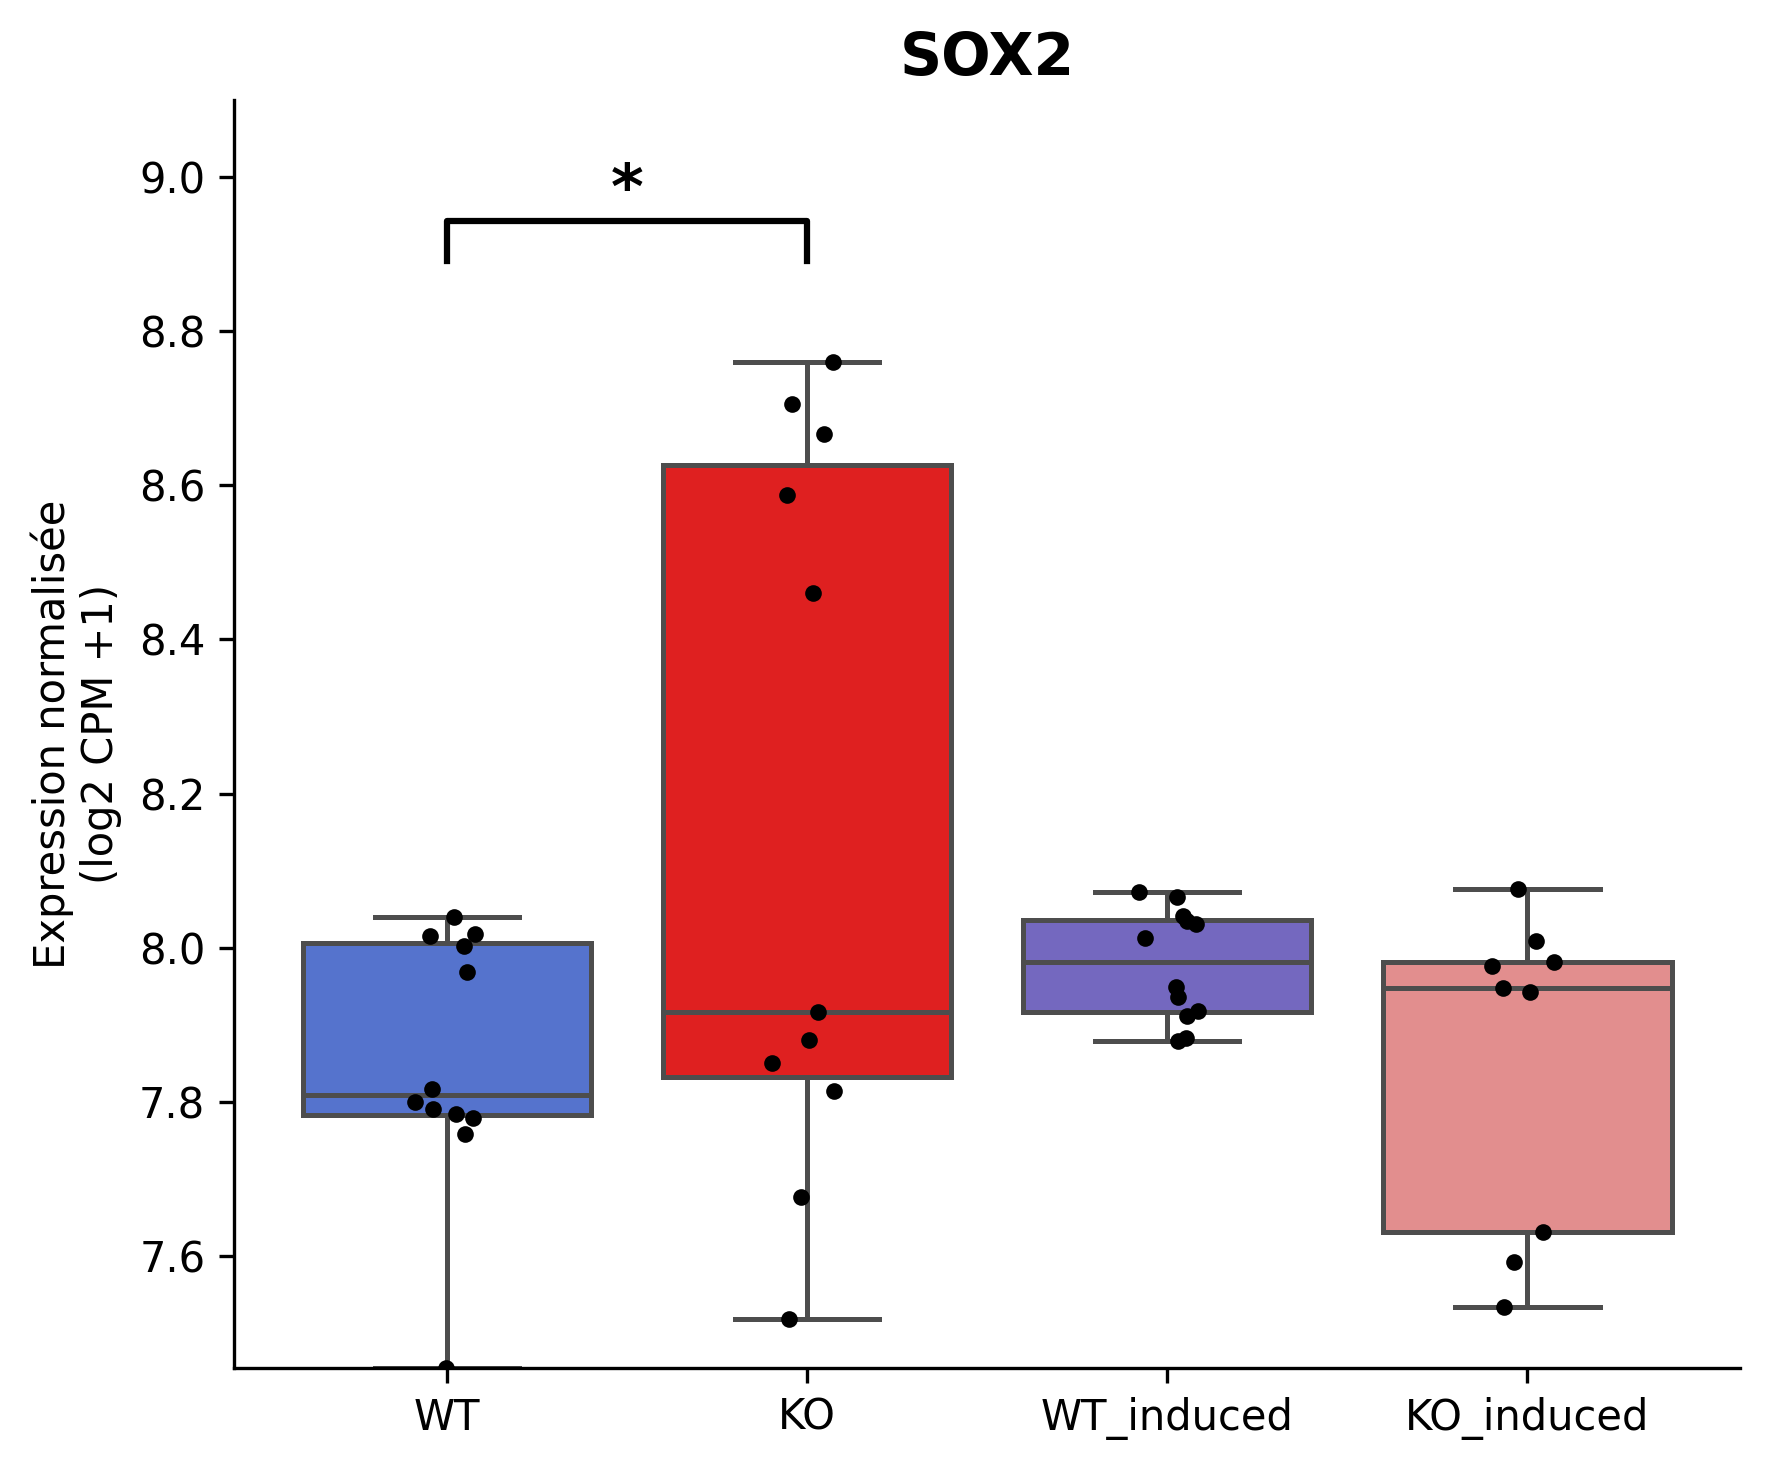

Plot : FOXG1


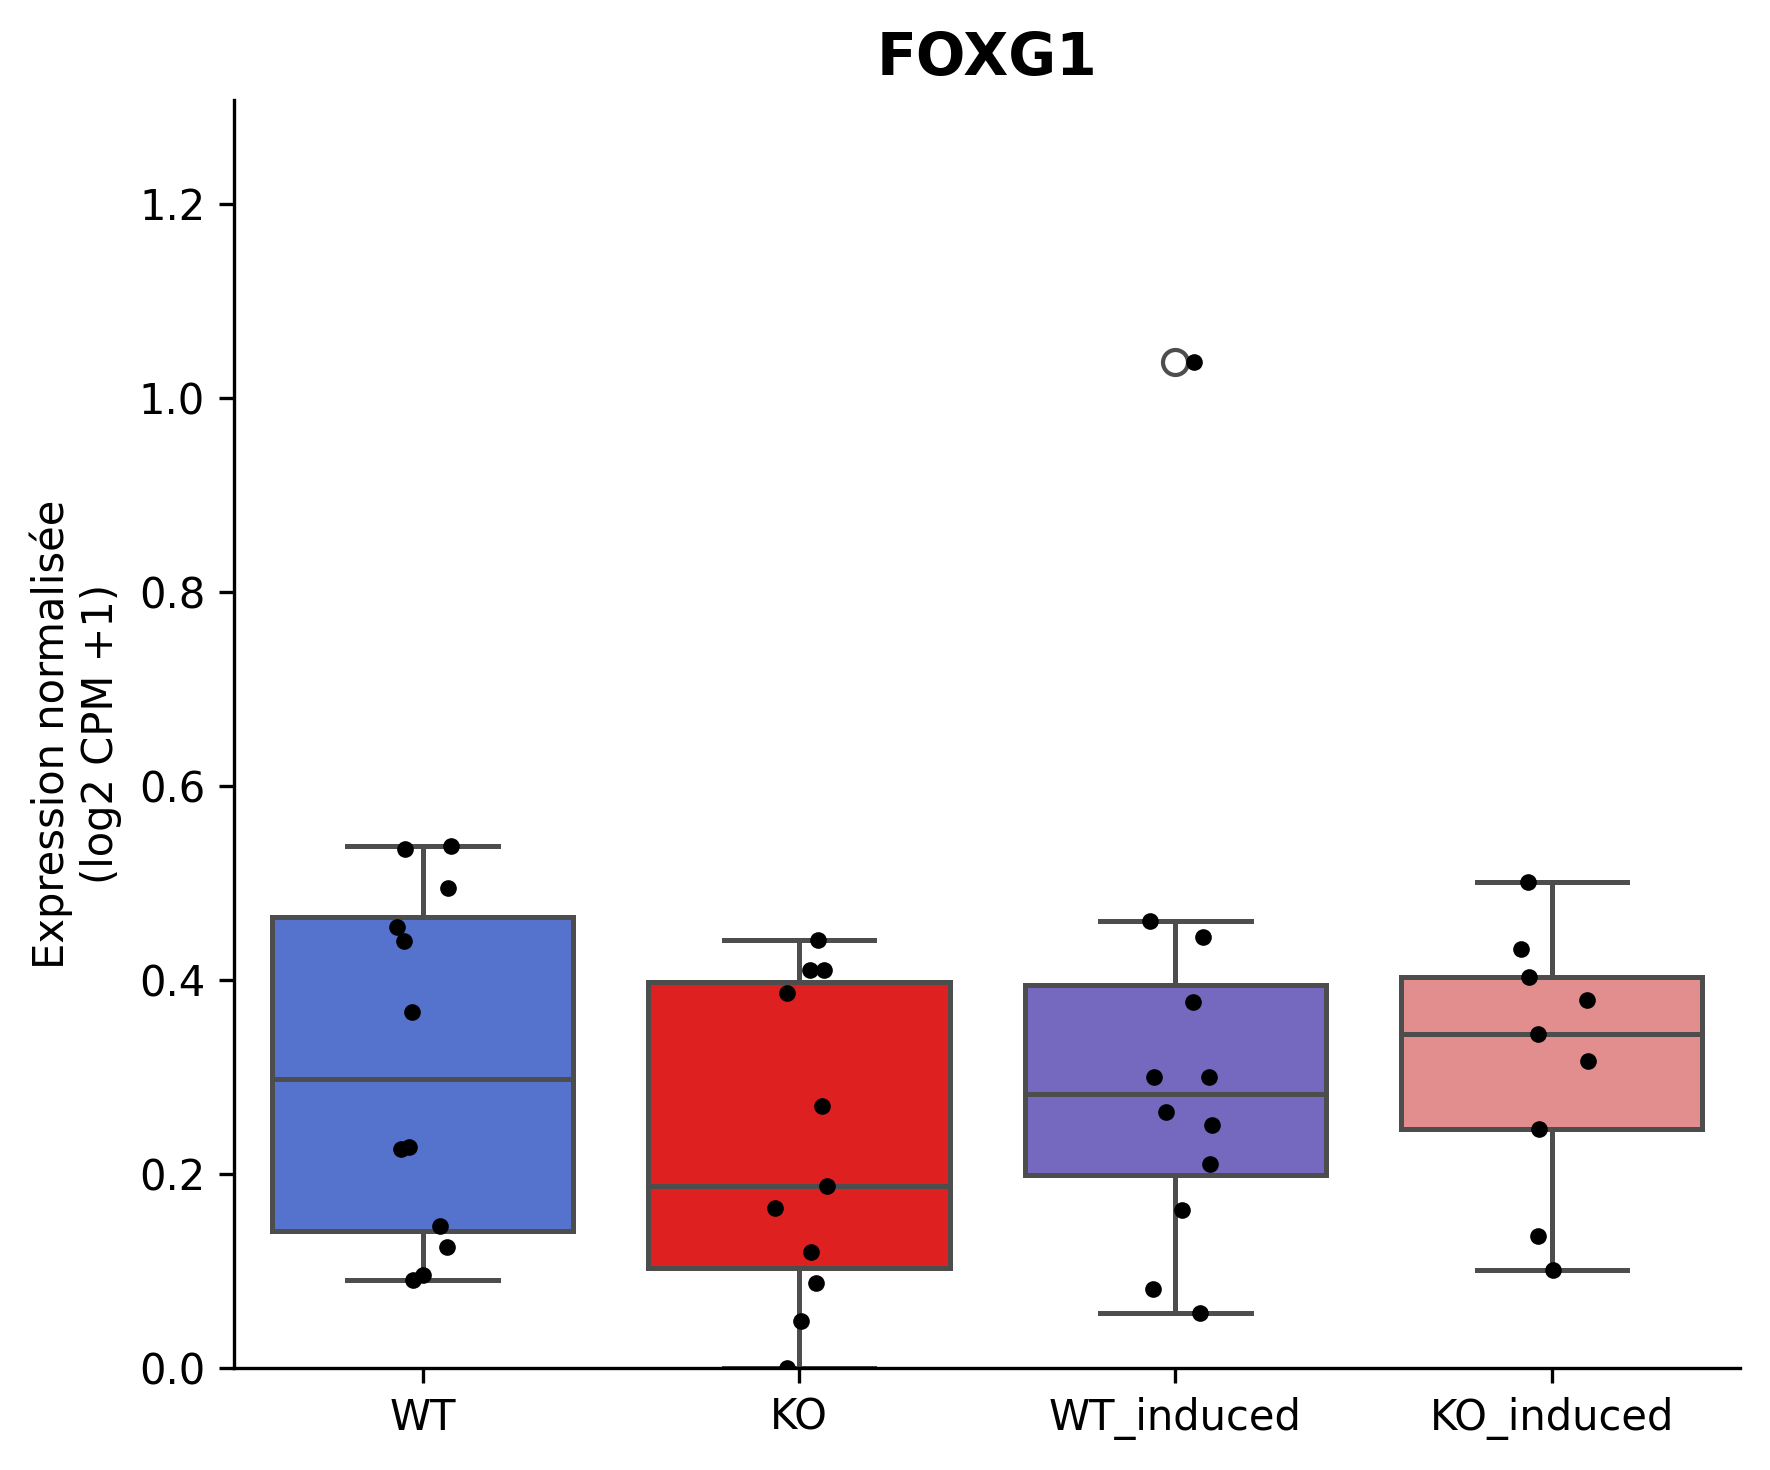

Plot : TBR1


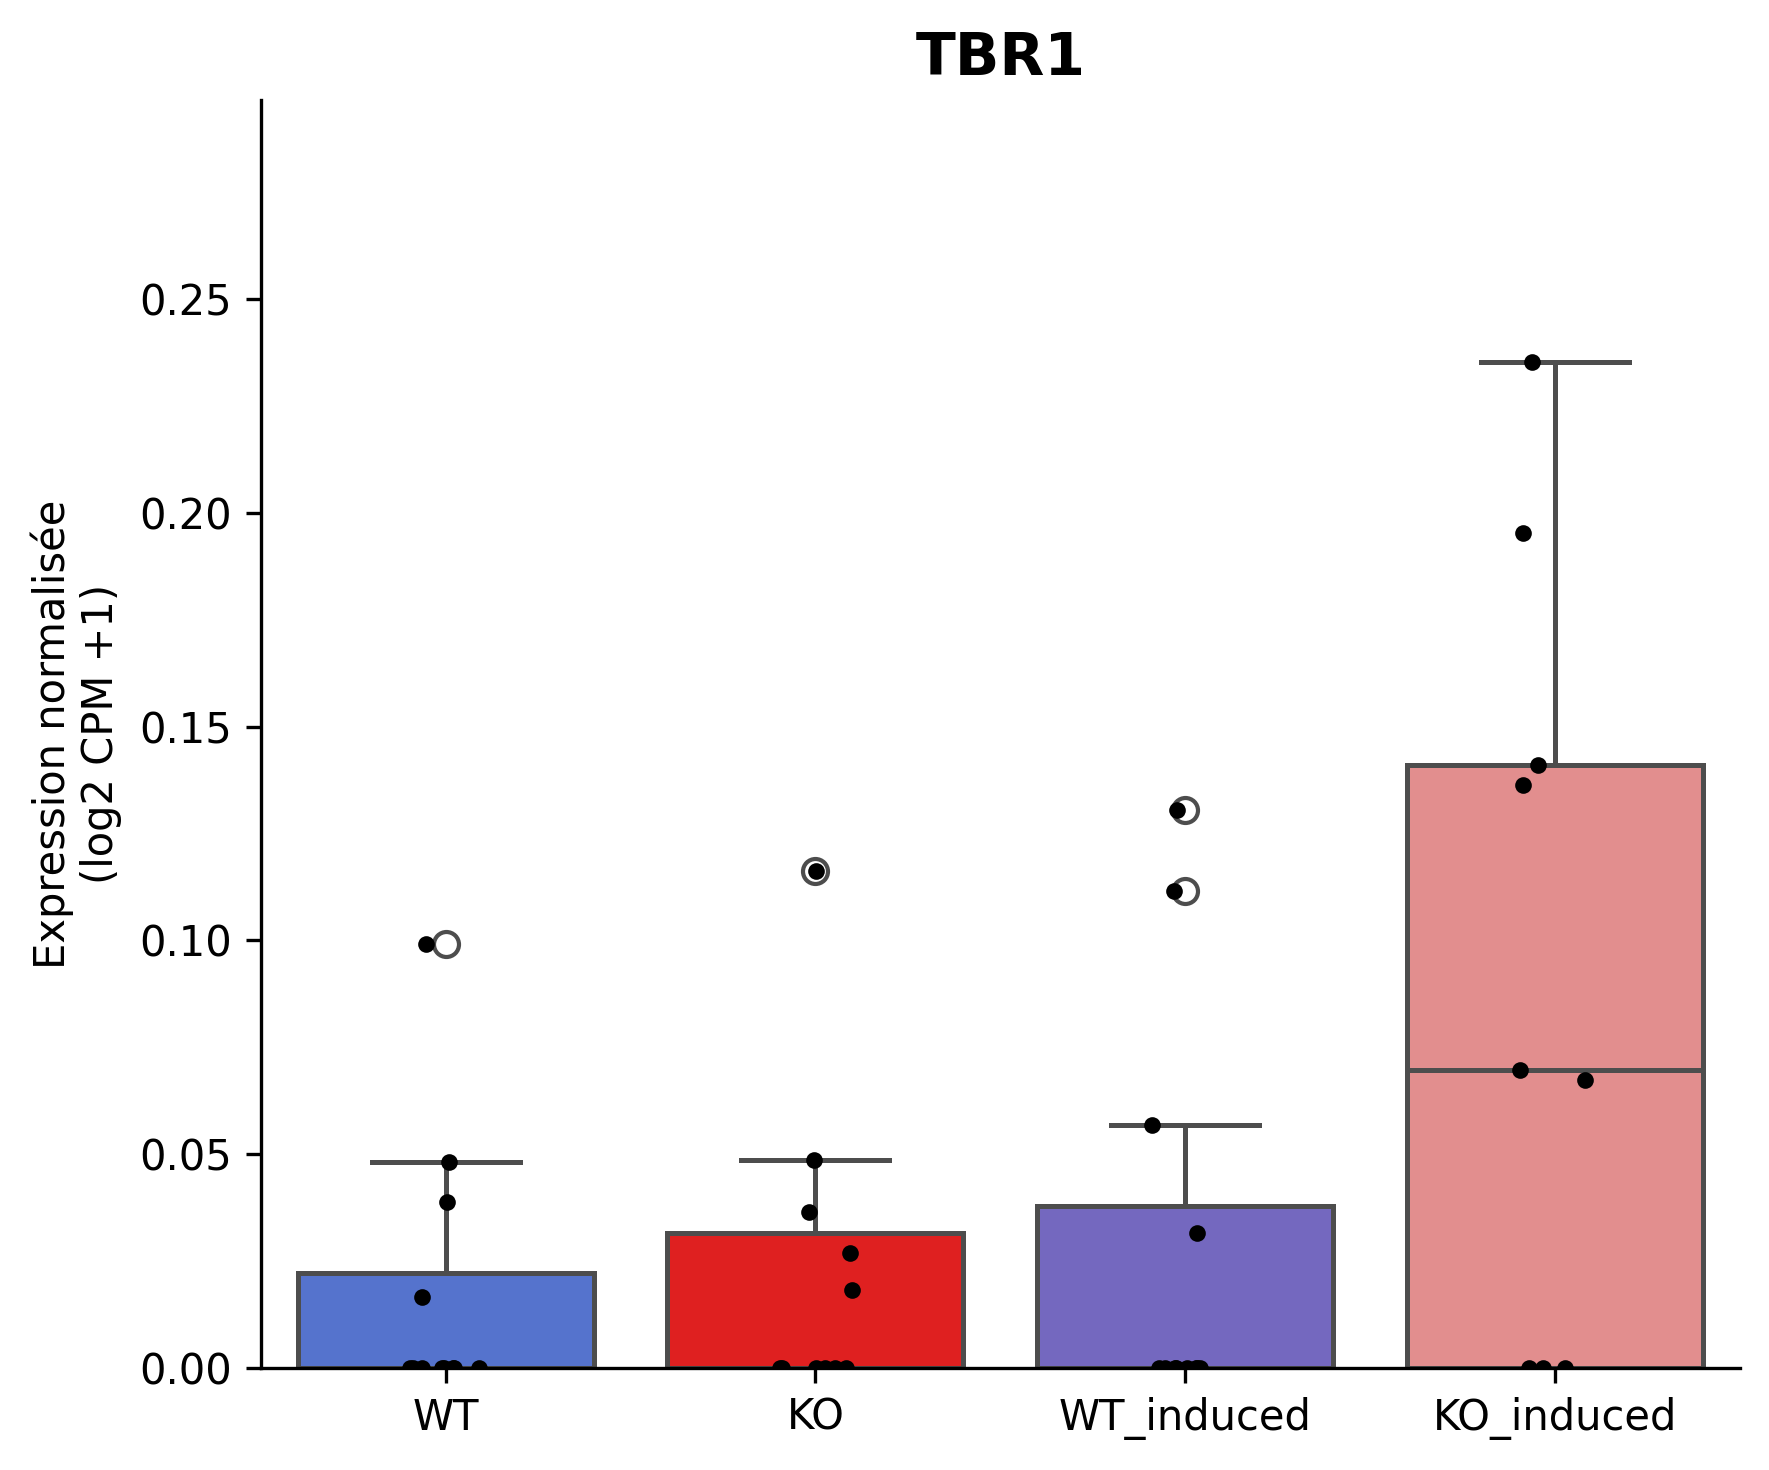

Plot : BCL11B


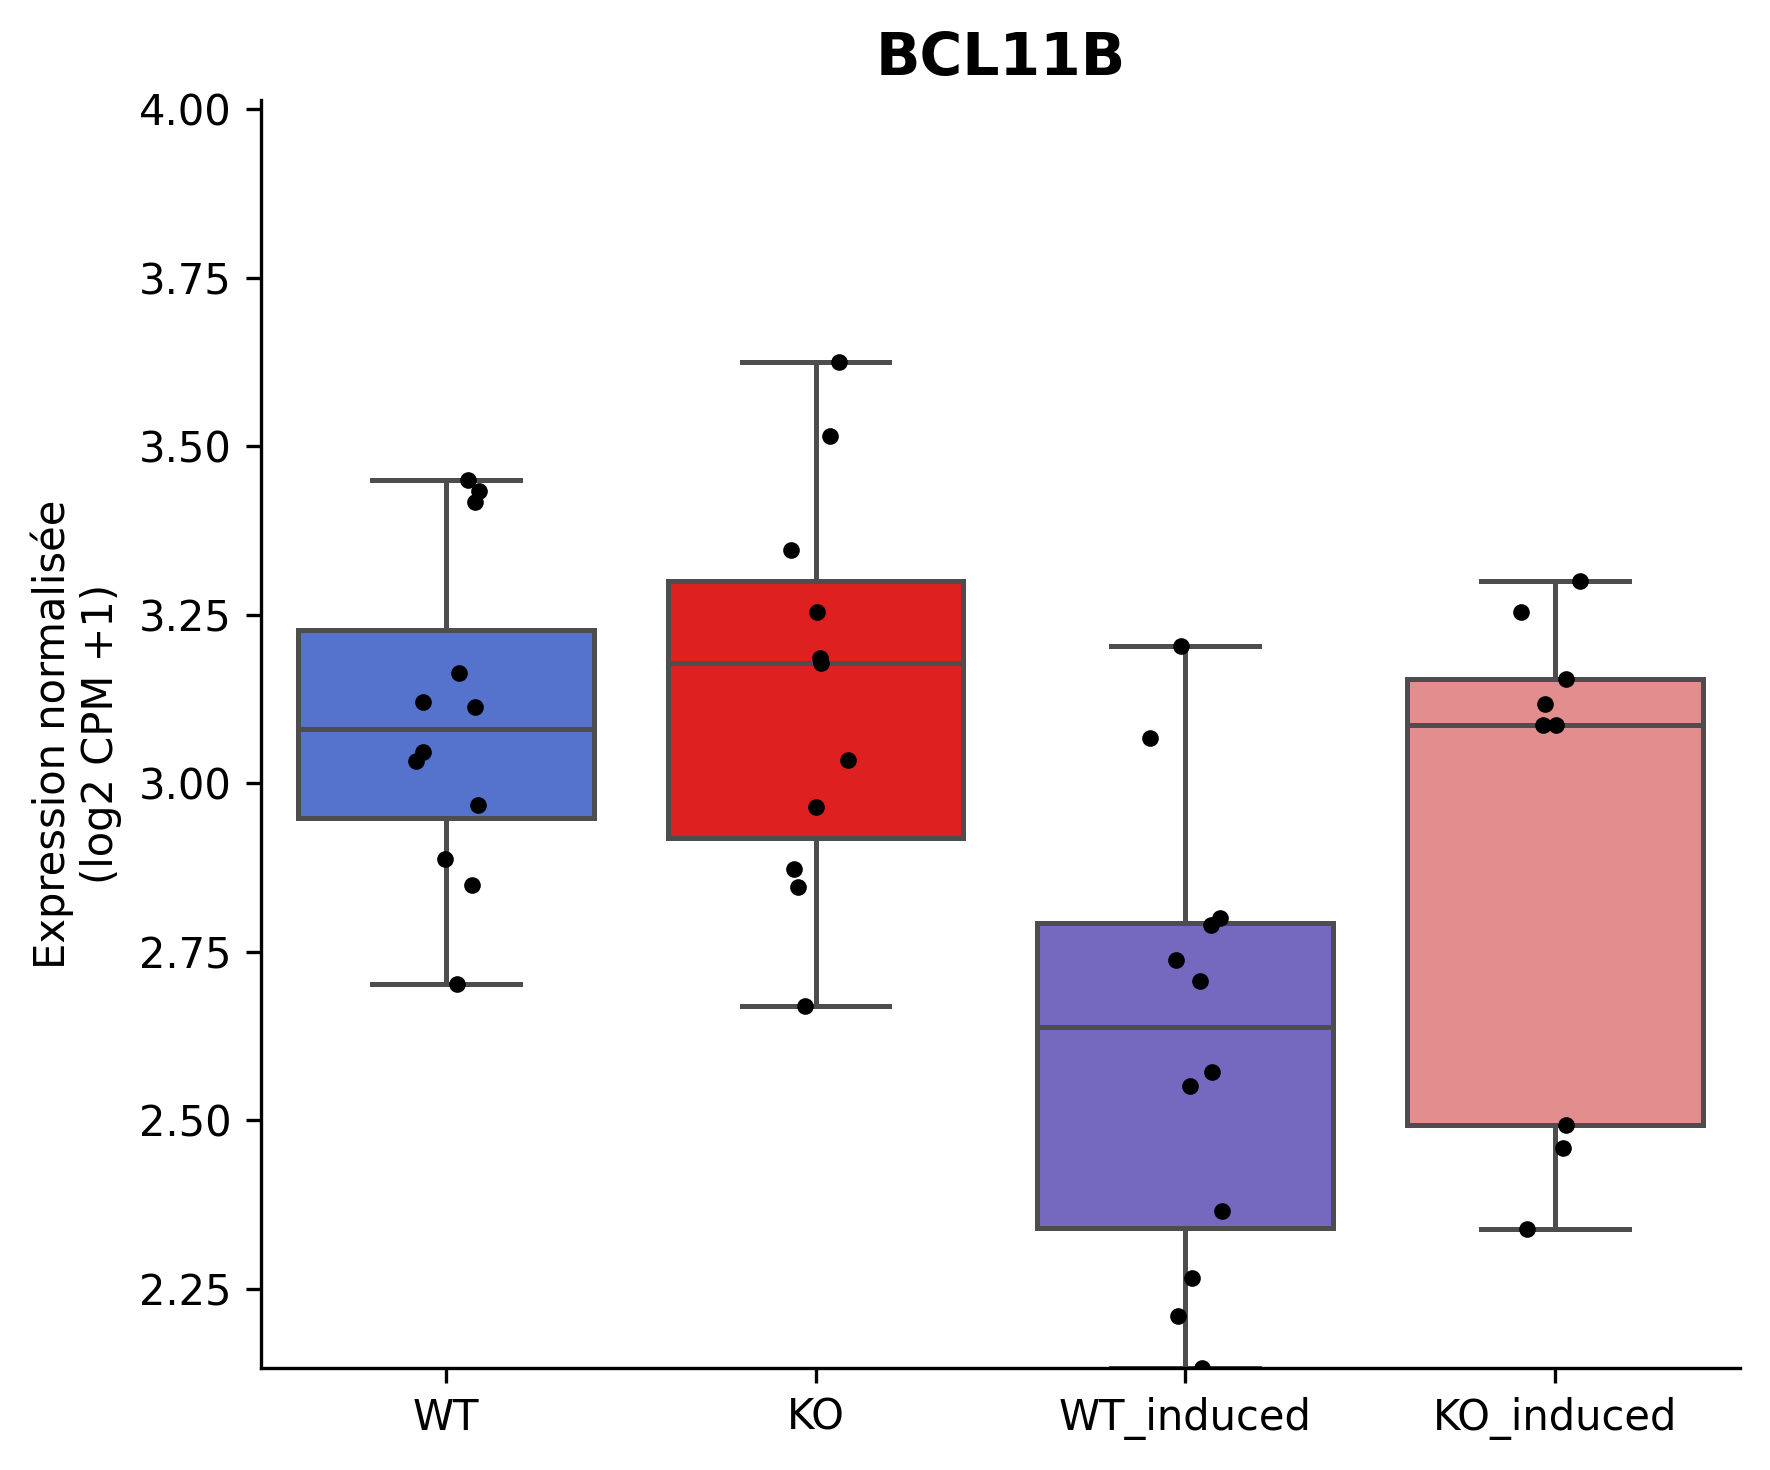

Plot : SATB2


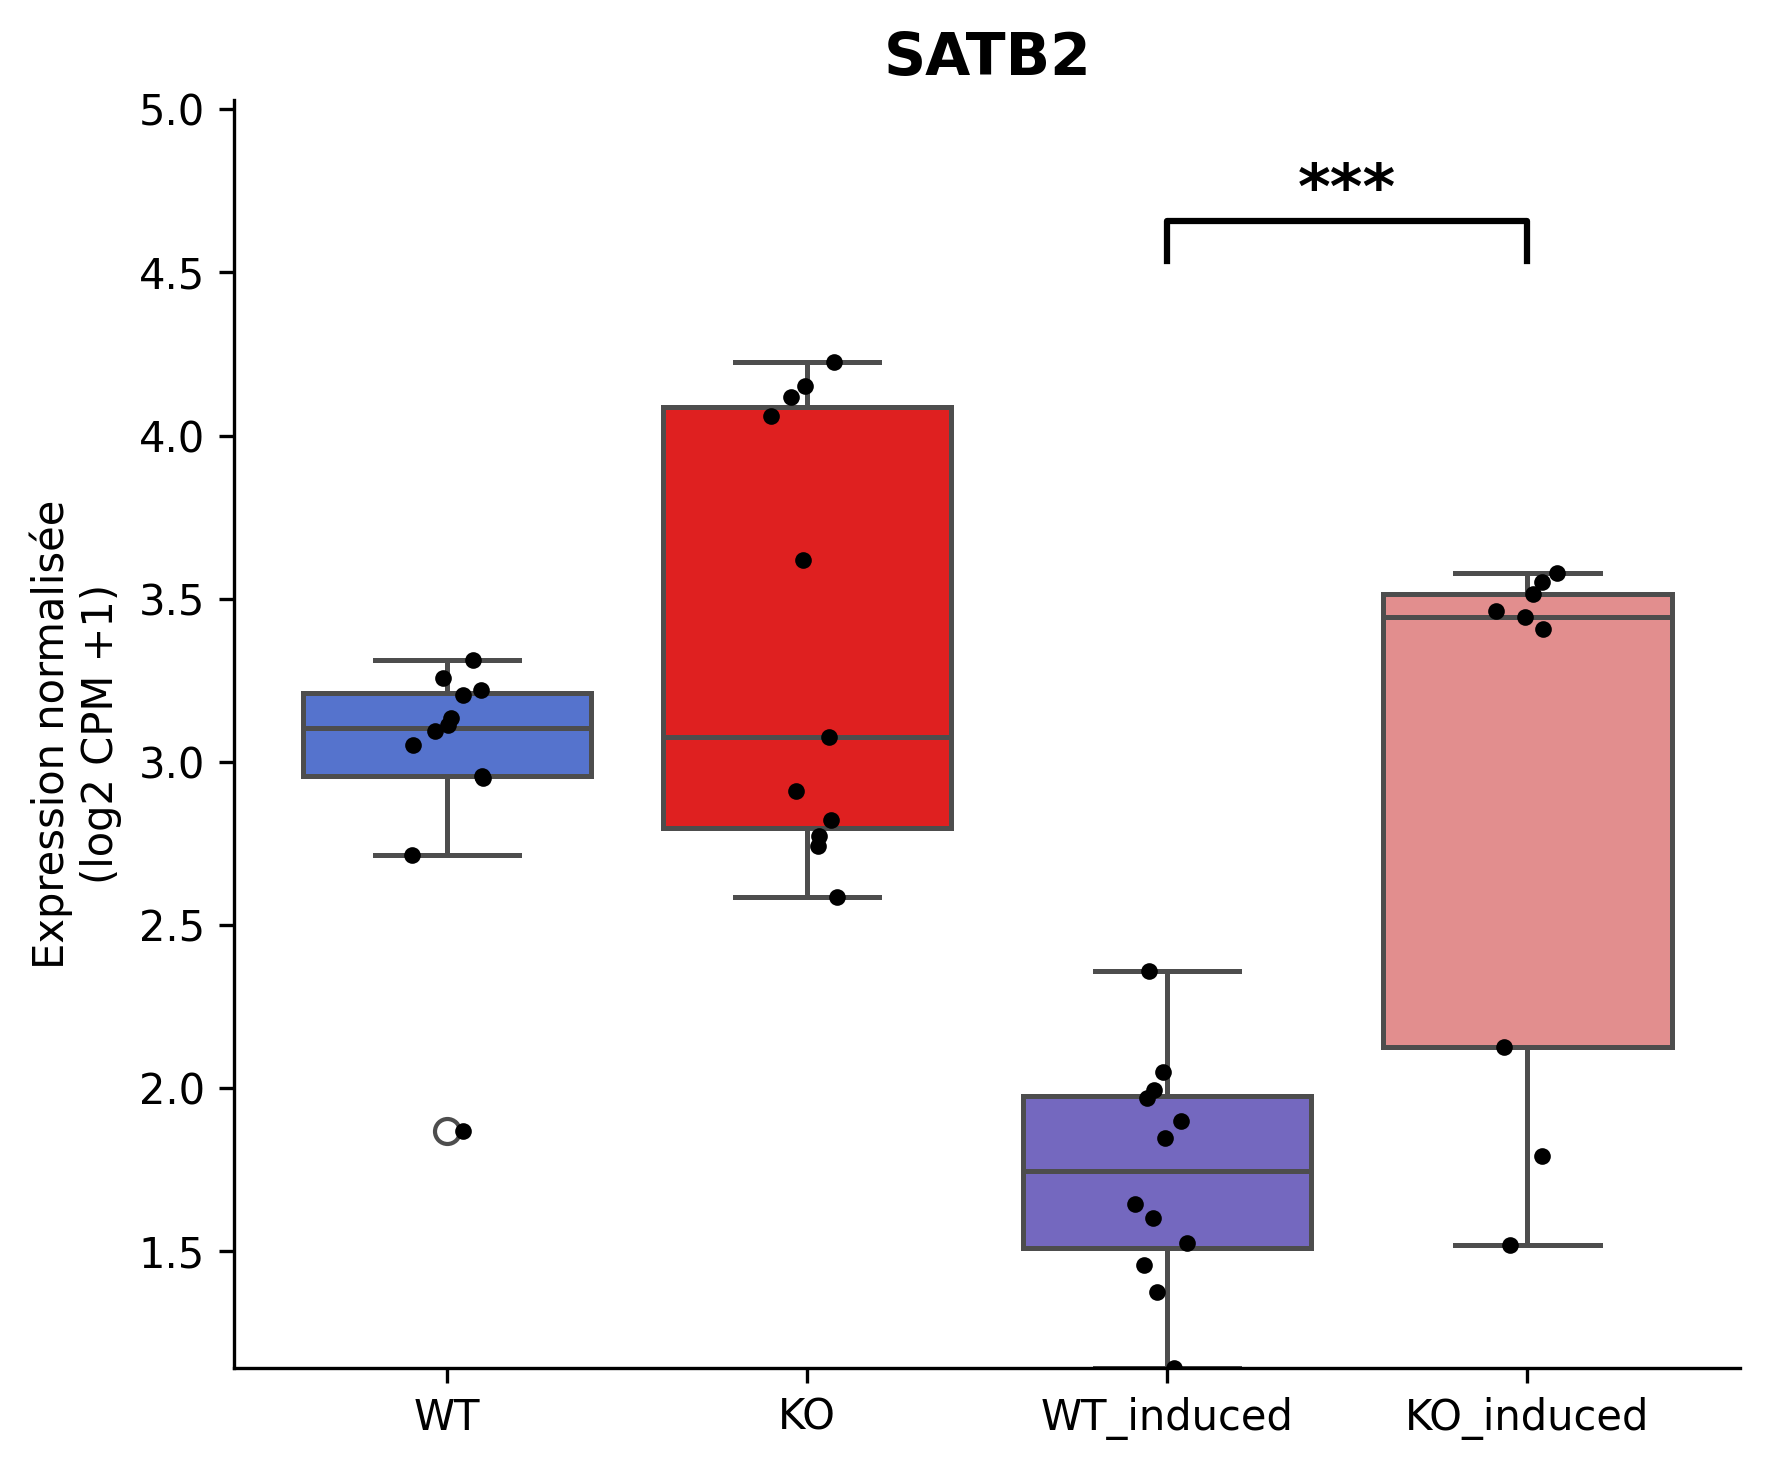

Plot : CUX1


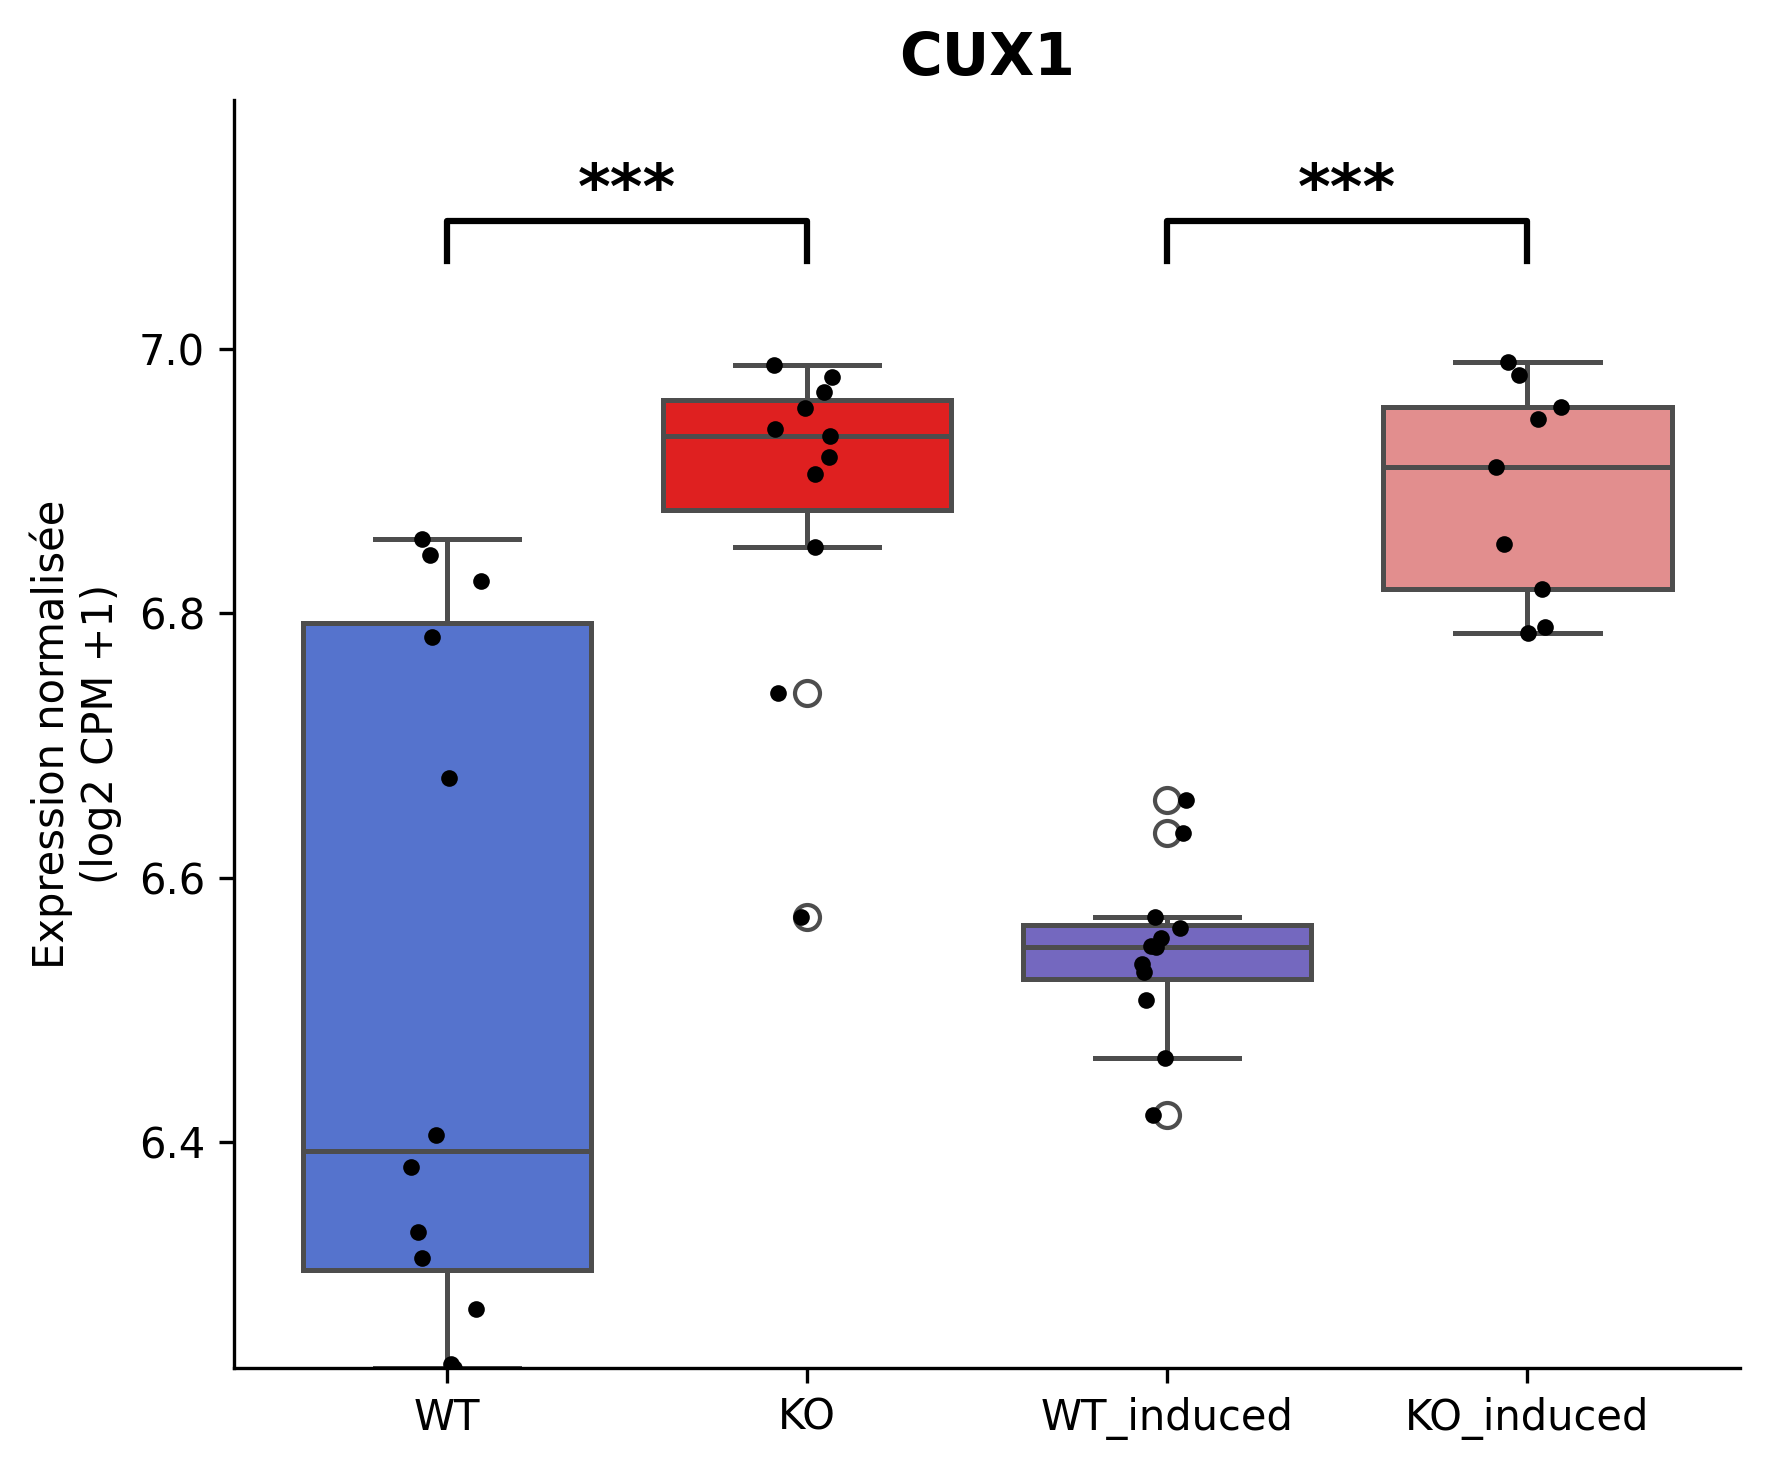

Plot : MBP


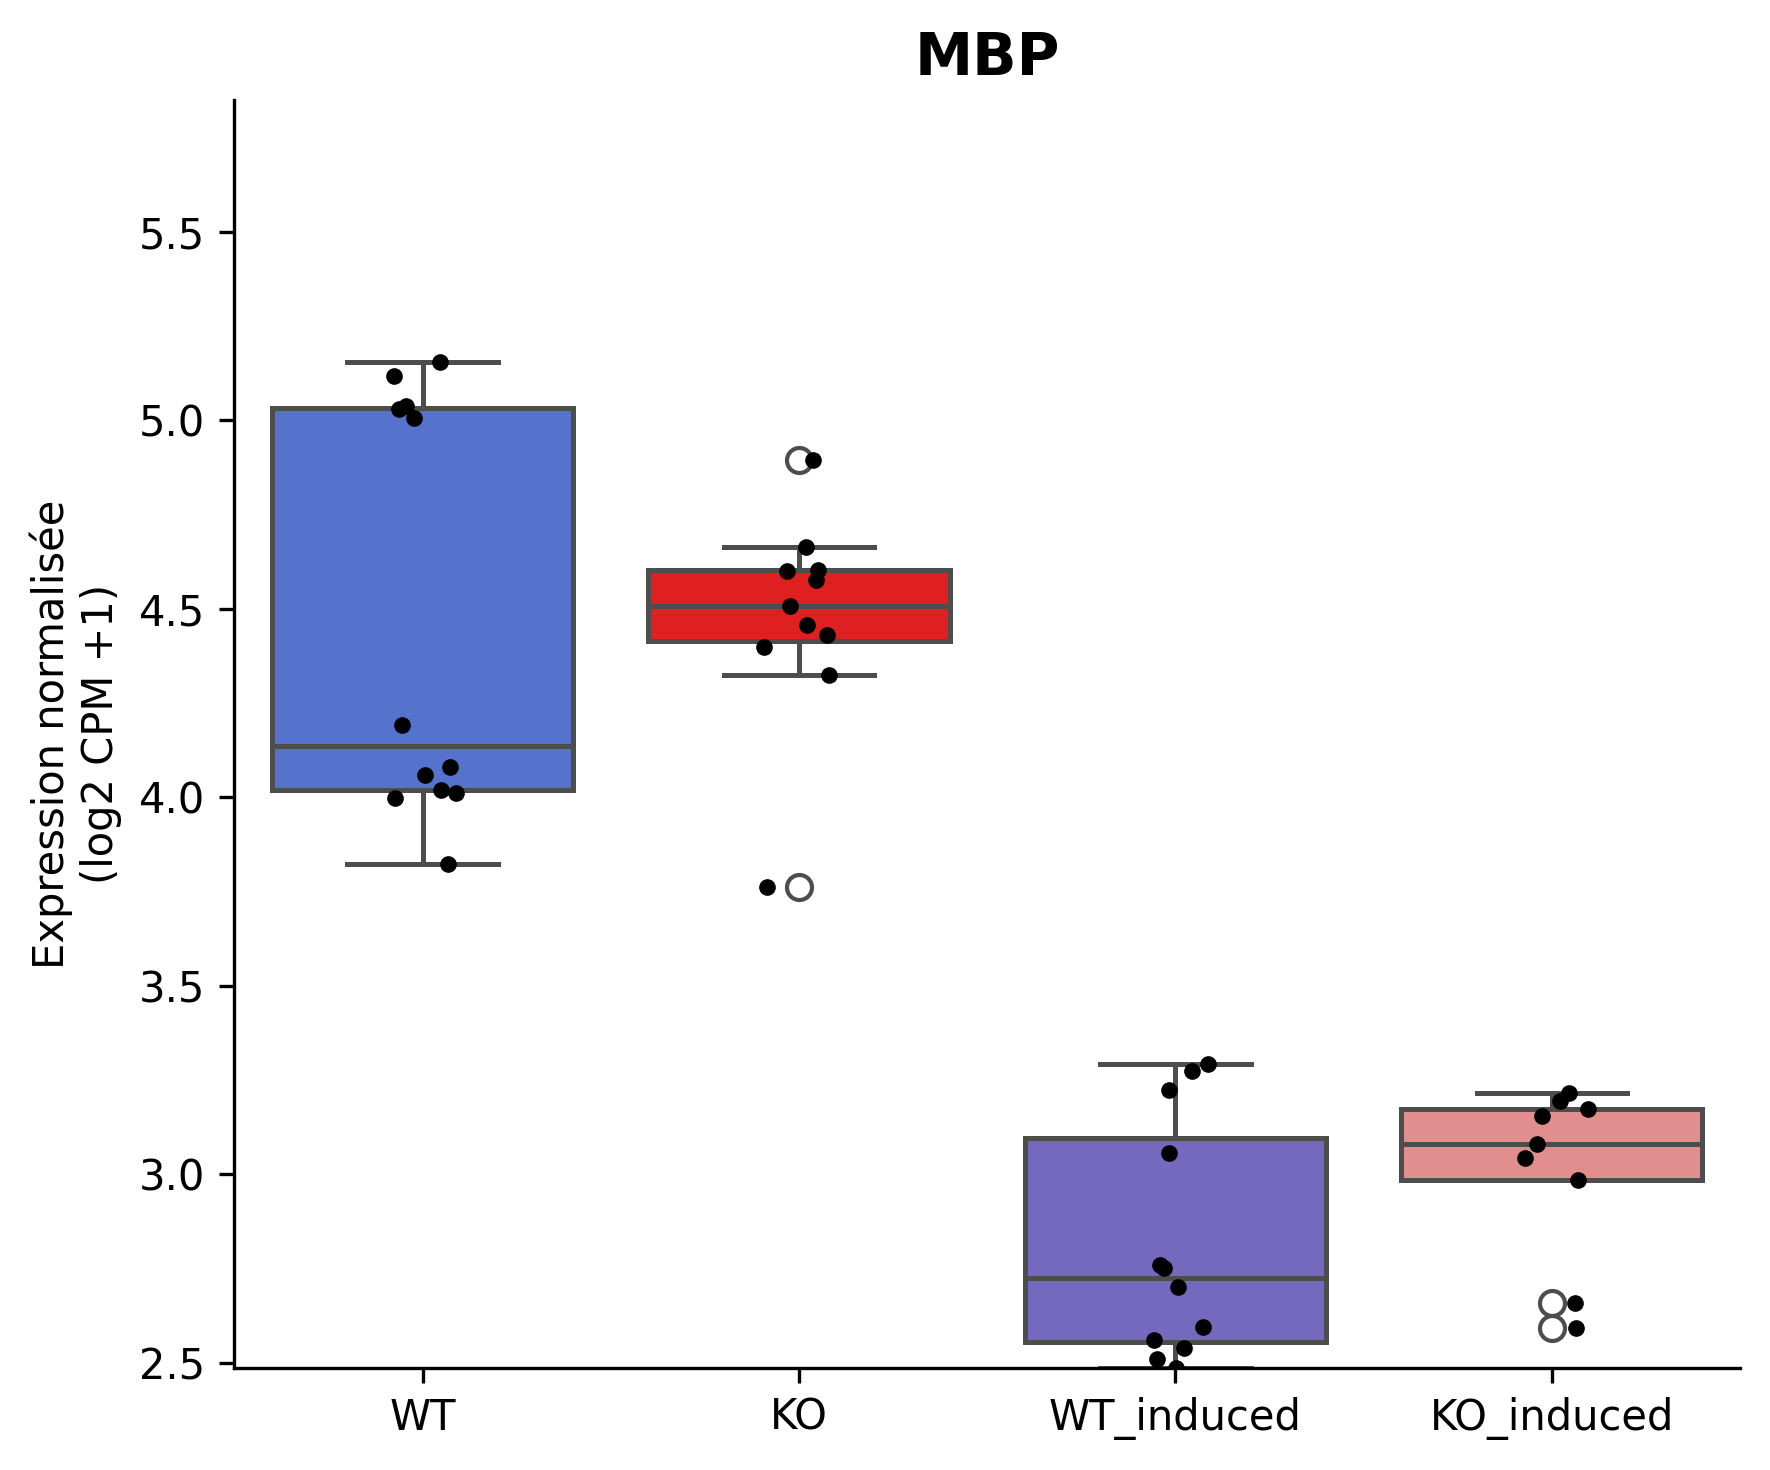

Plot : PRDM1


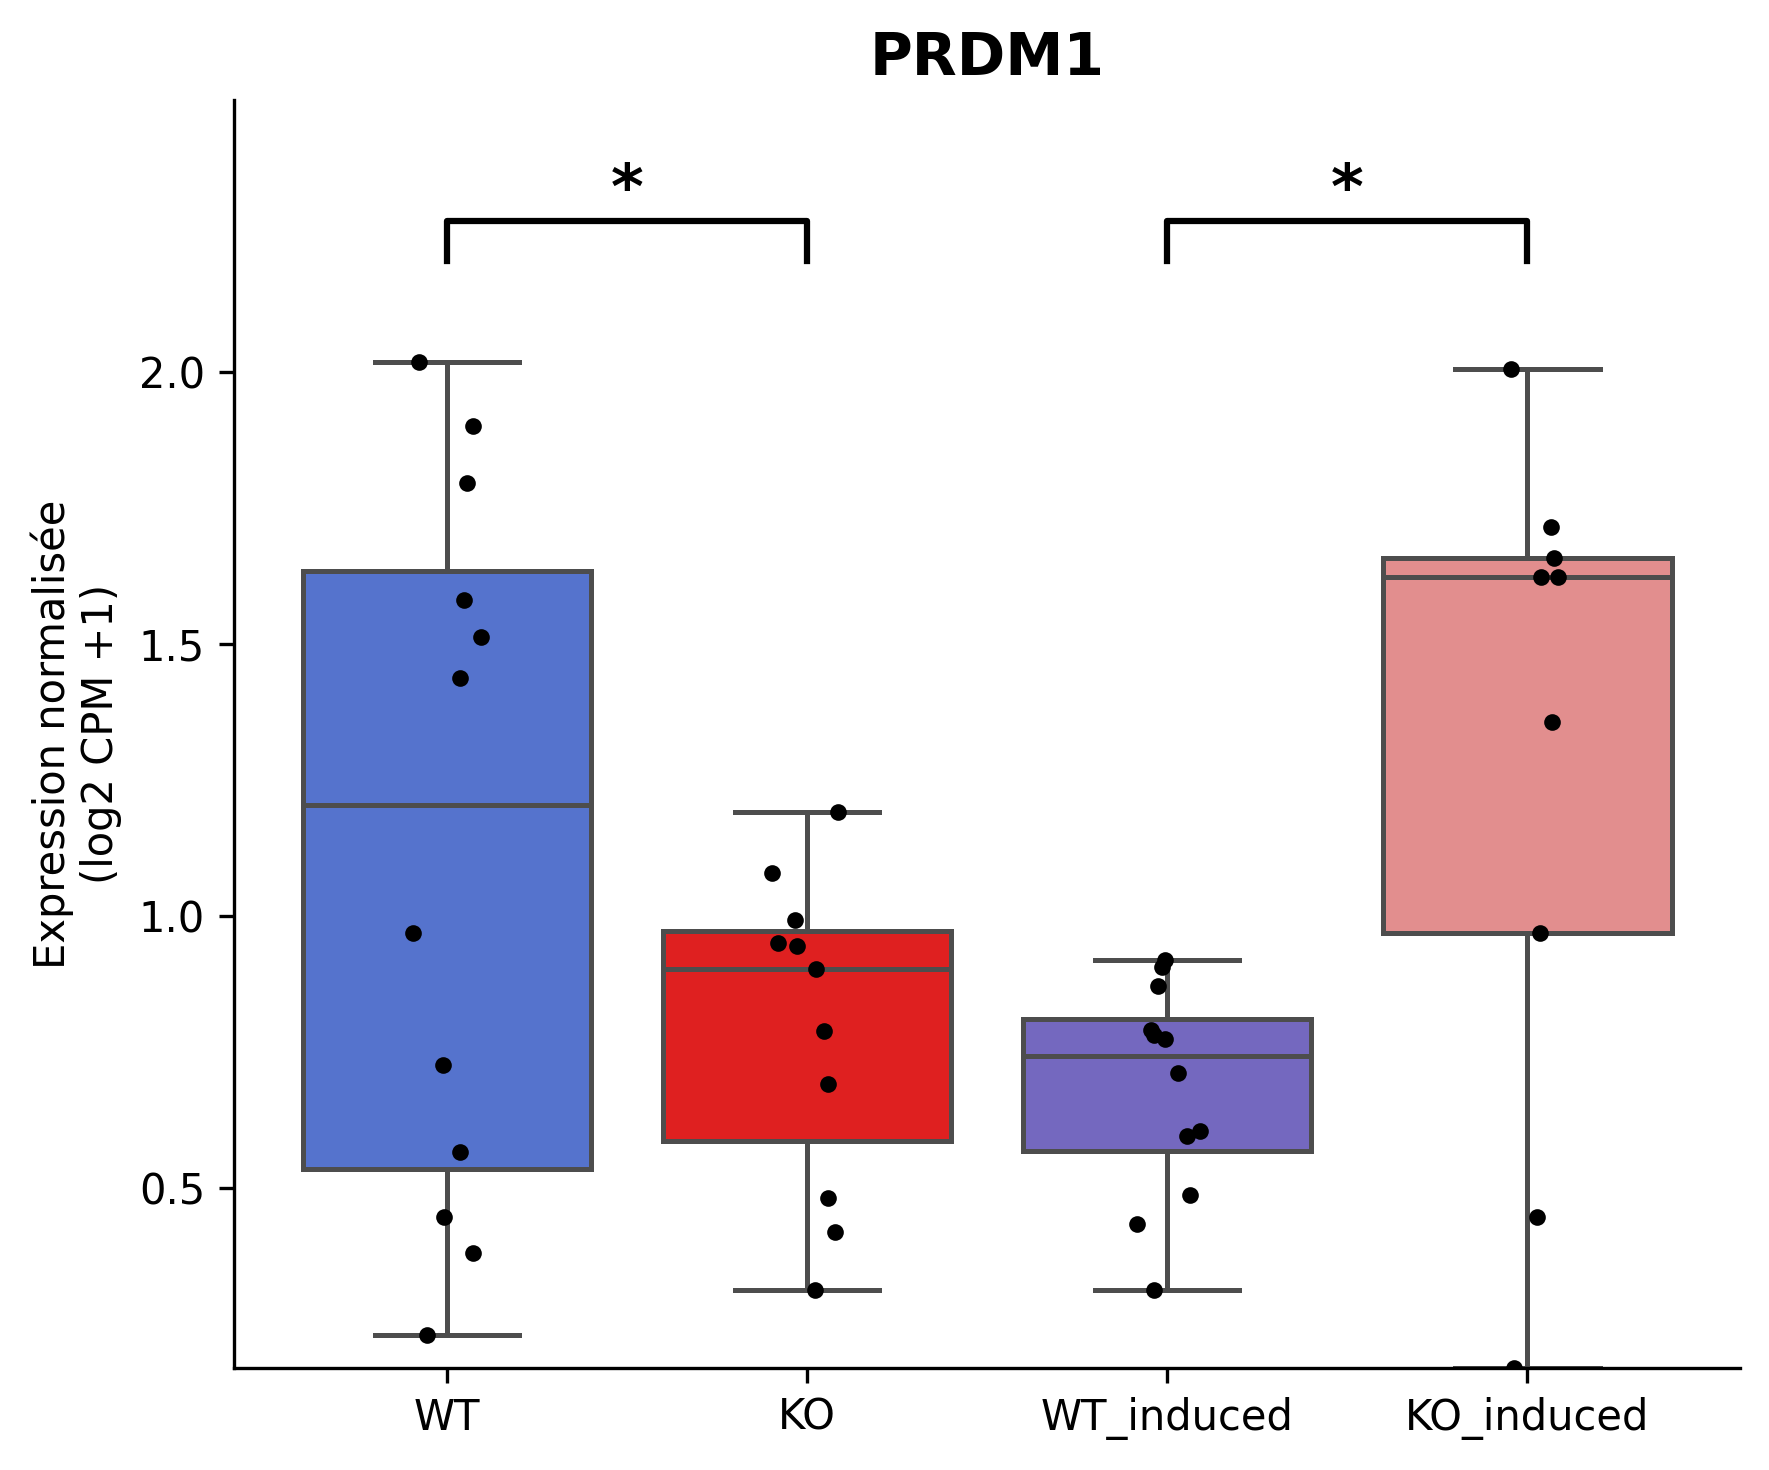

Plot : RAX


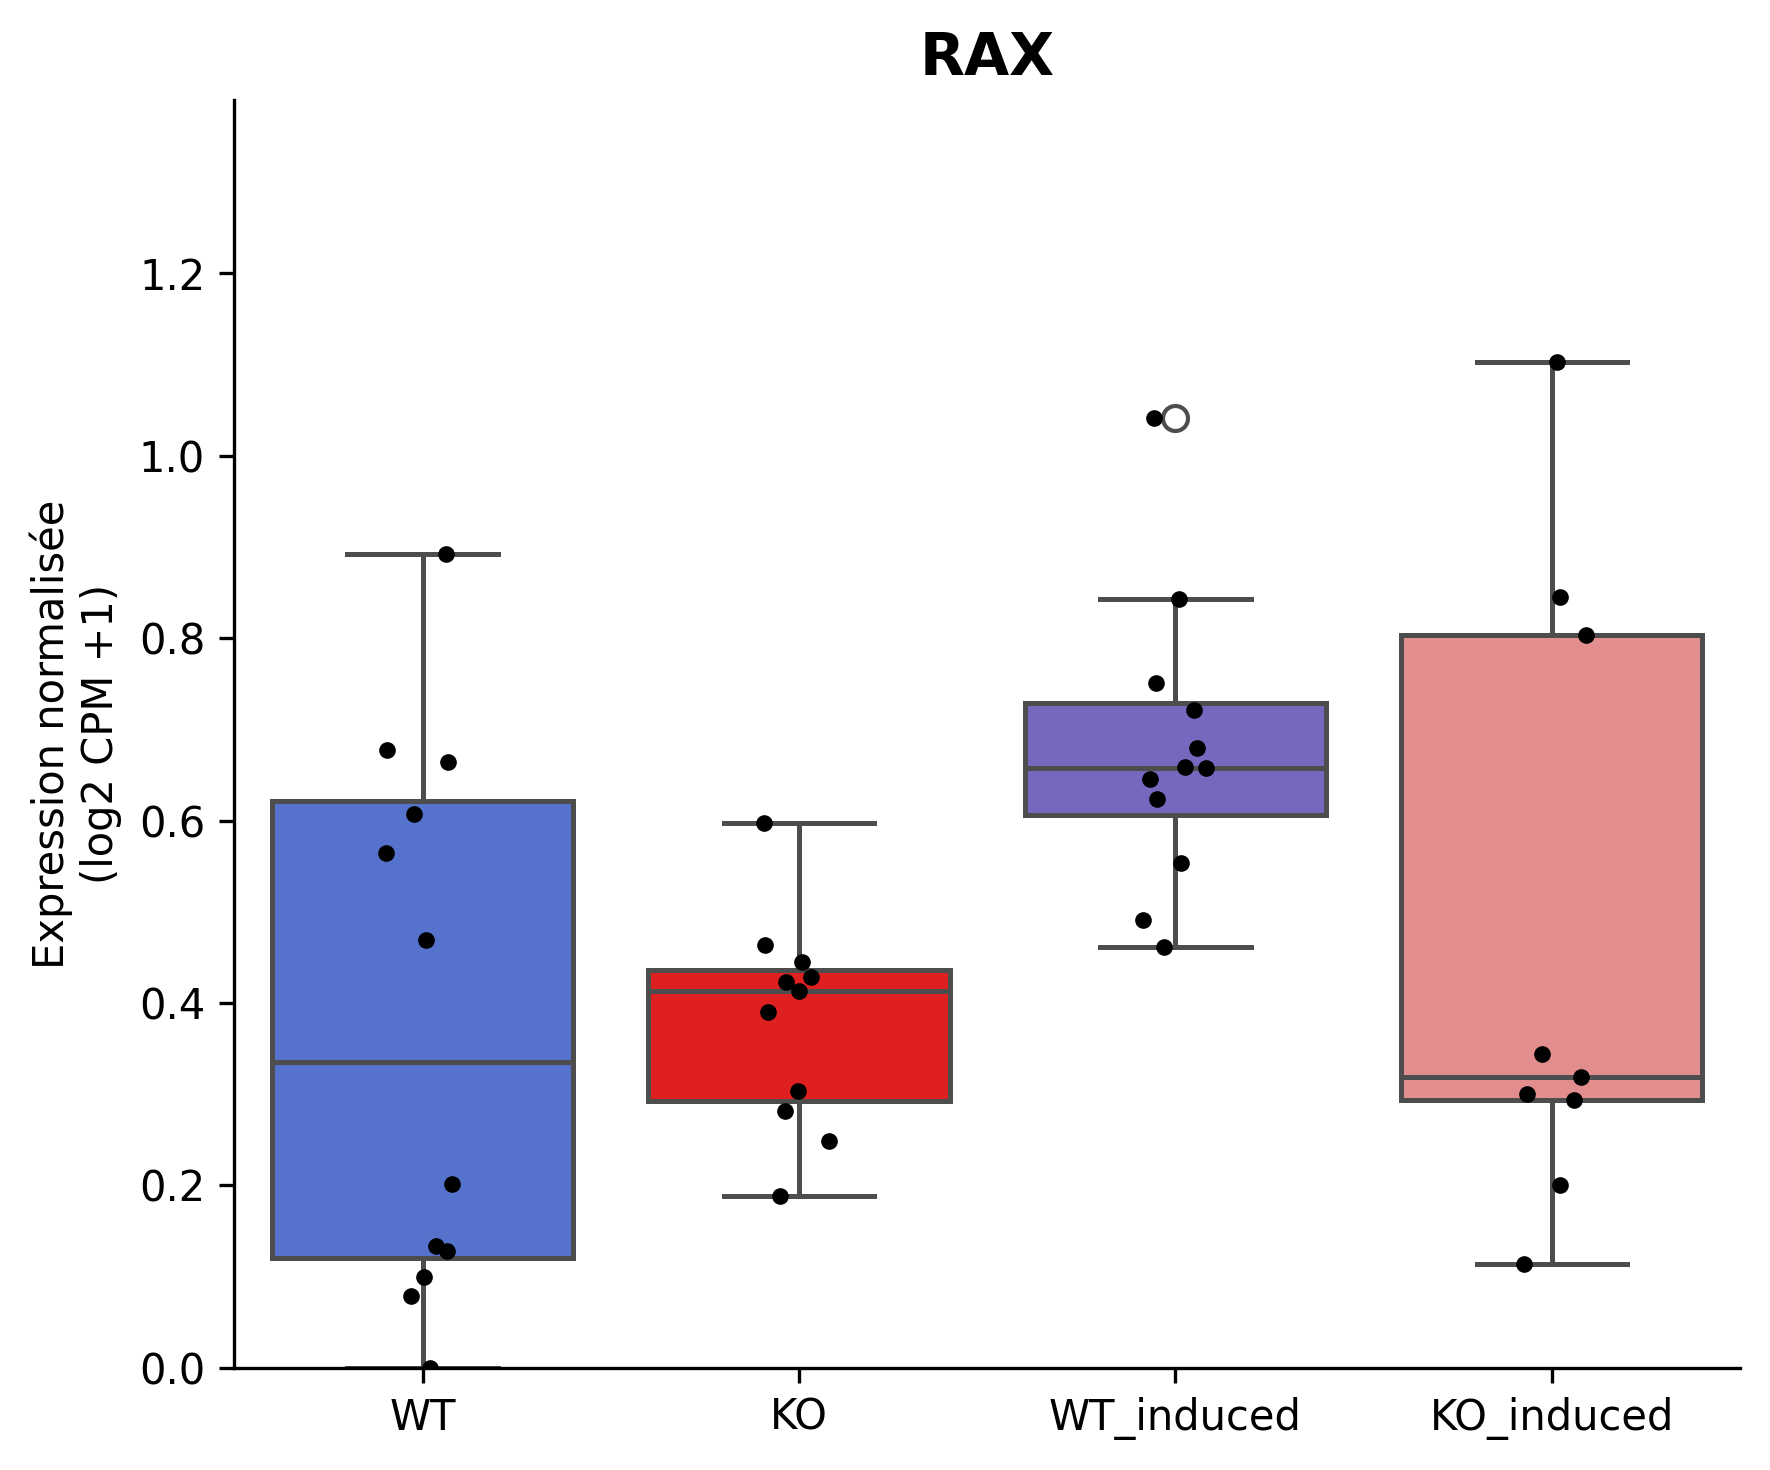

Plot : VSX2


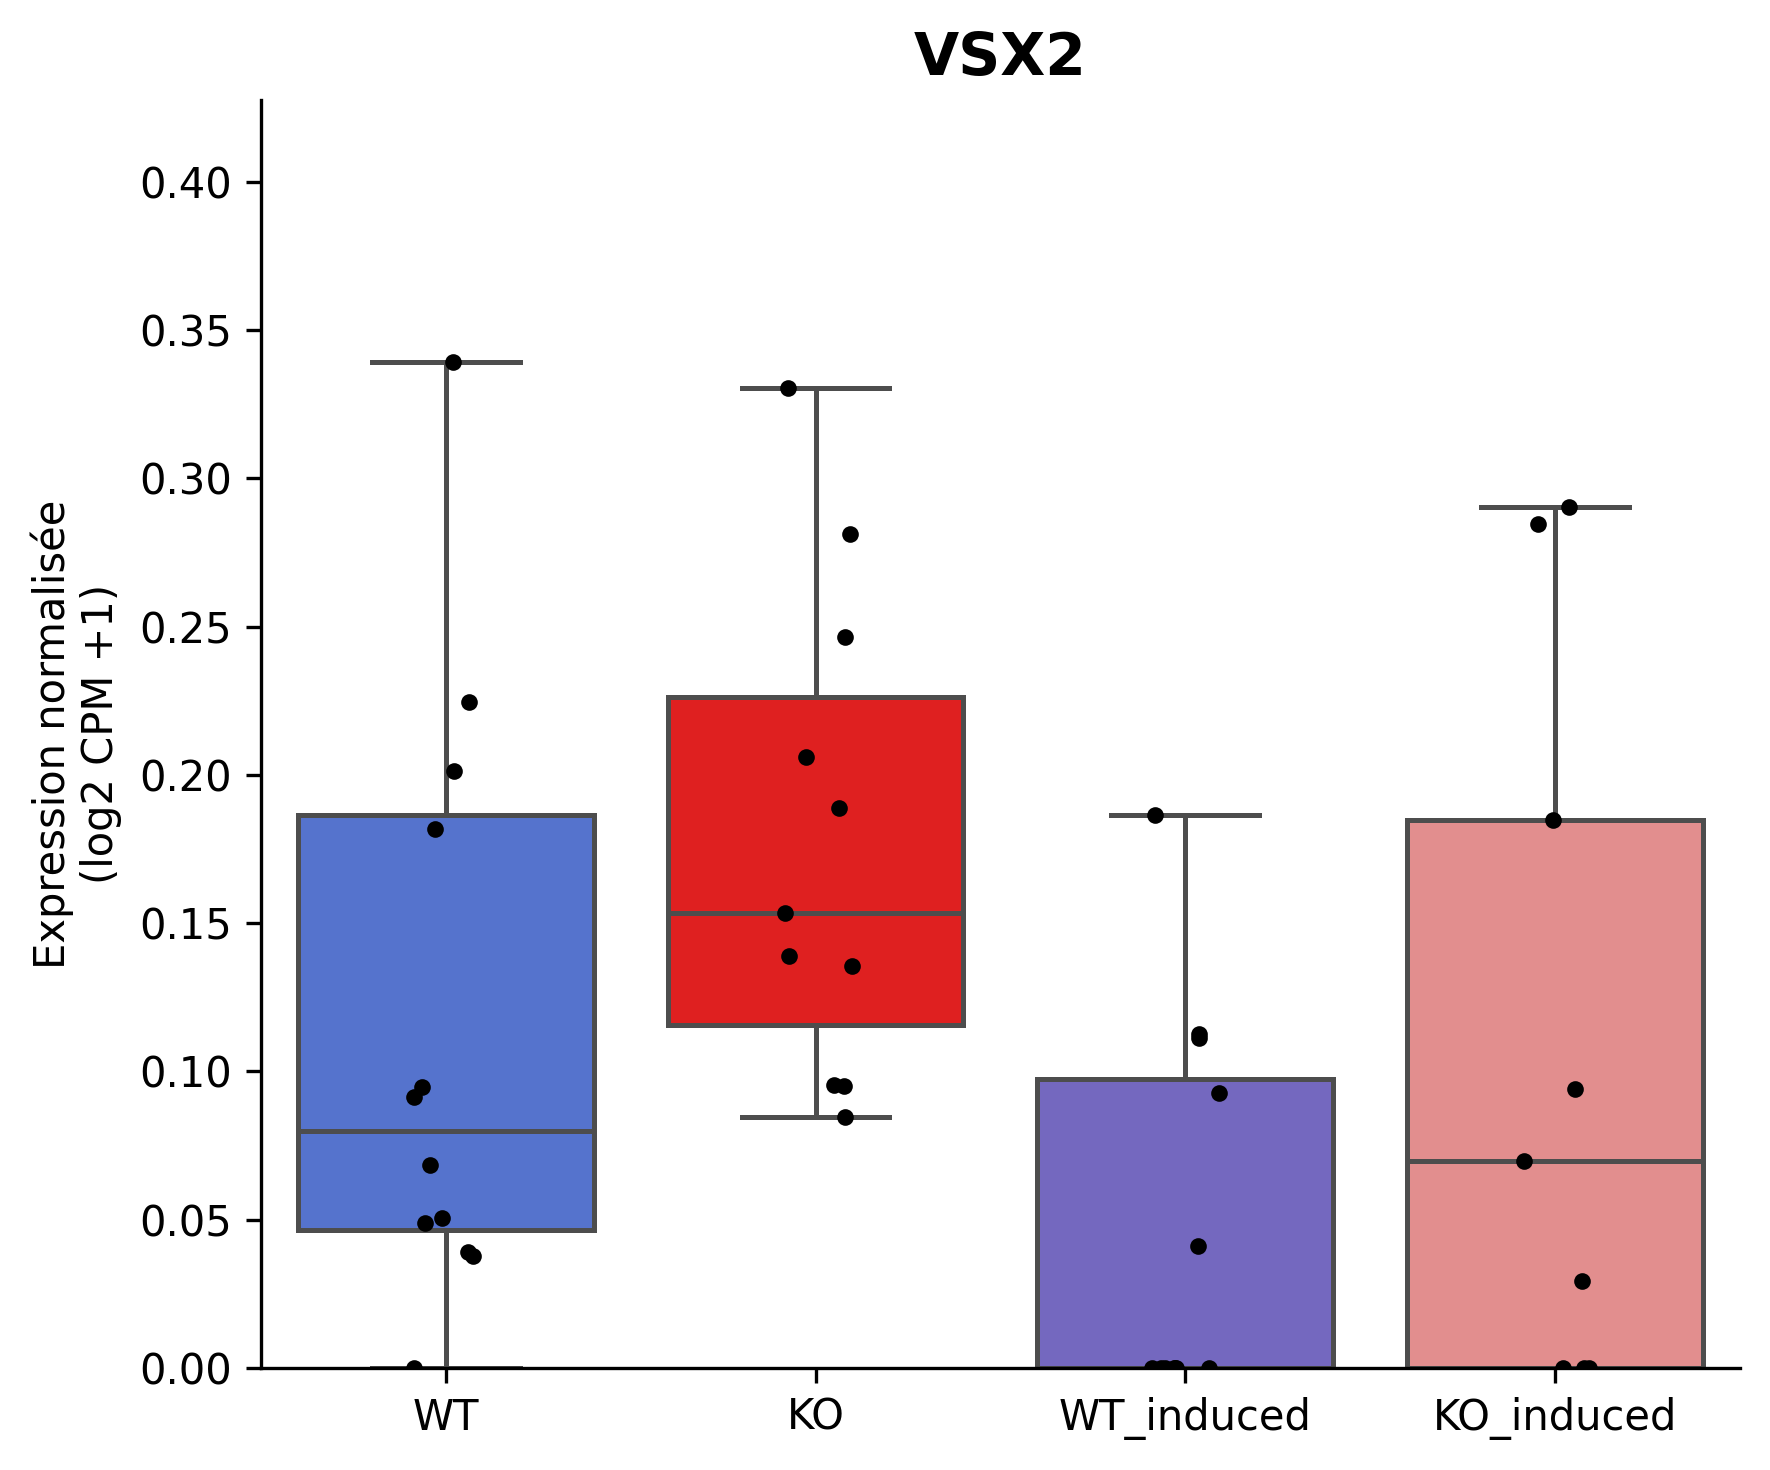

Plot : OTX2


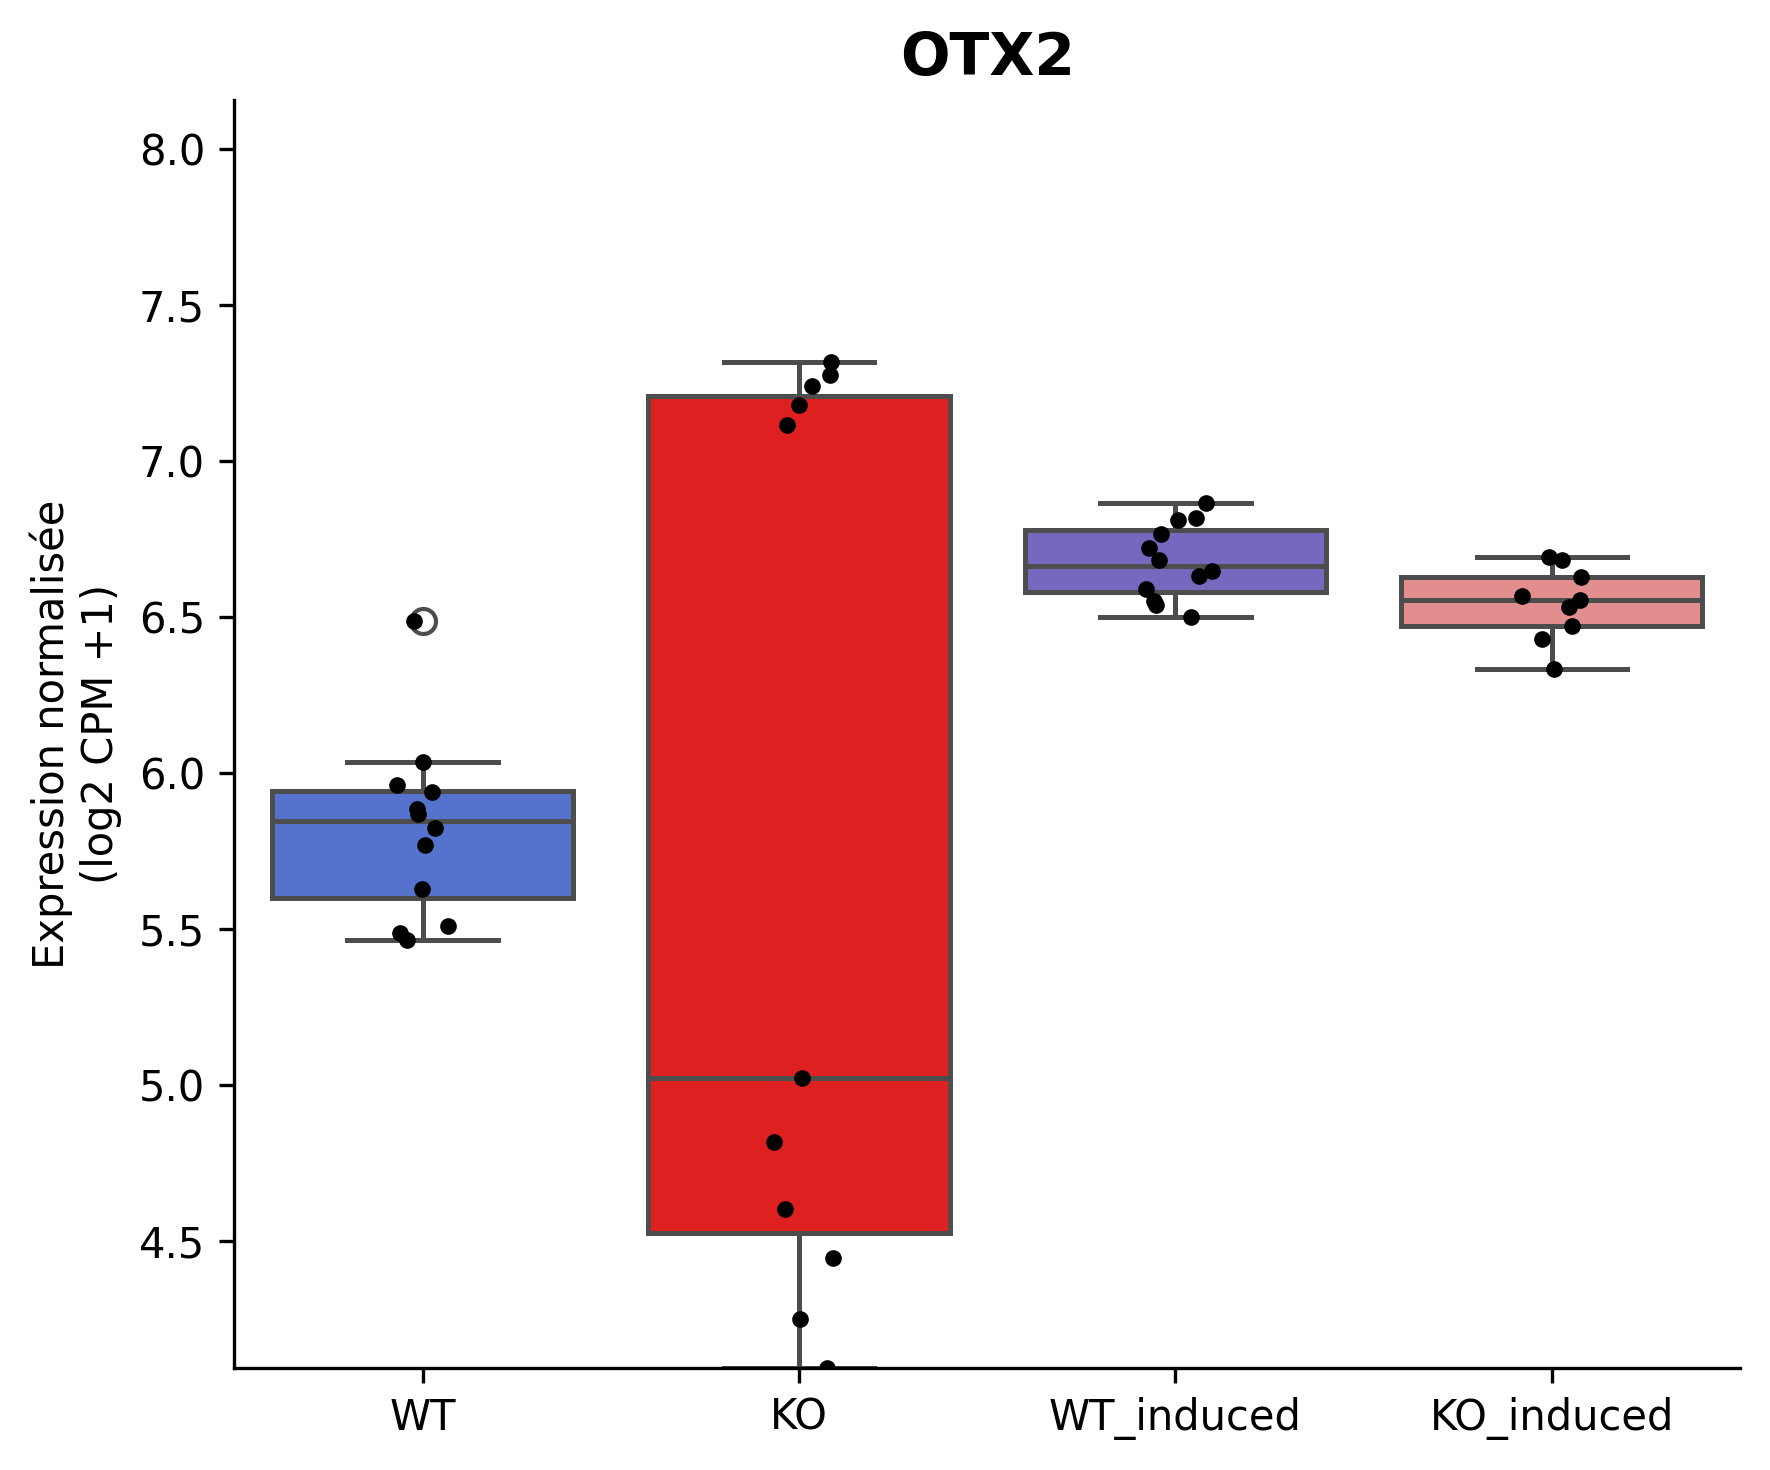

Plot : CRX


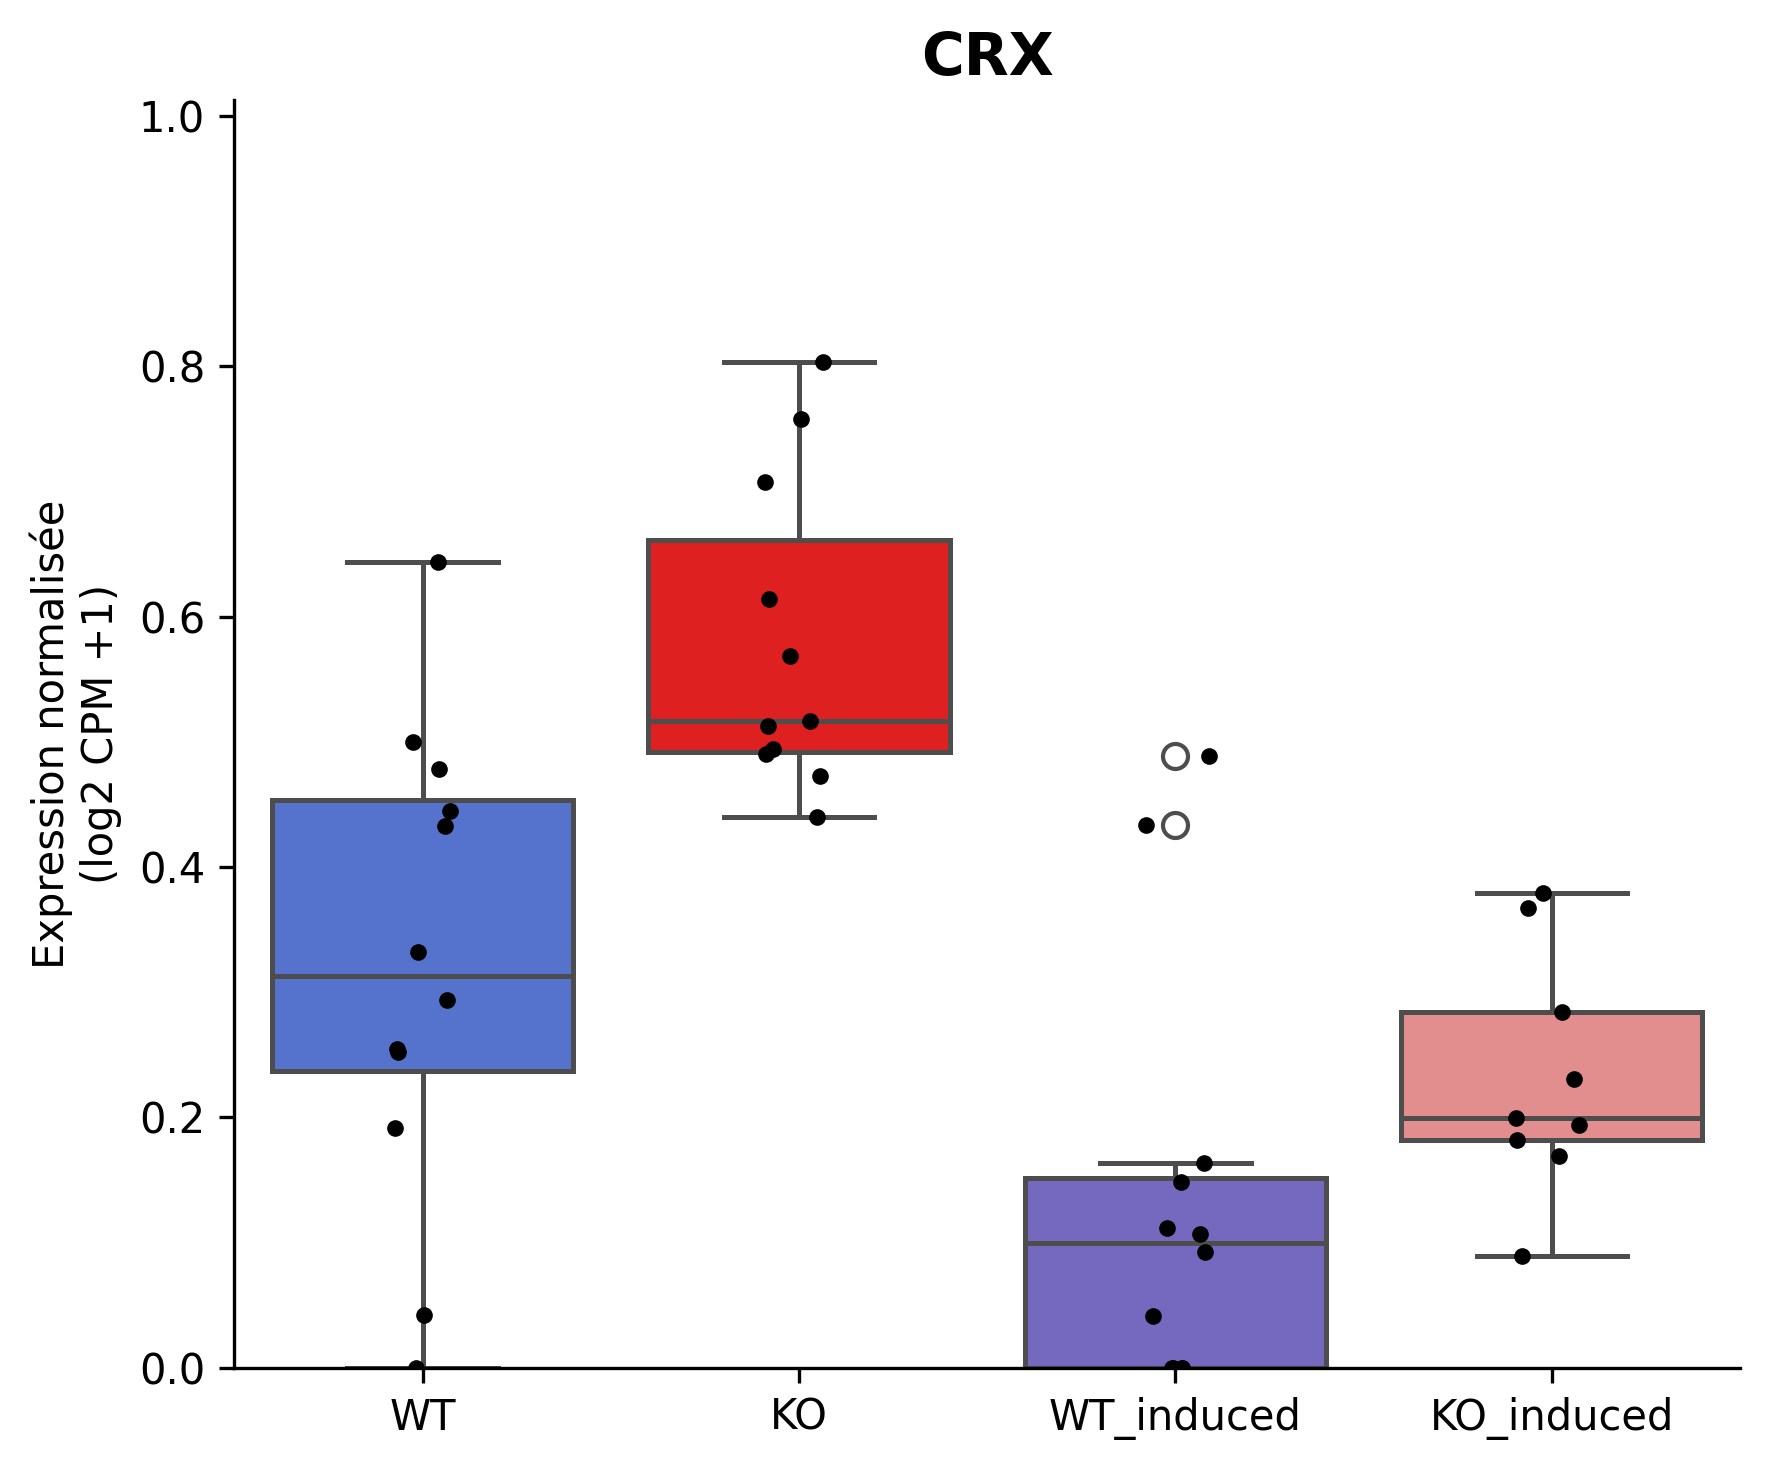

Plot : NEUROD1


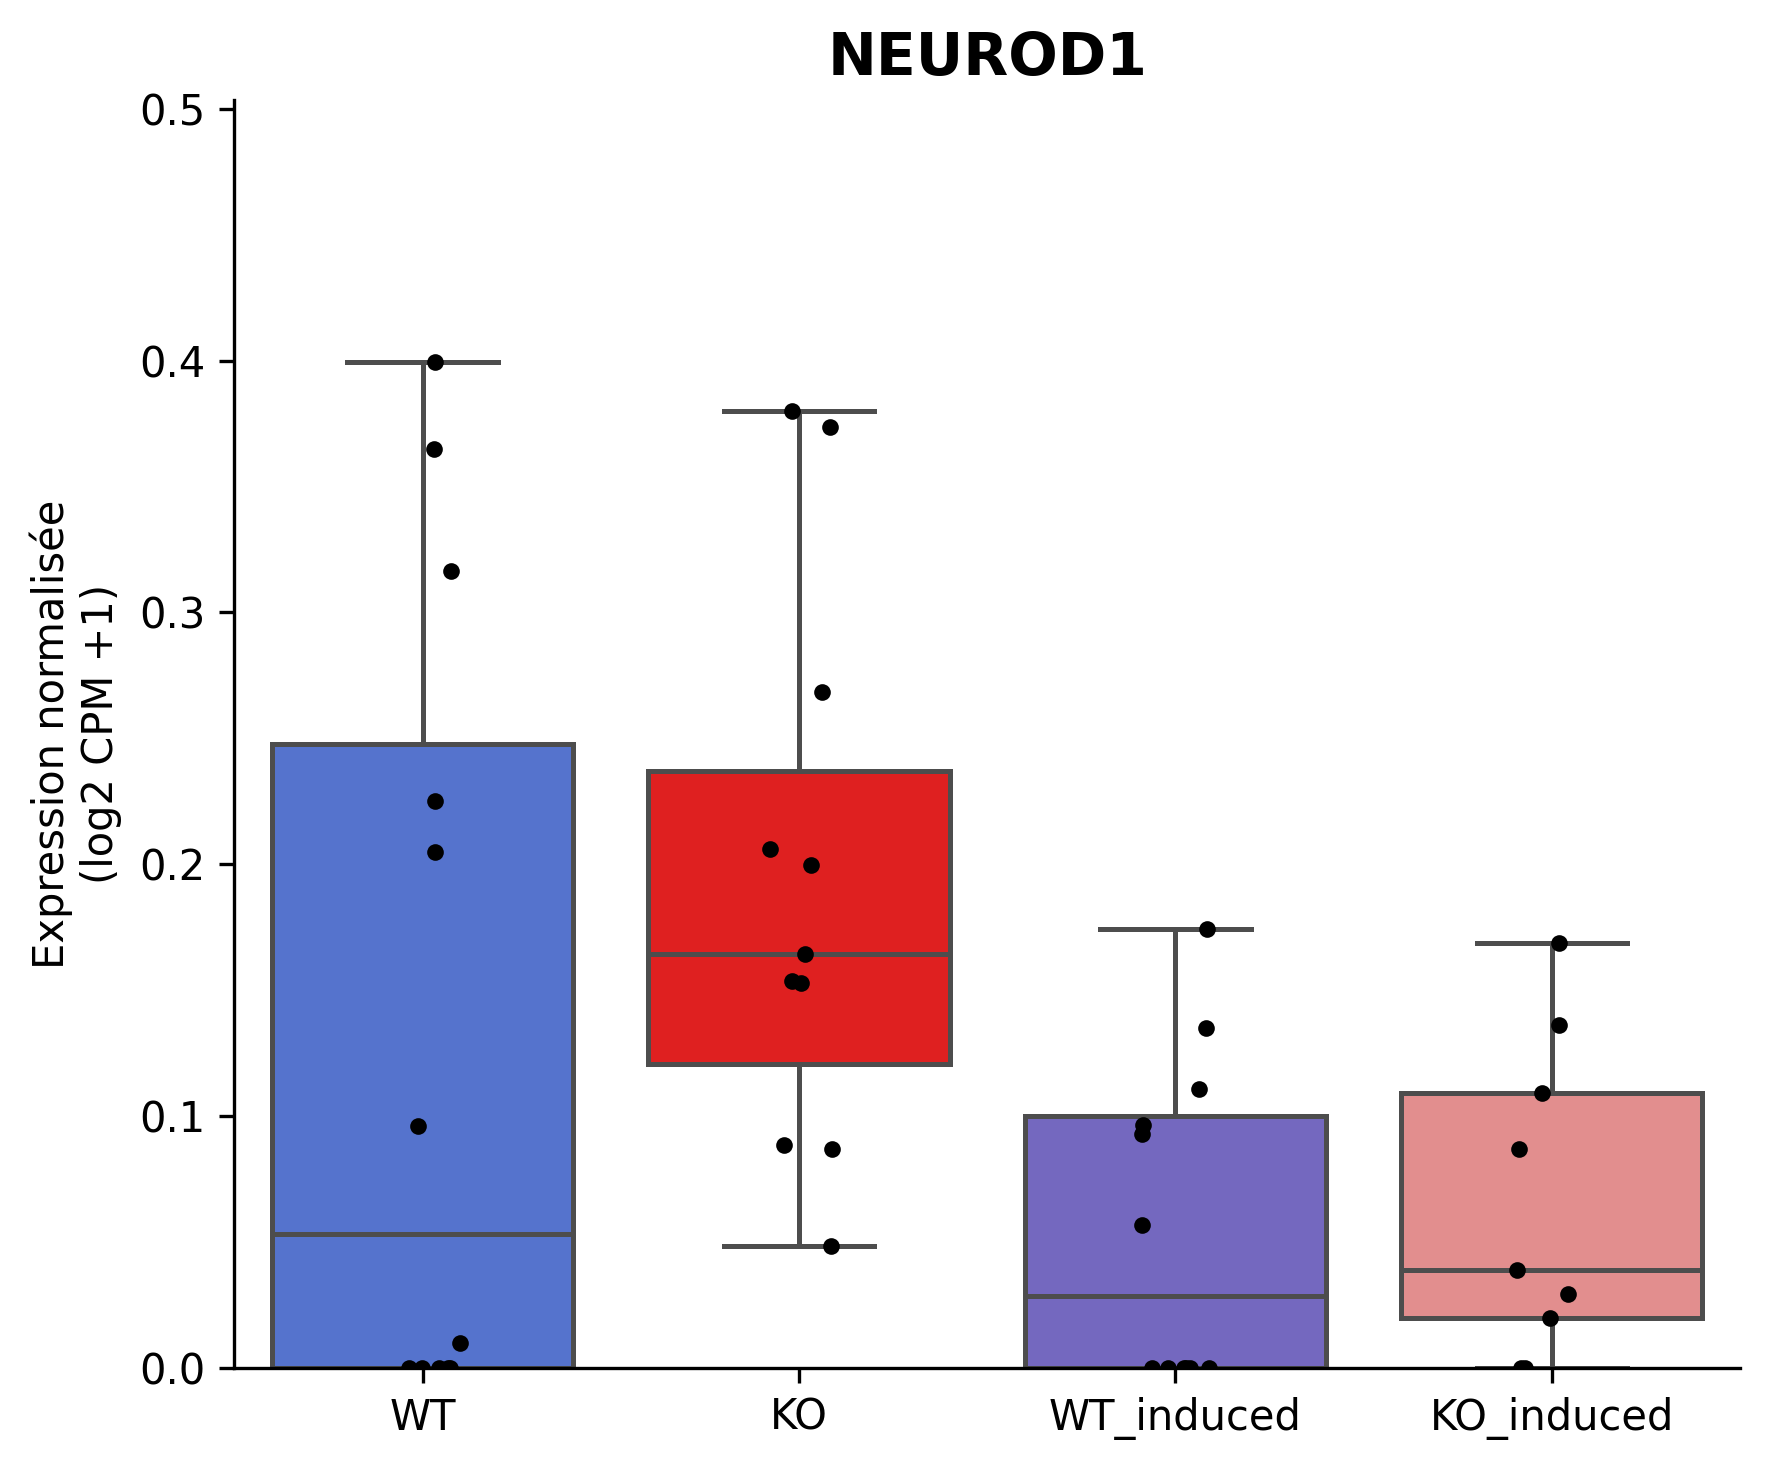

Plot : RCVRN


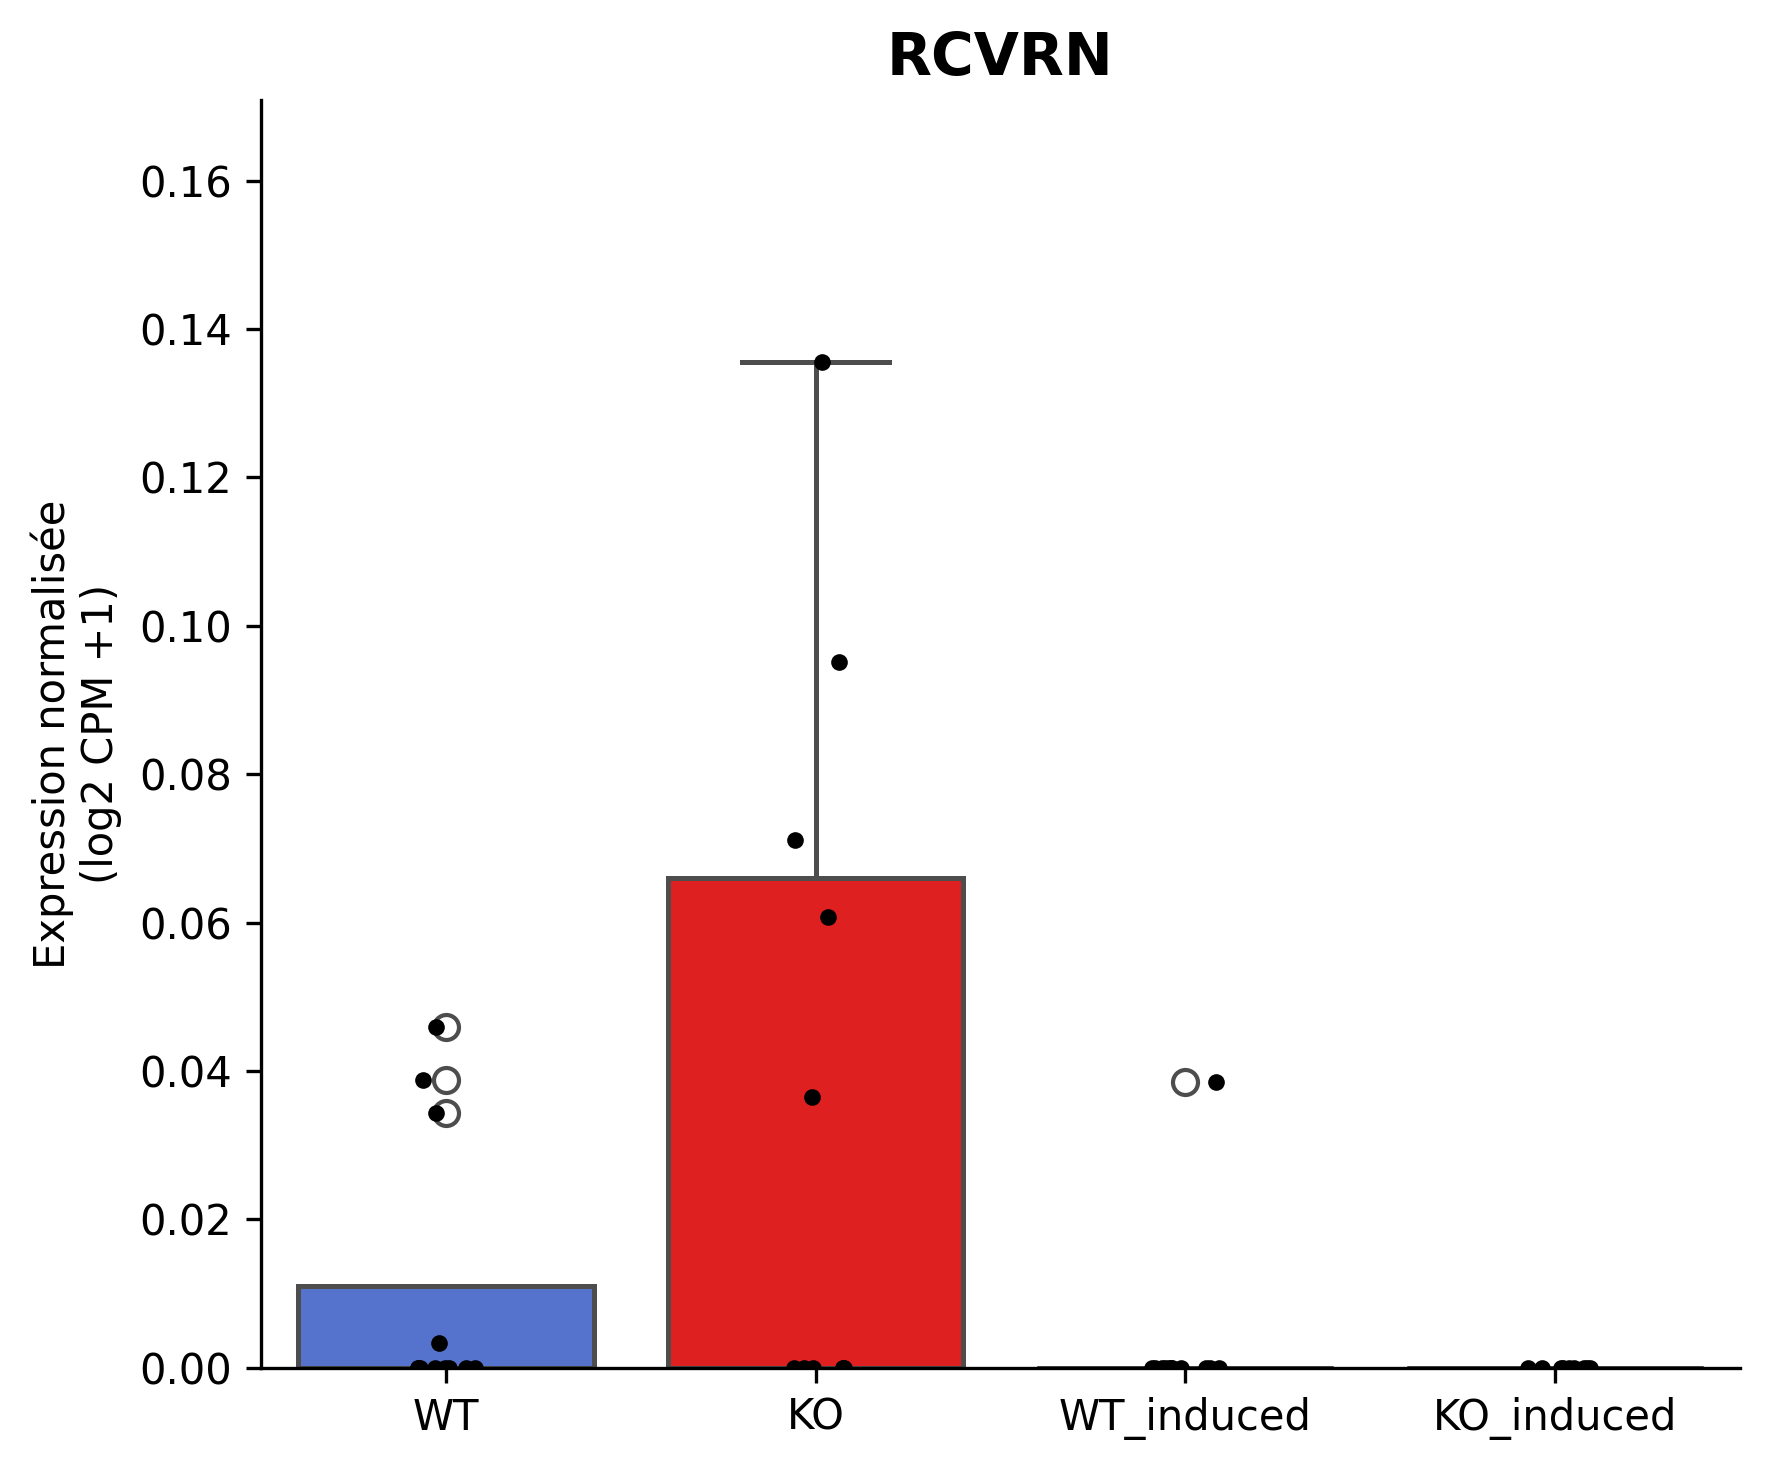

Plot : RORB


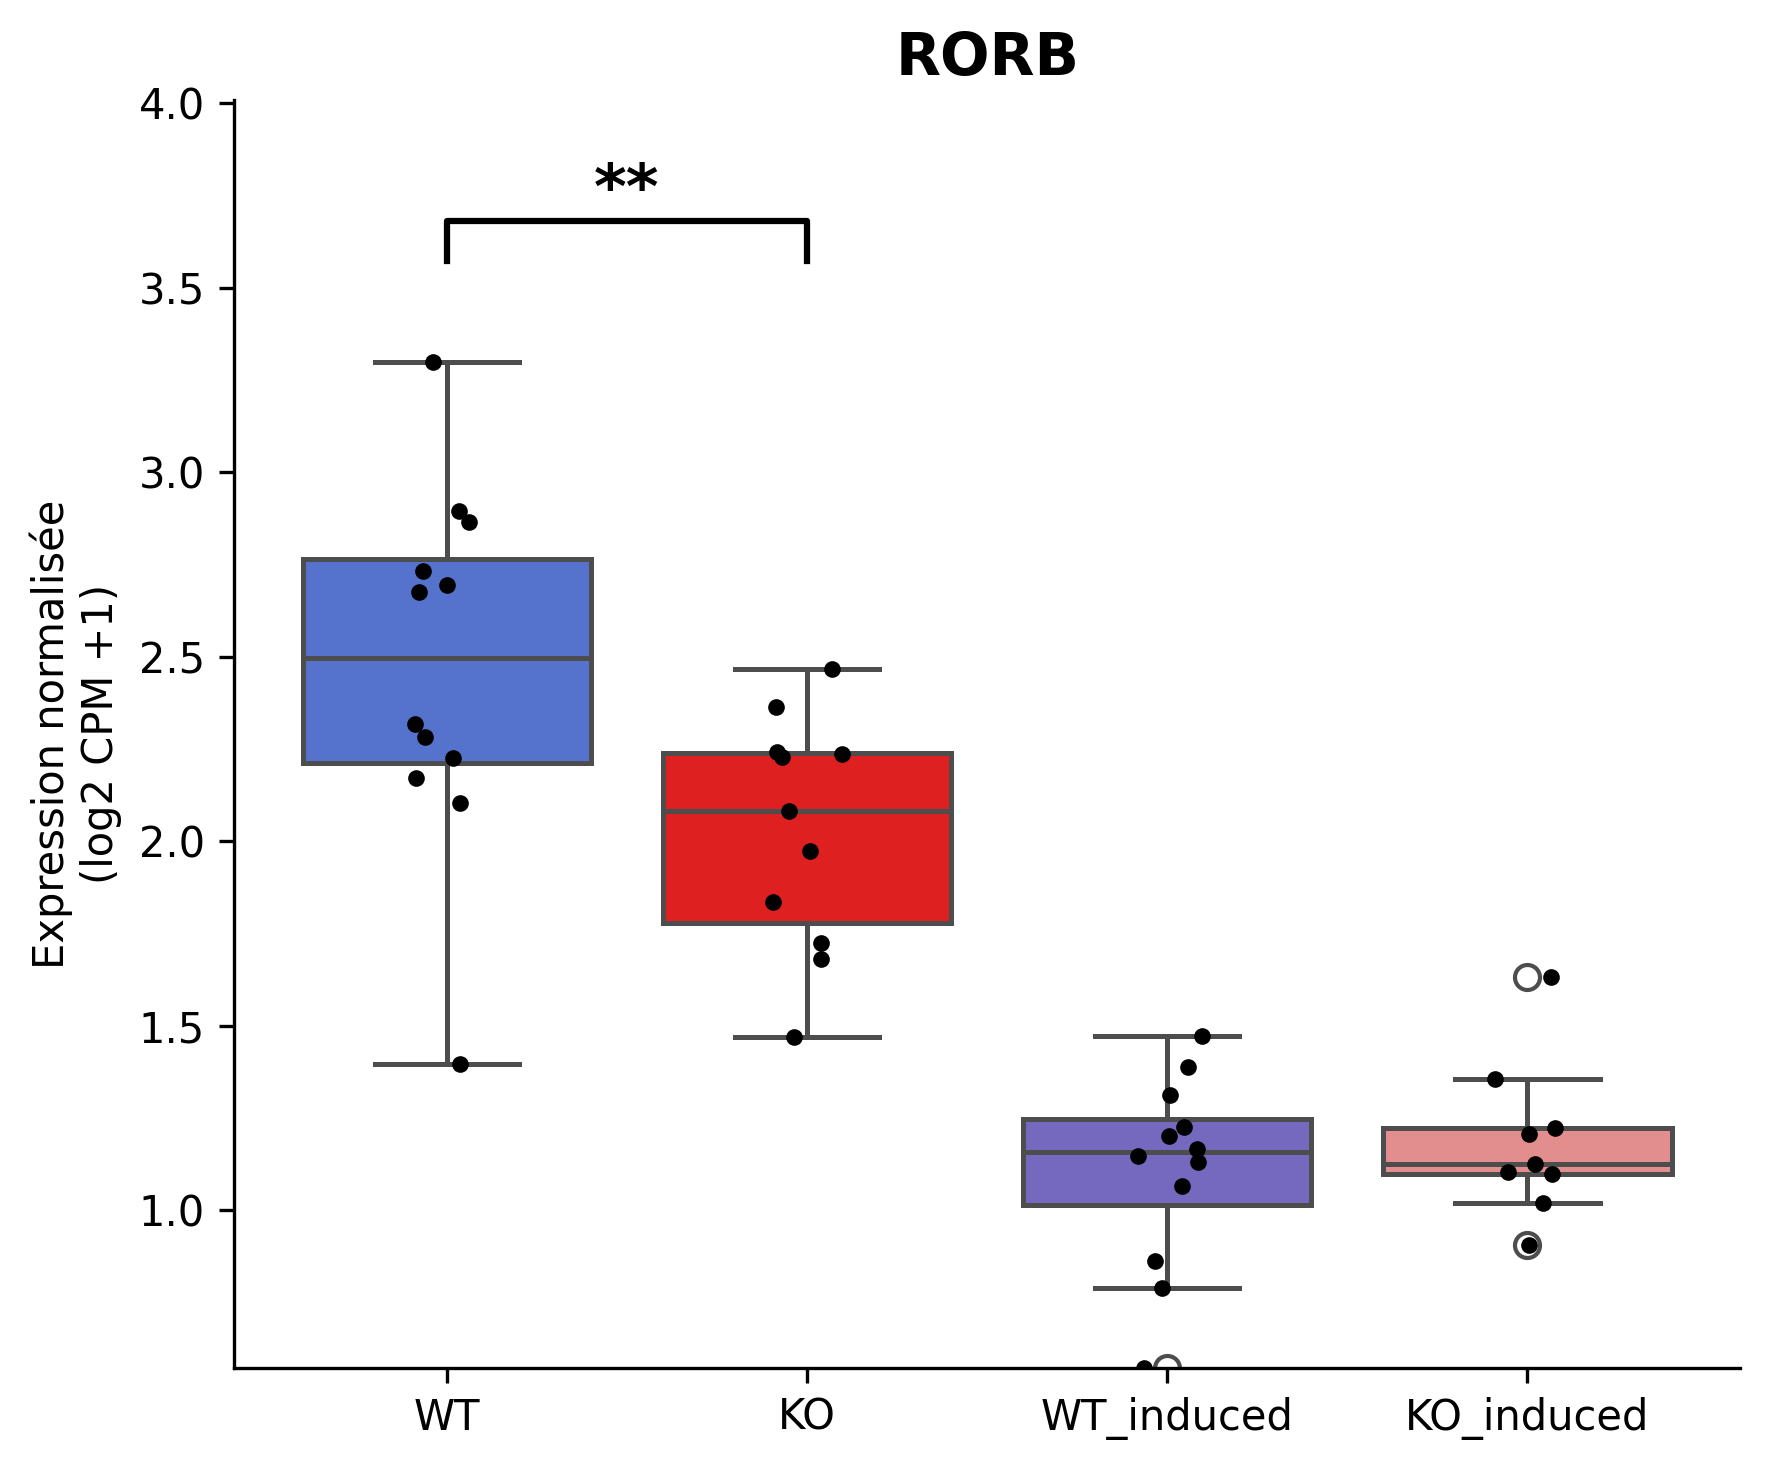

Plot : THRB


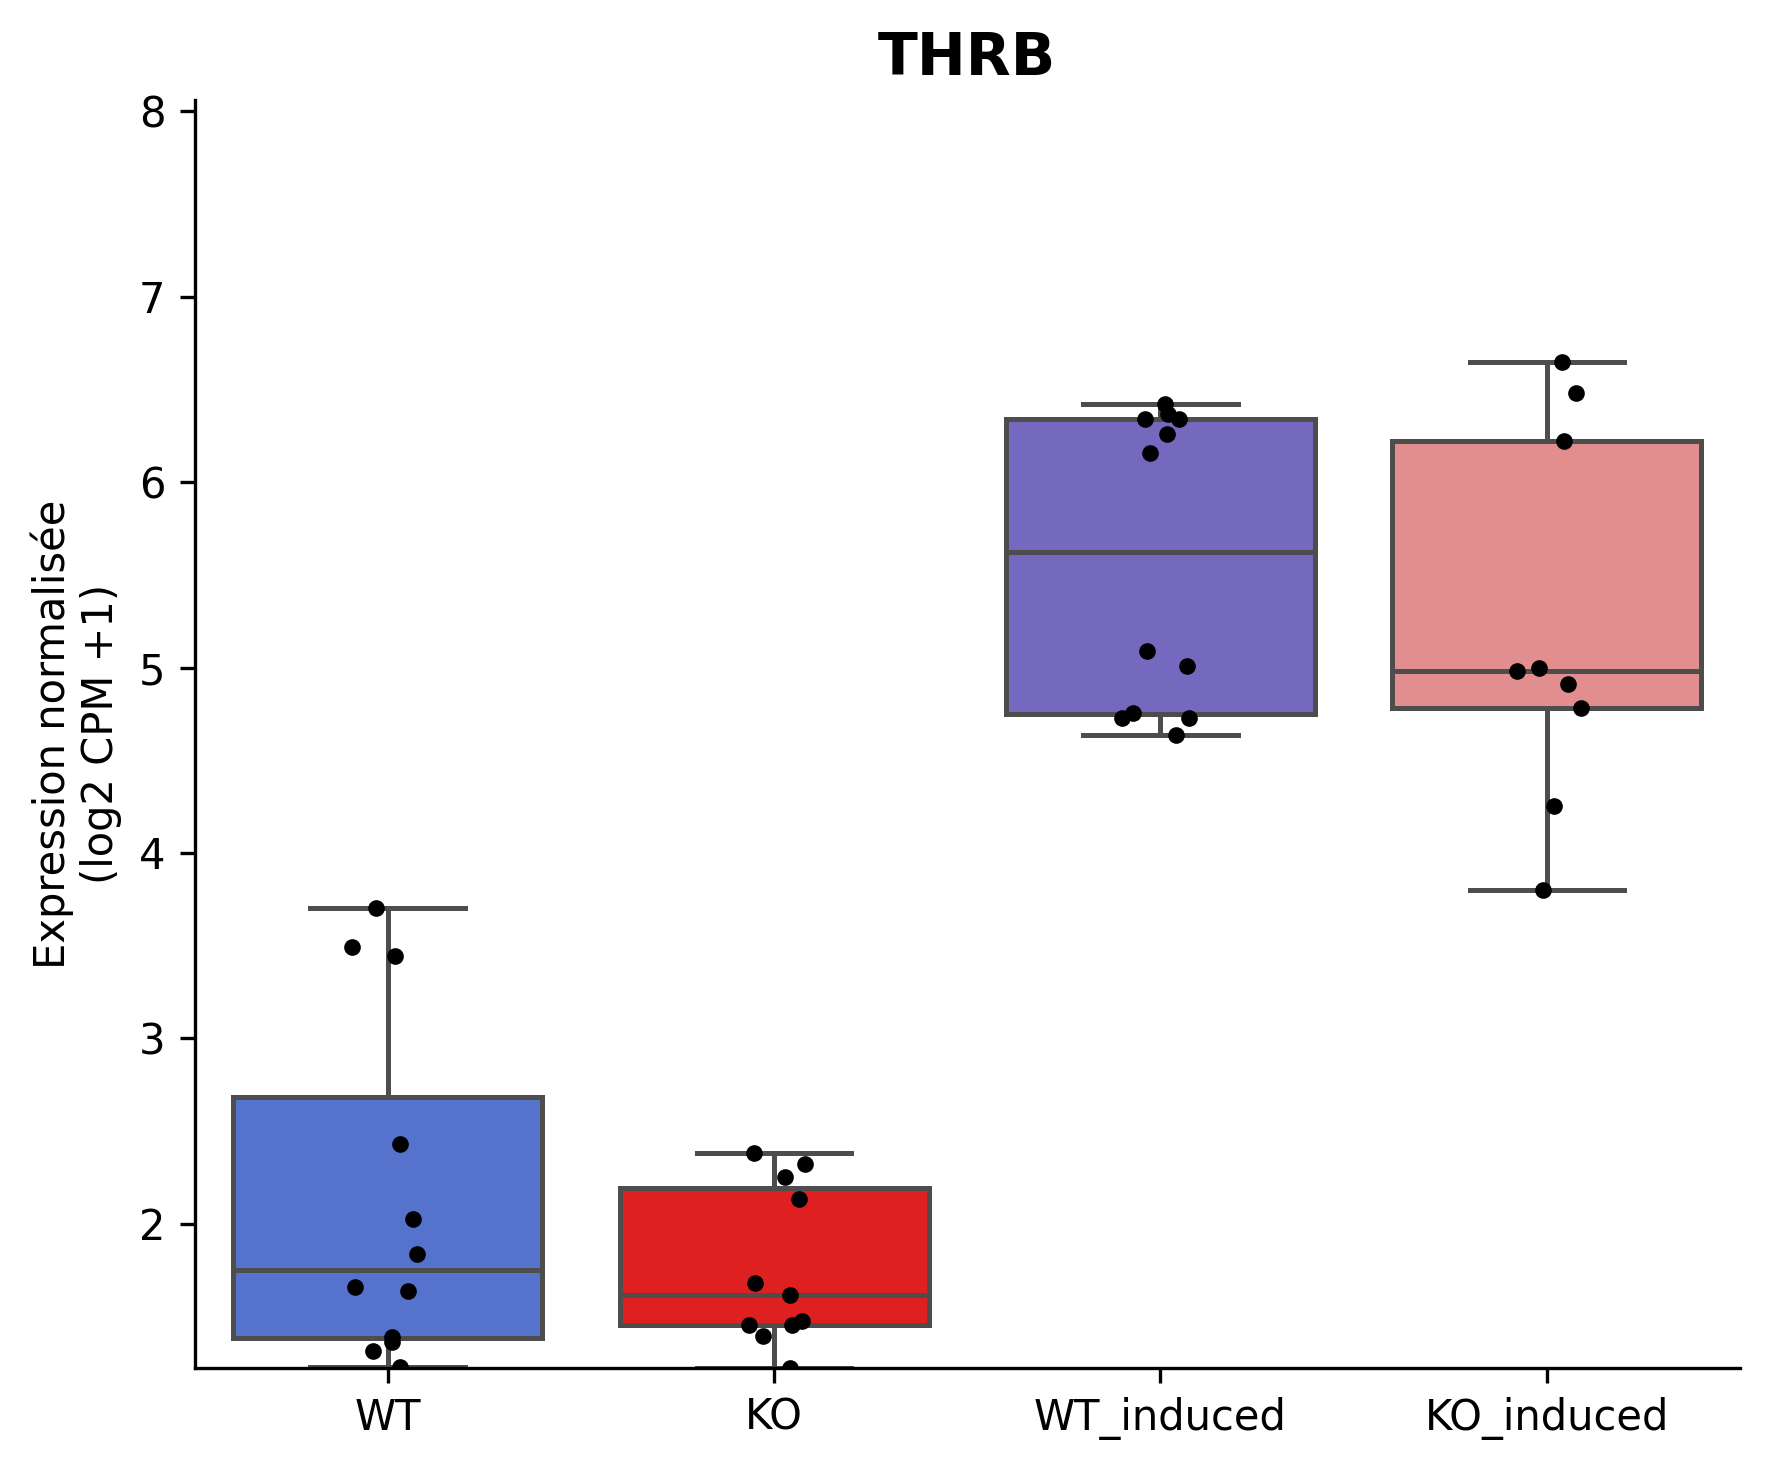

Plot : USH2A


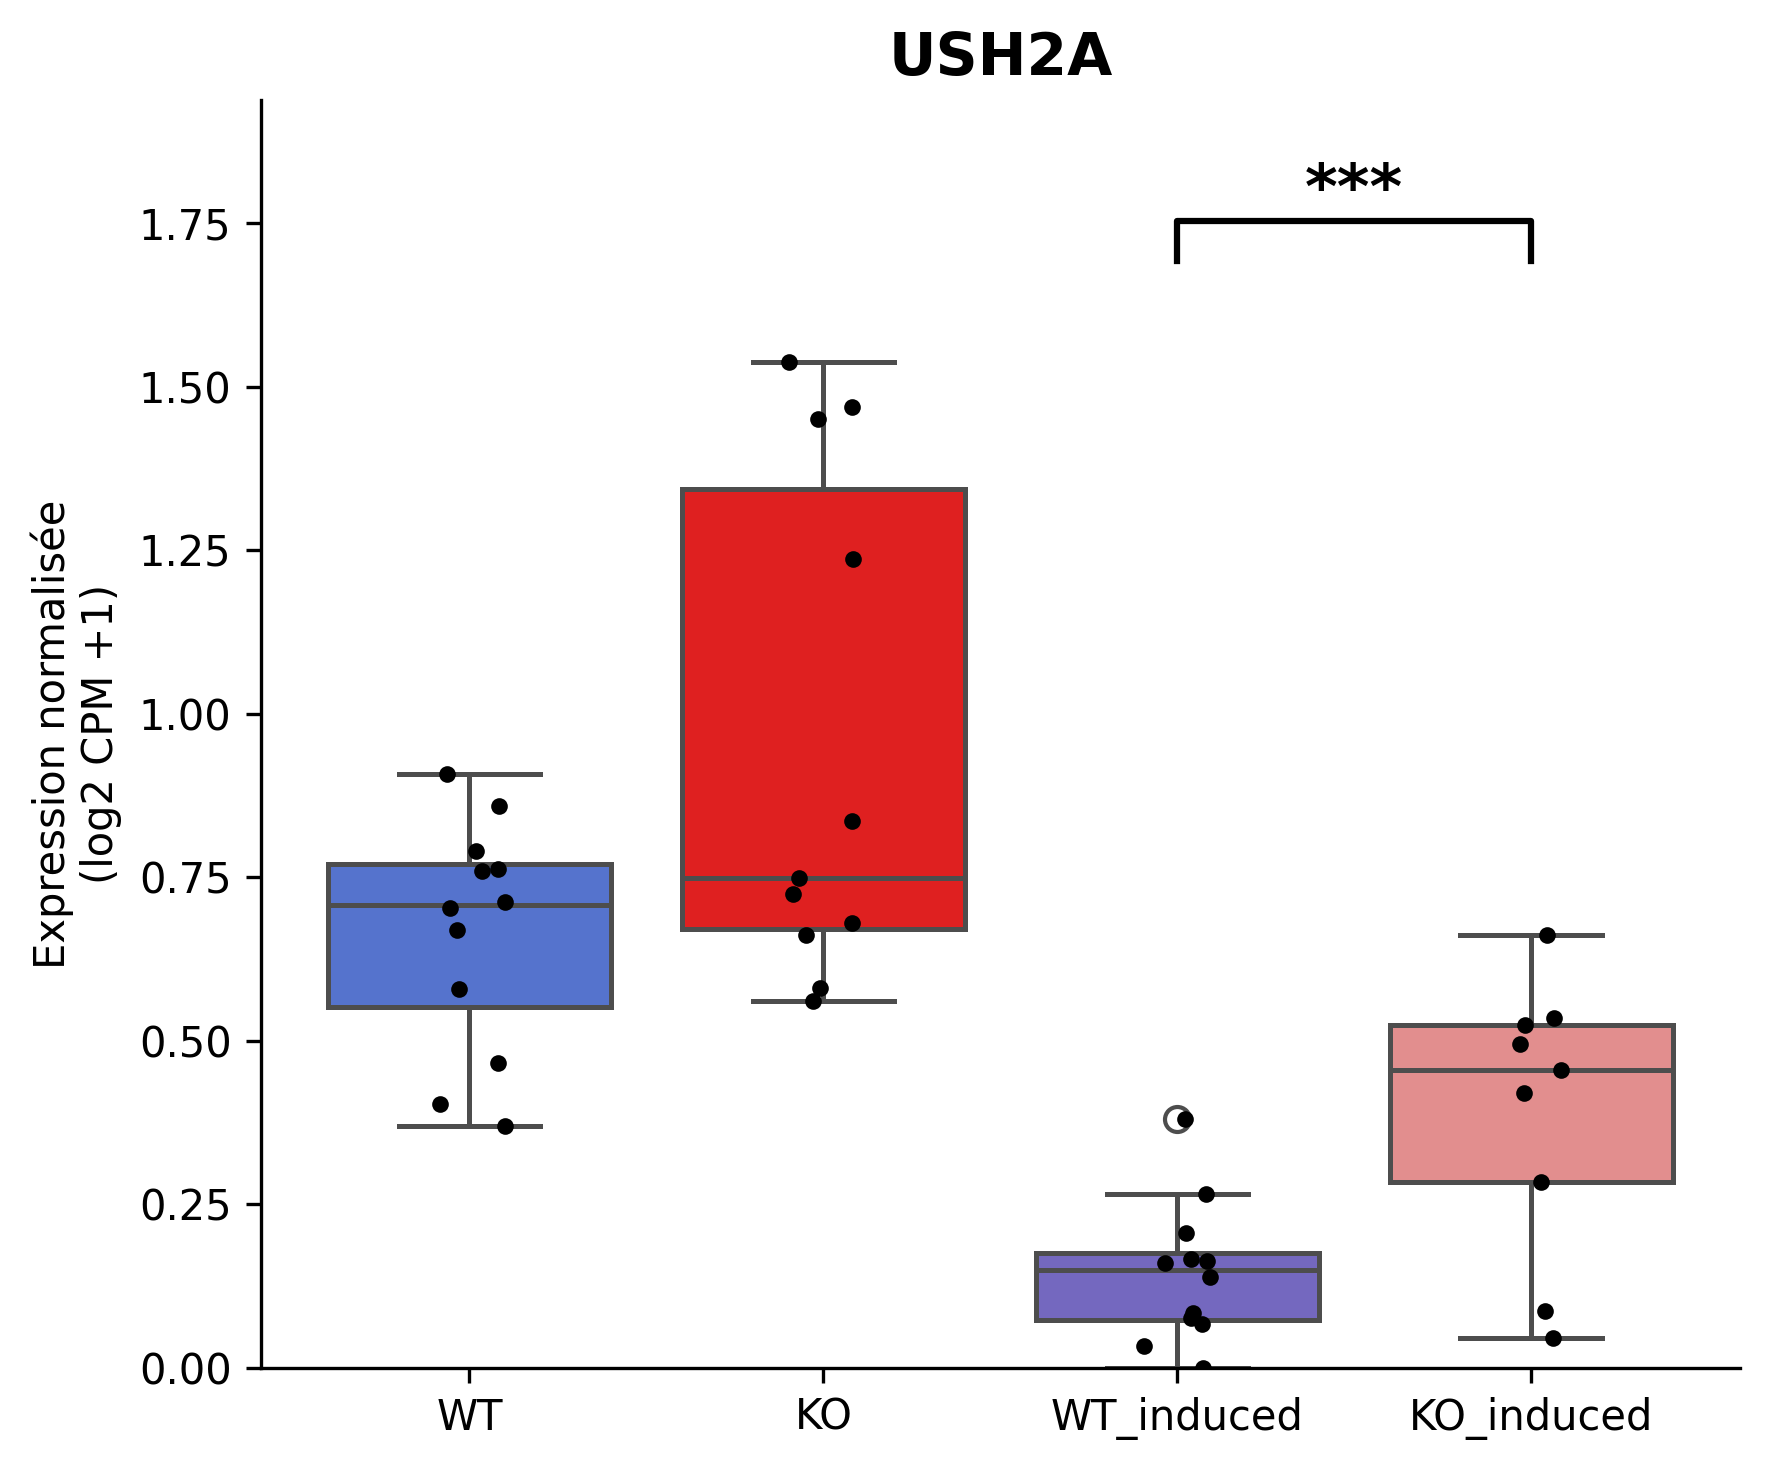

Plot : NRL


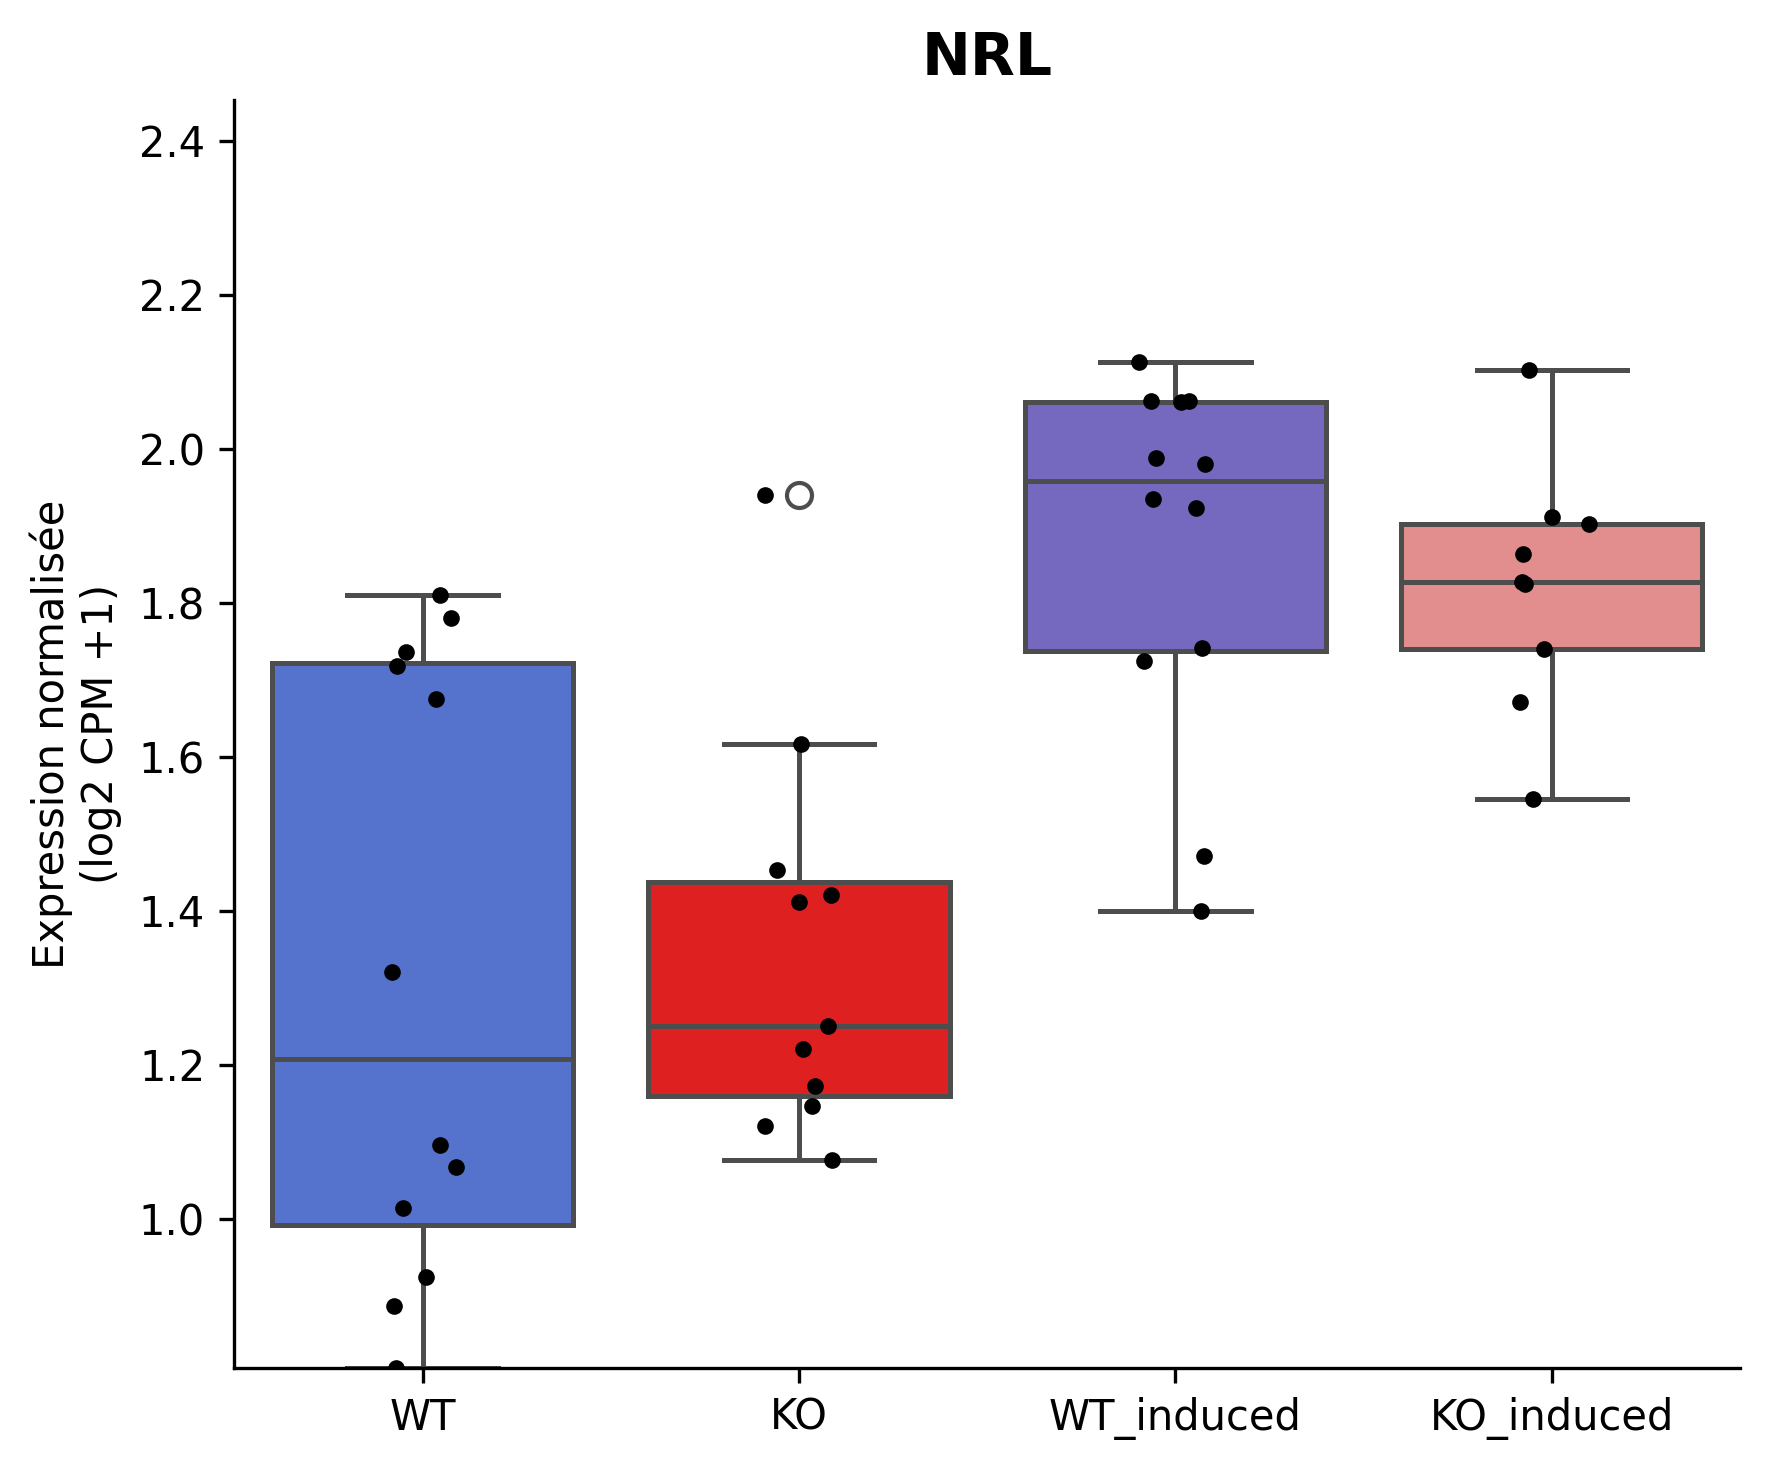

Plot : NR2E3


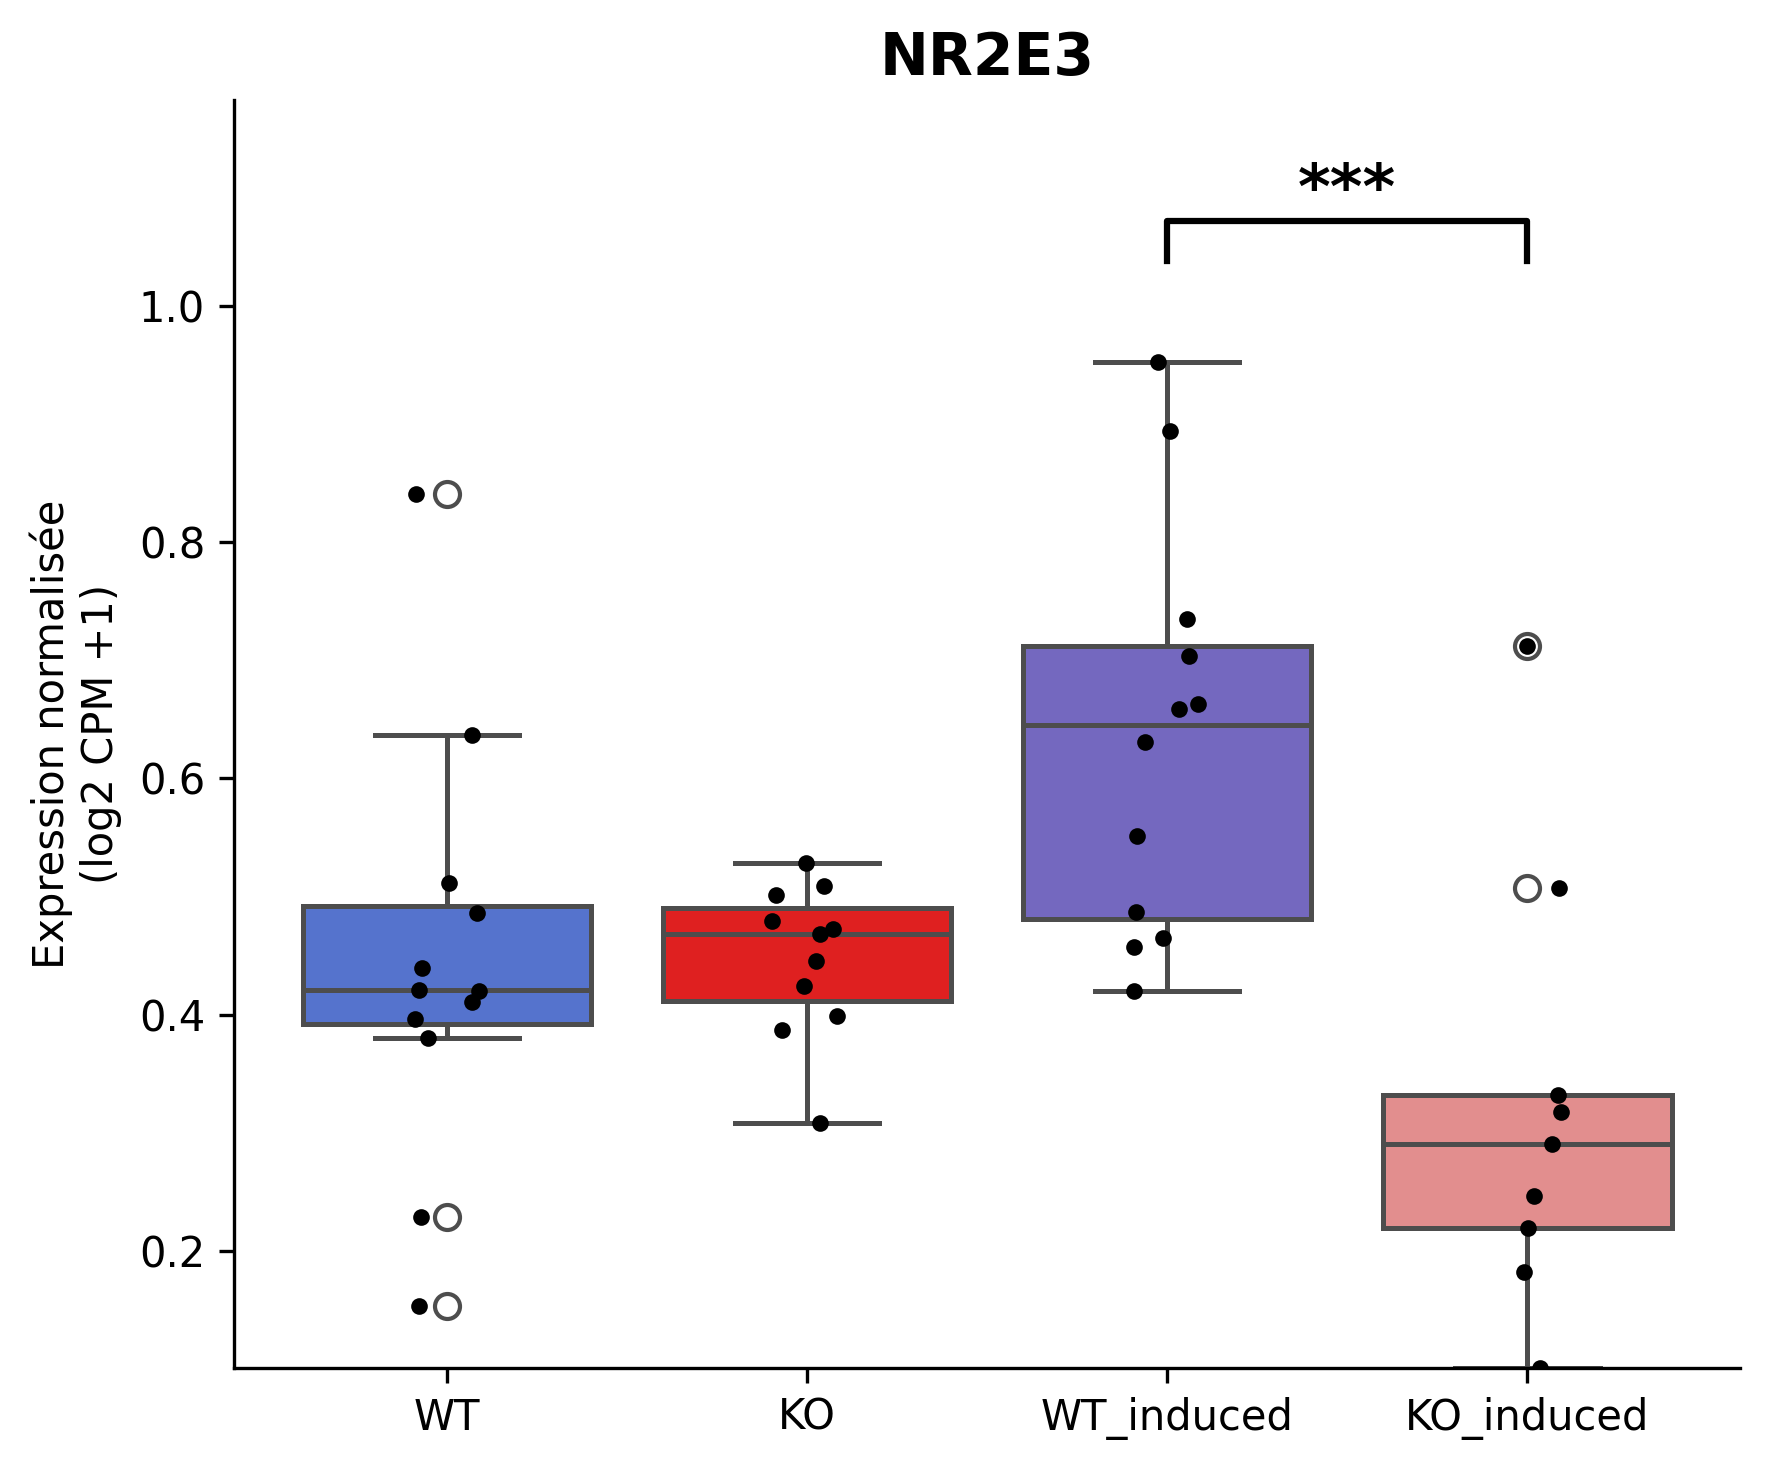

Plot : NR2F1


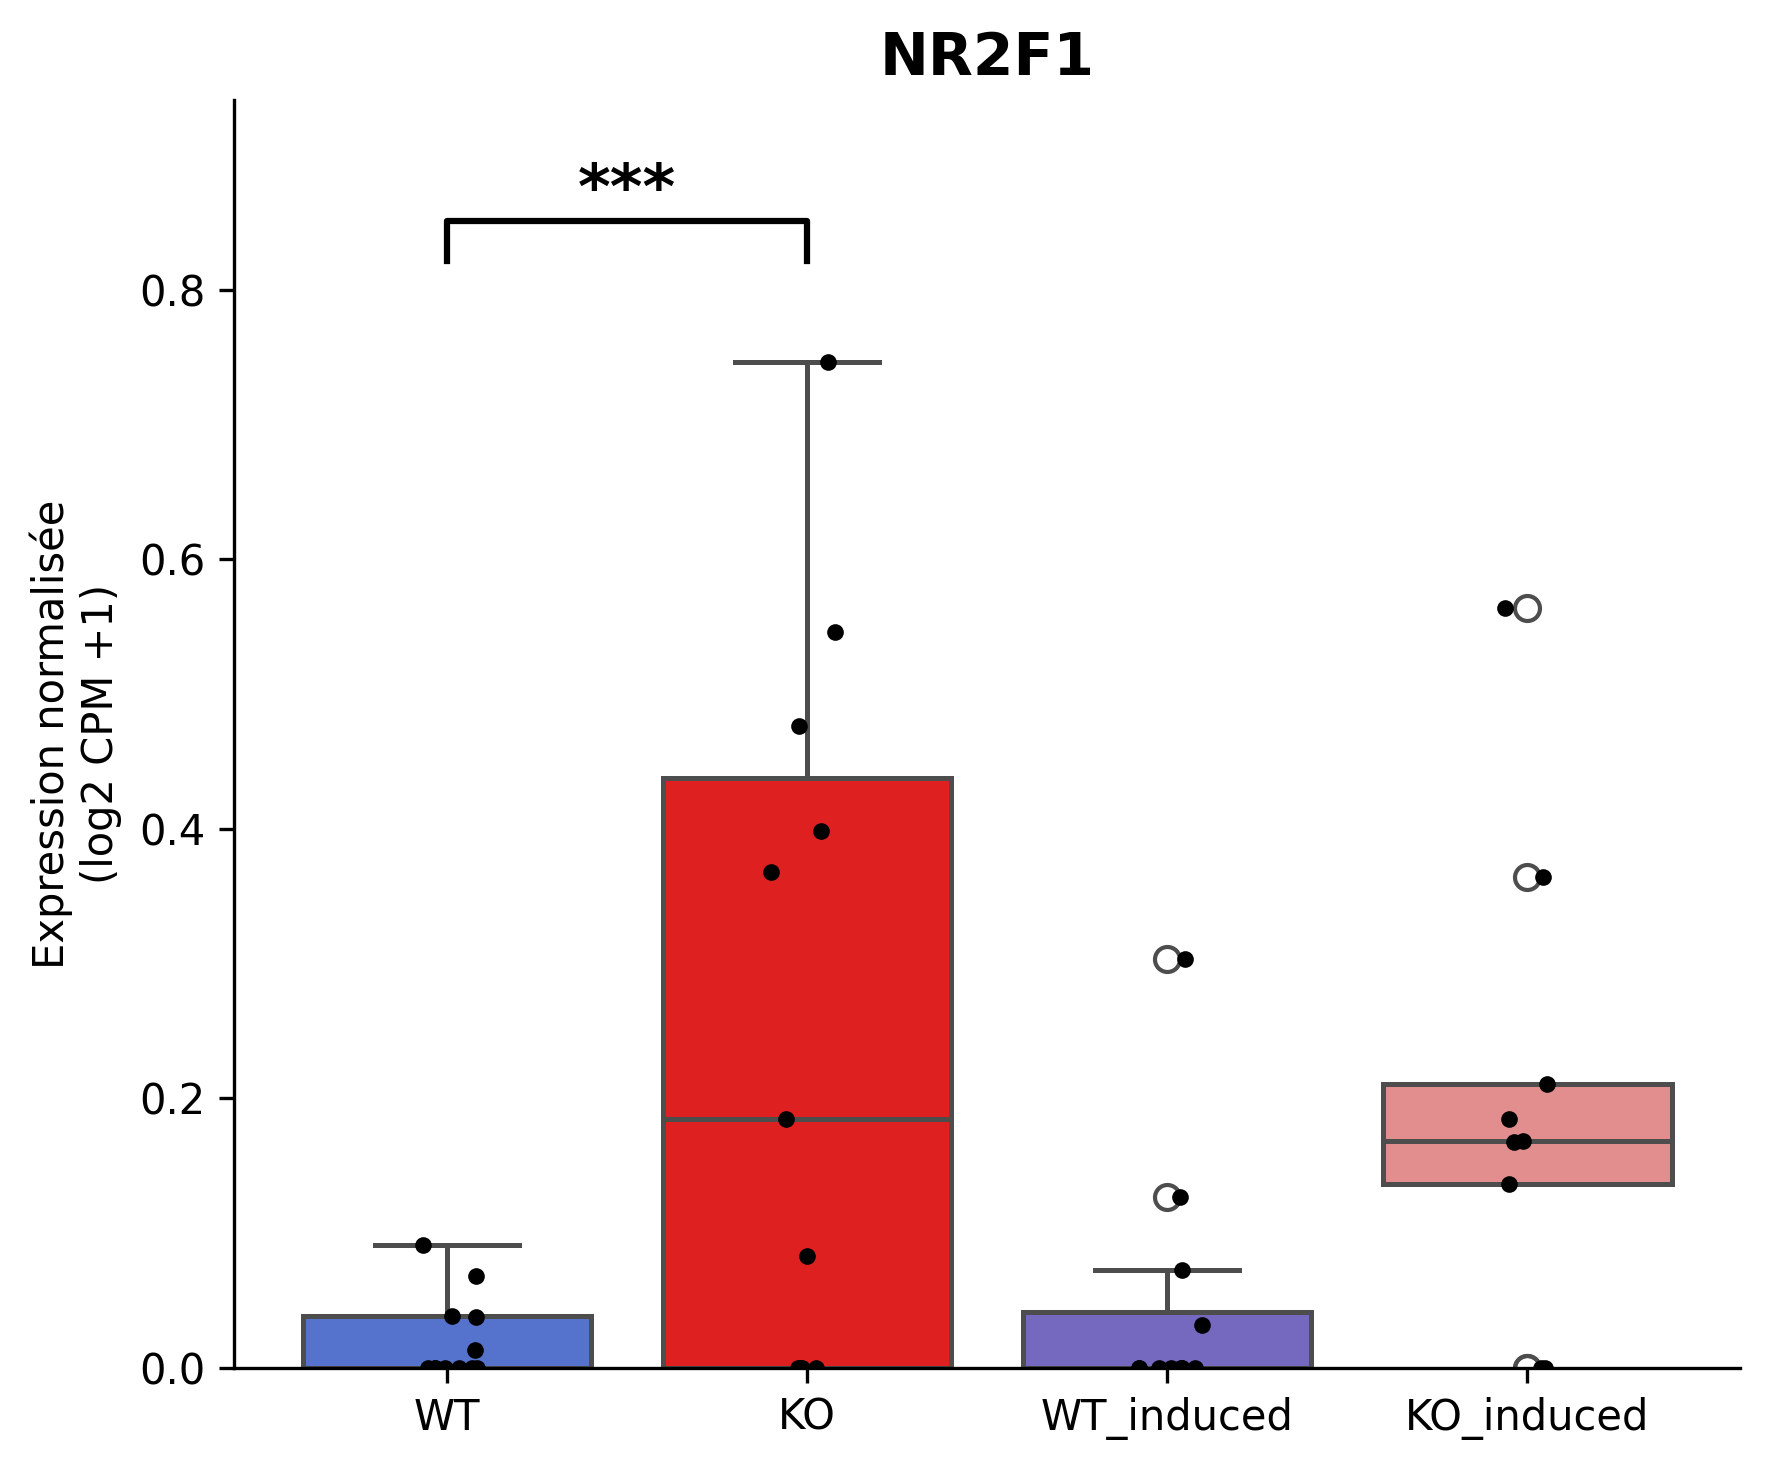

Plot : PAX6


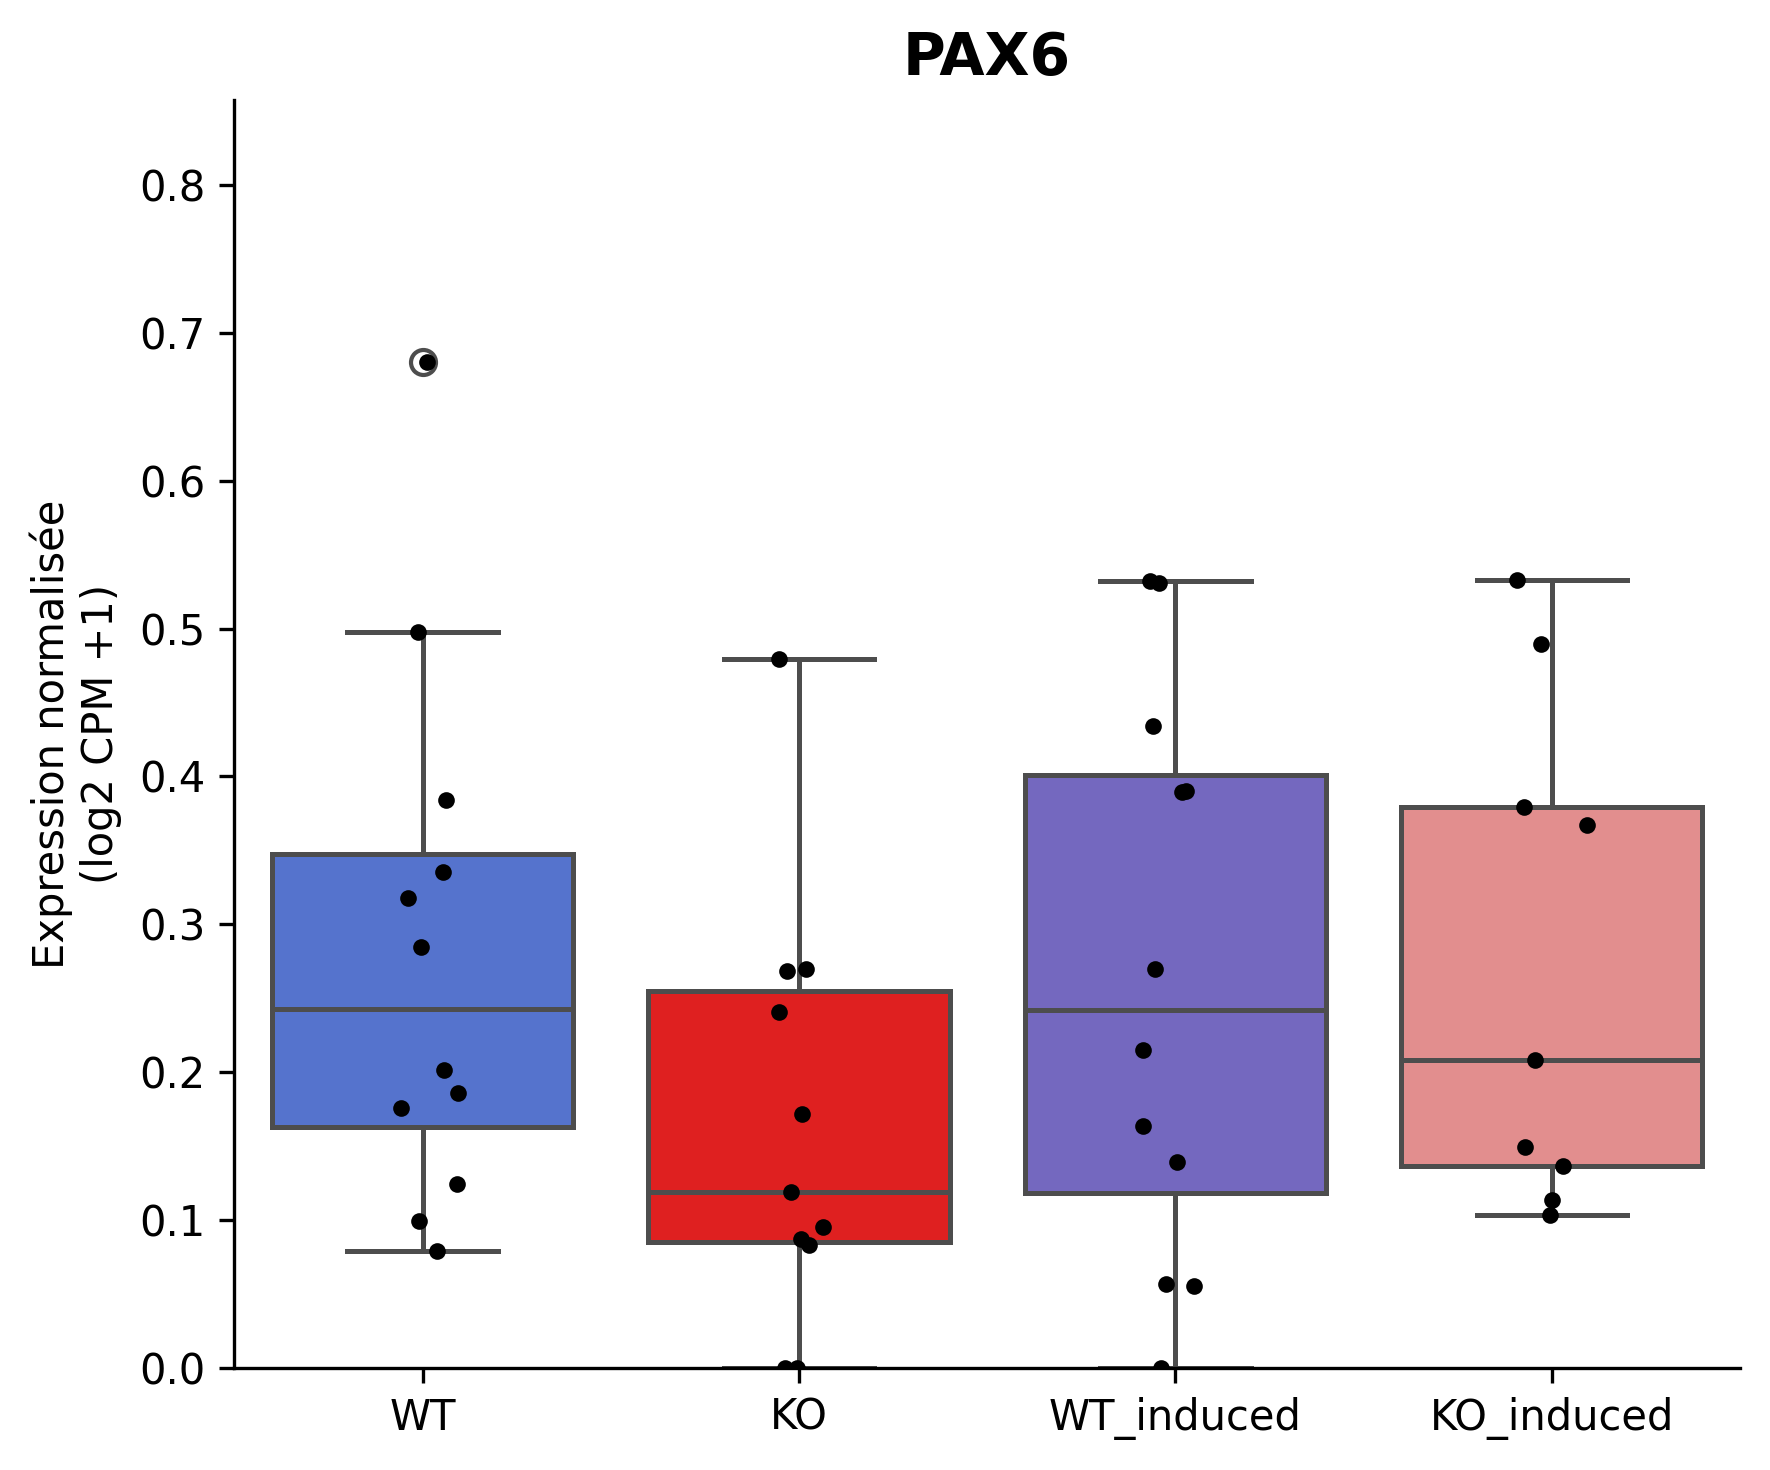

Plot : FOXP2


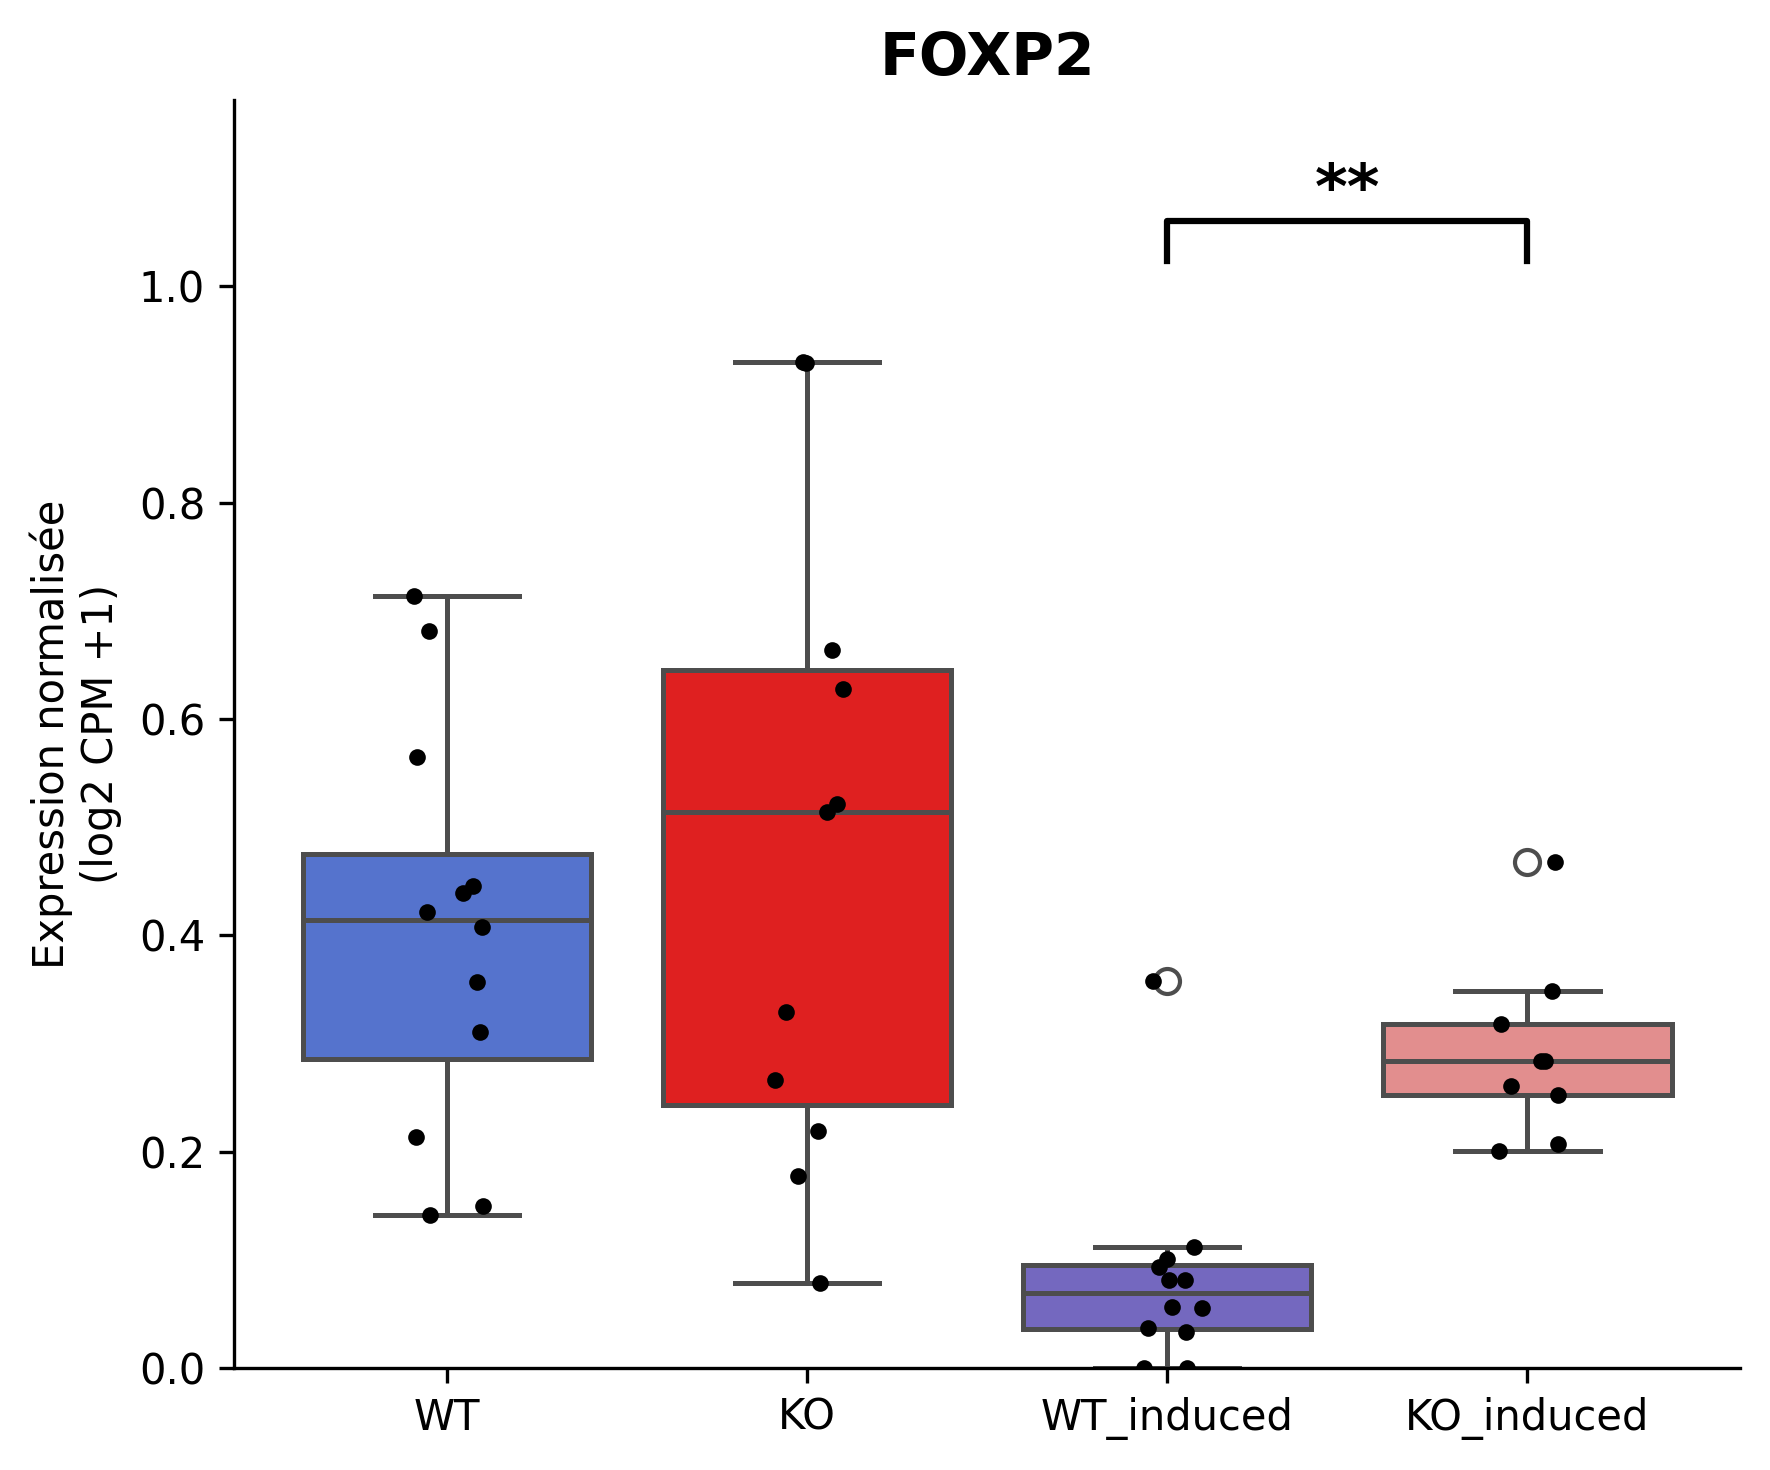

Plot : GAD1


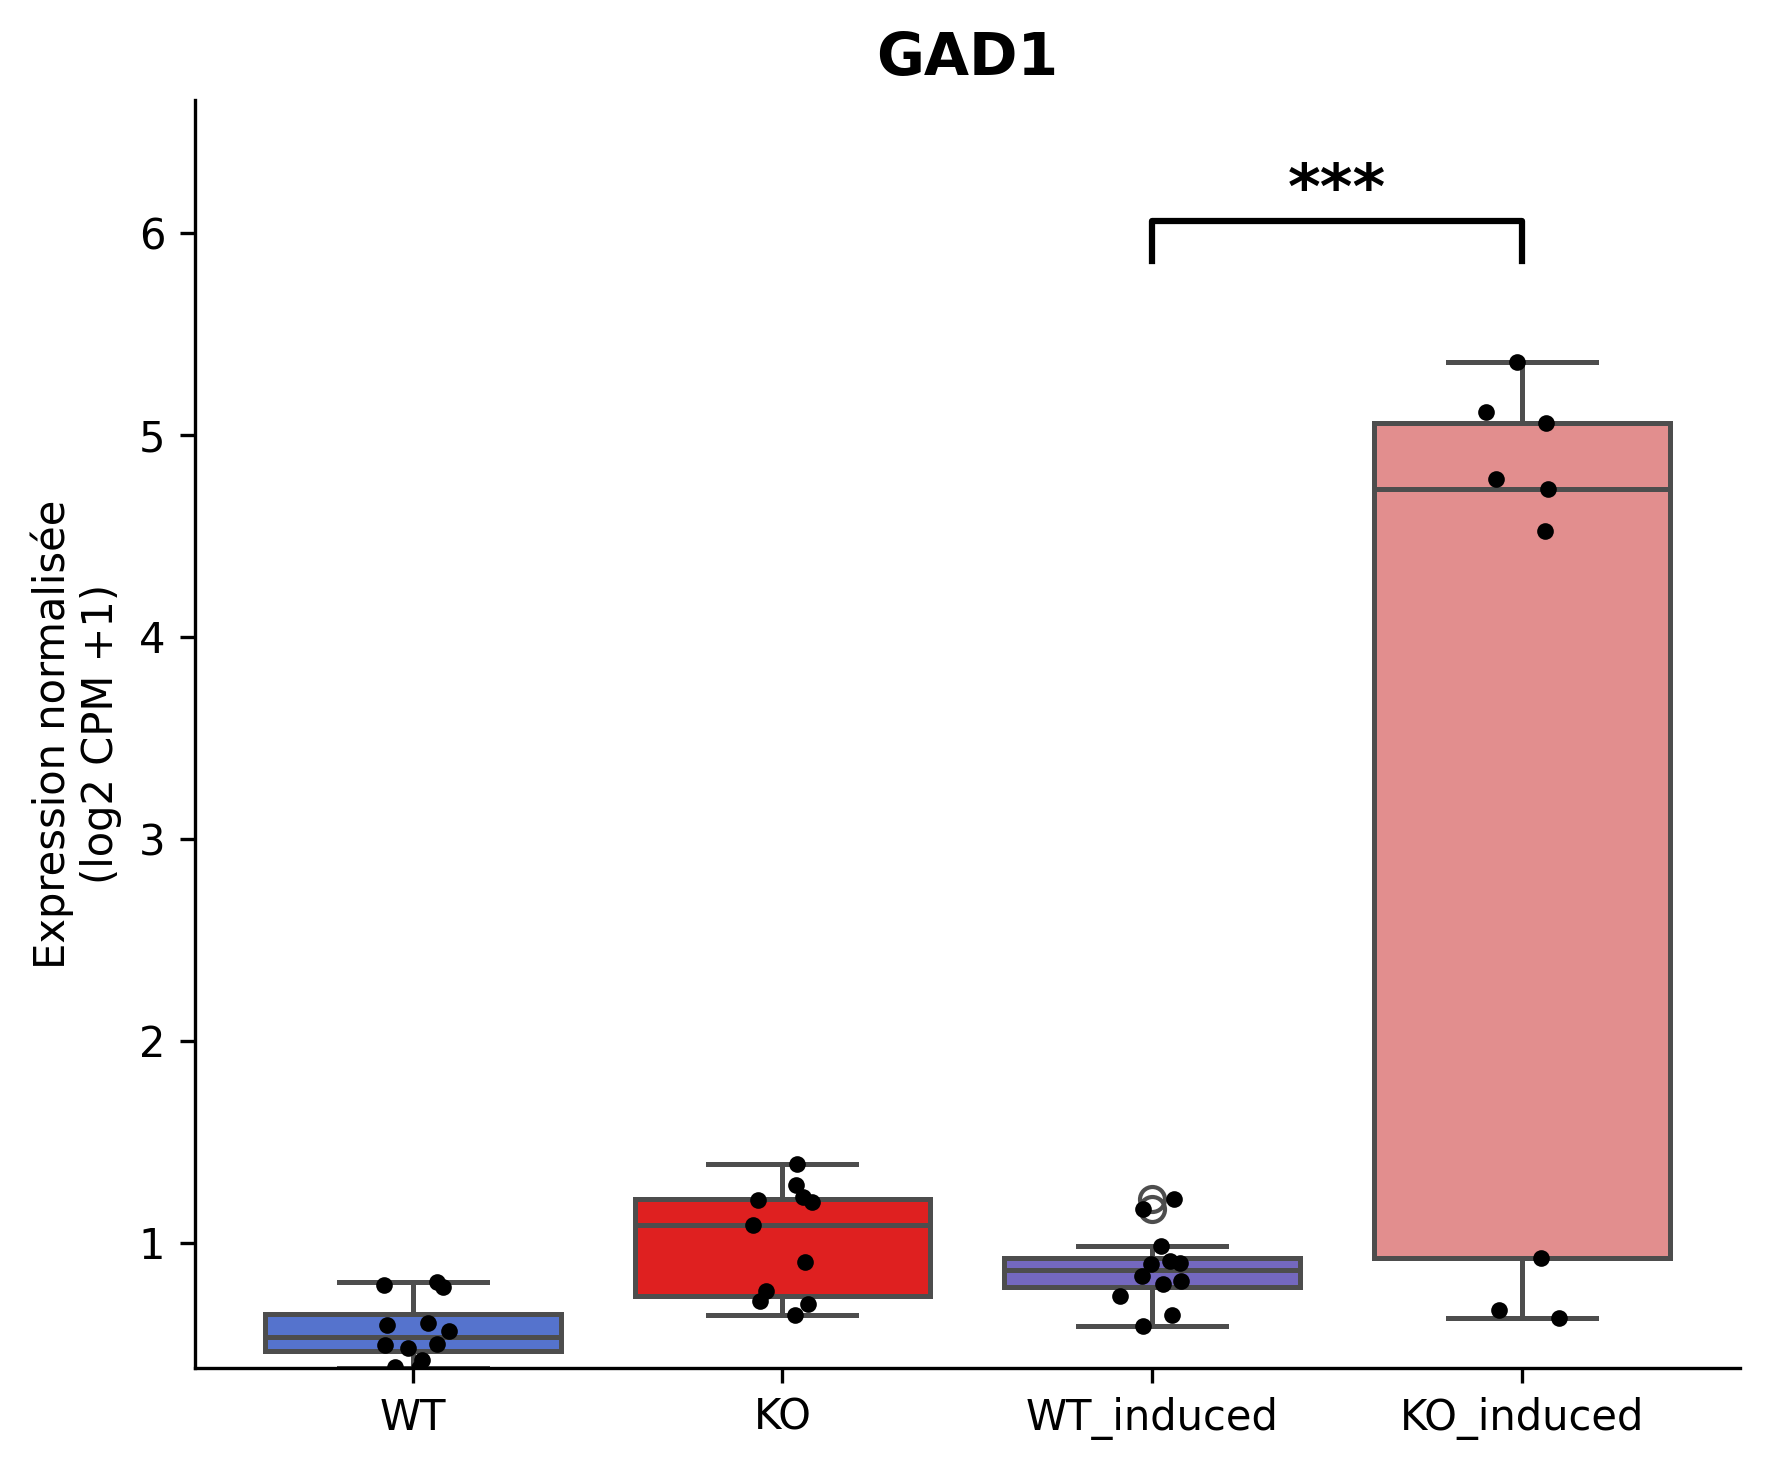

Plot : MKI67


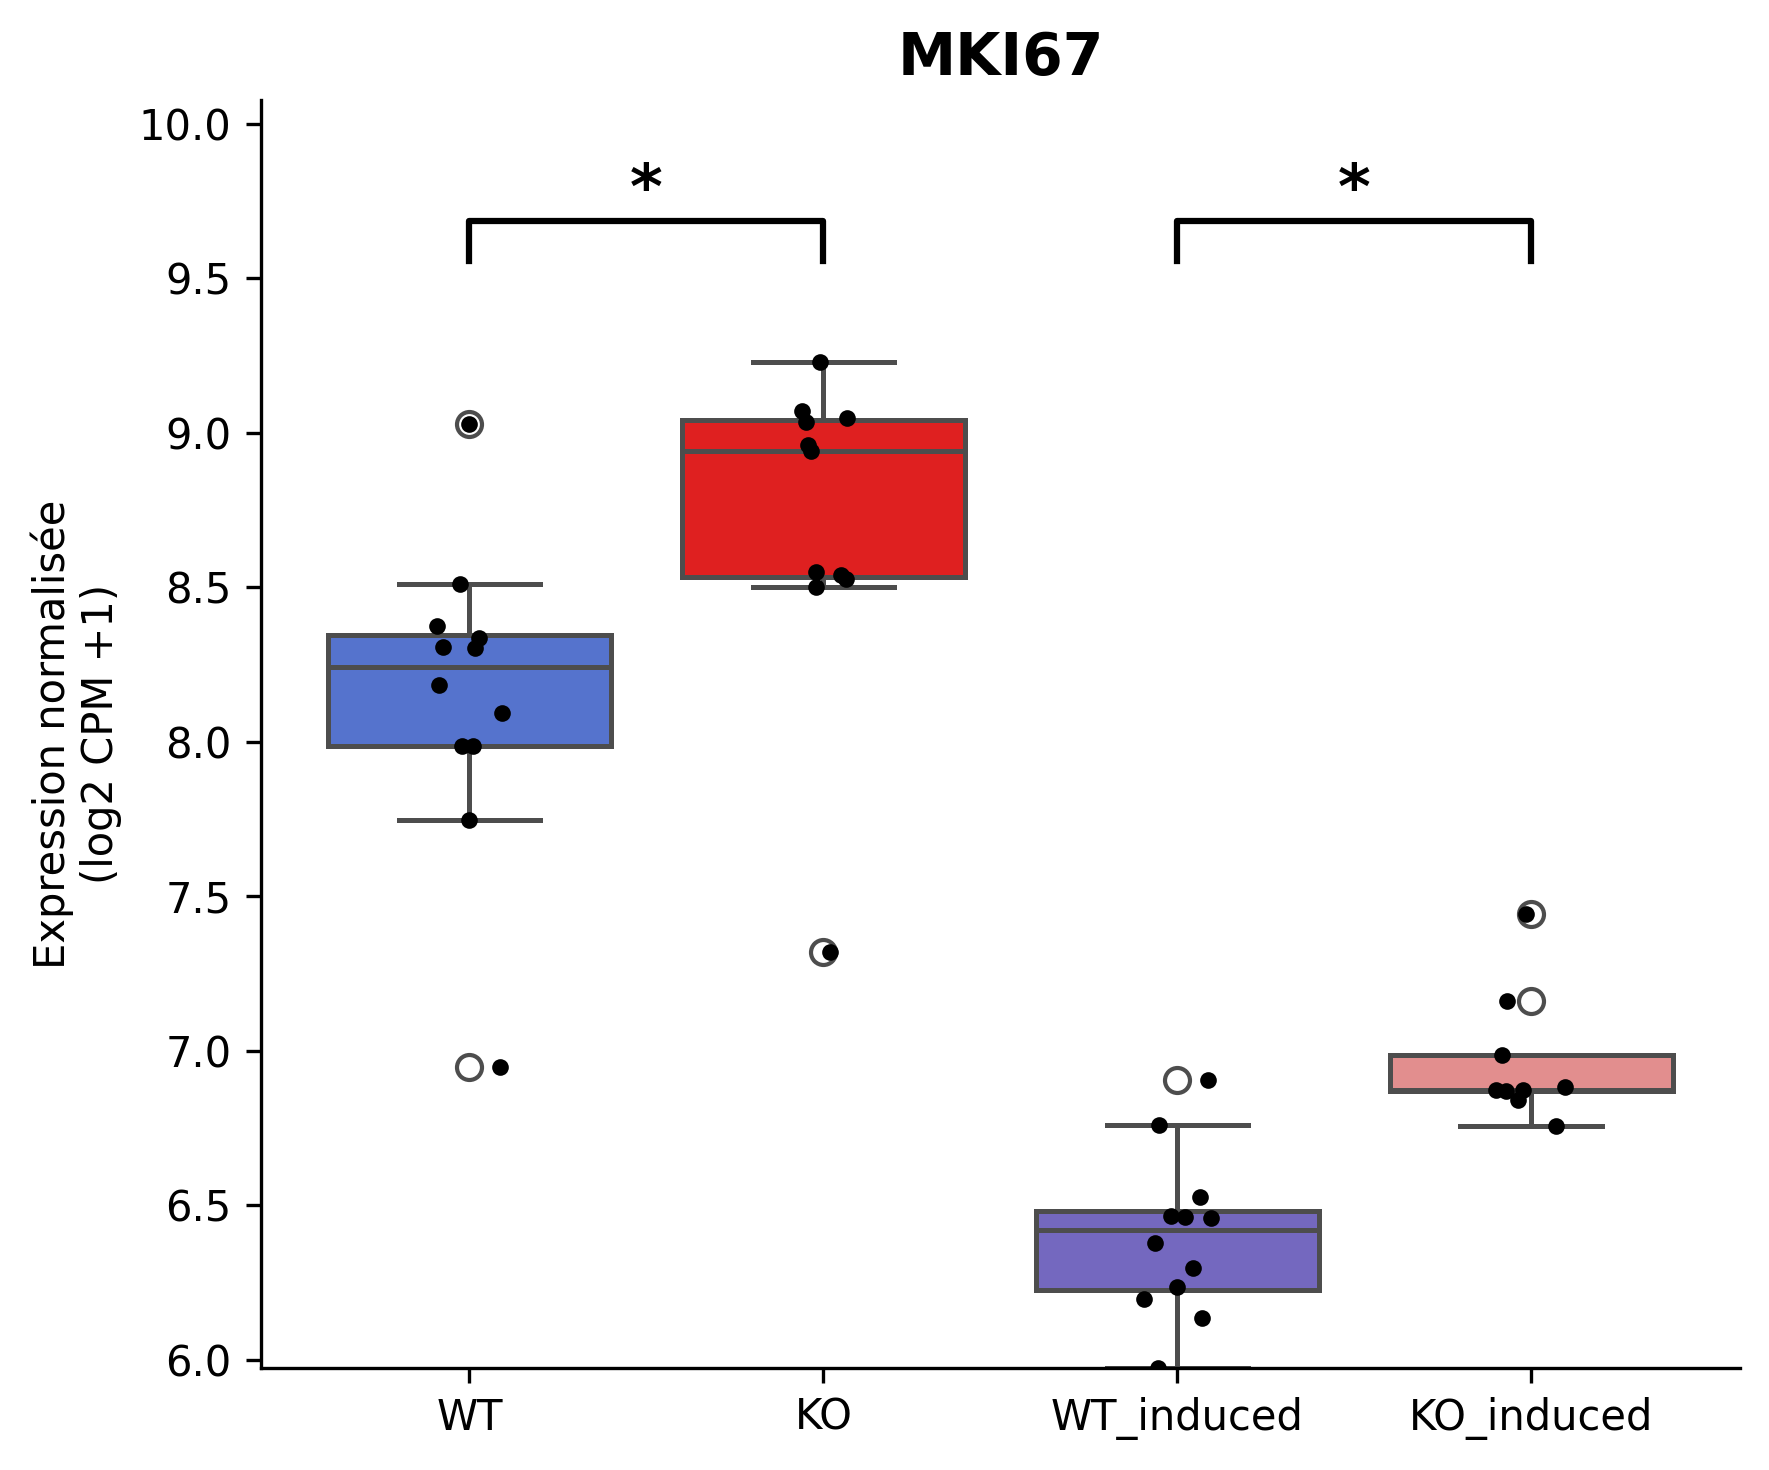

Plot : FABP7


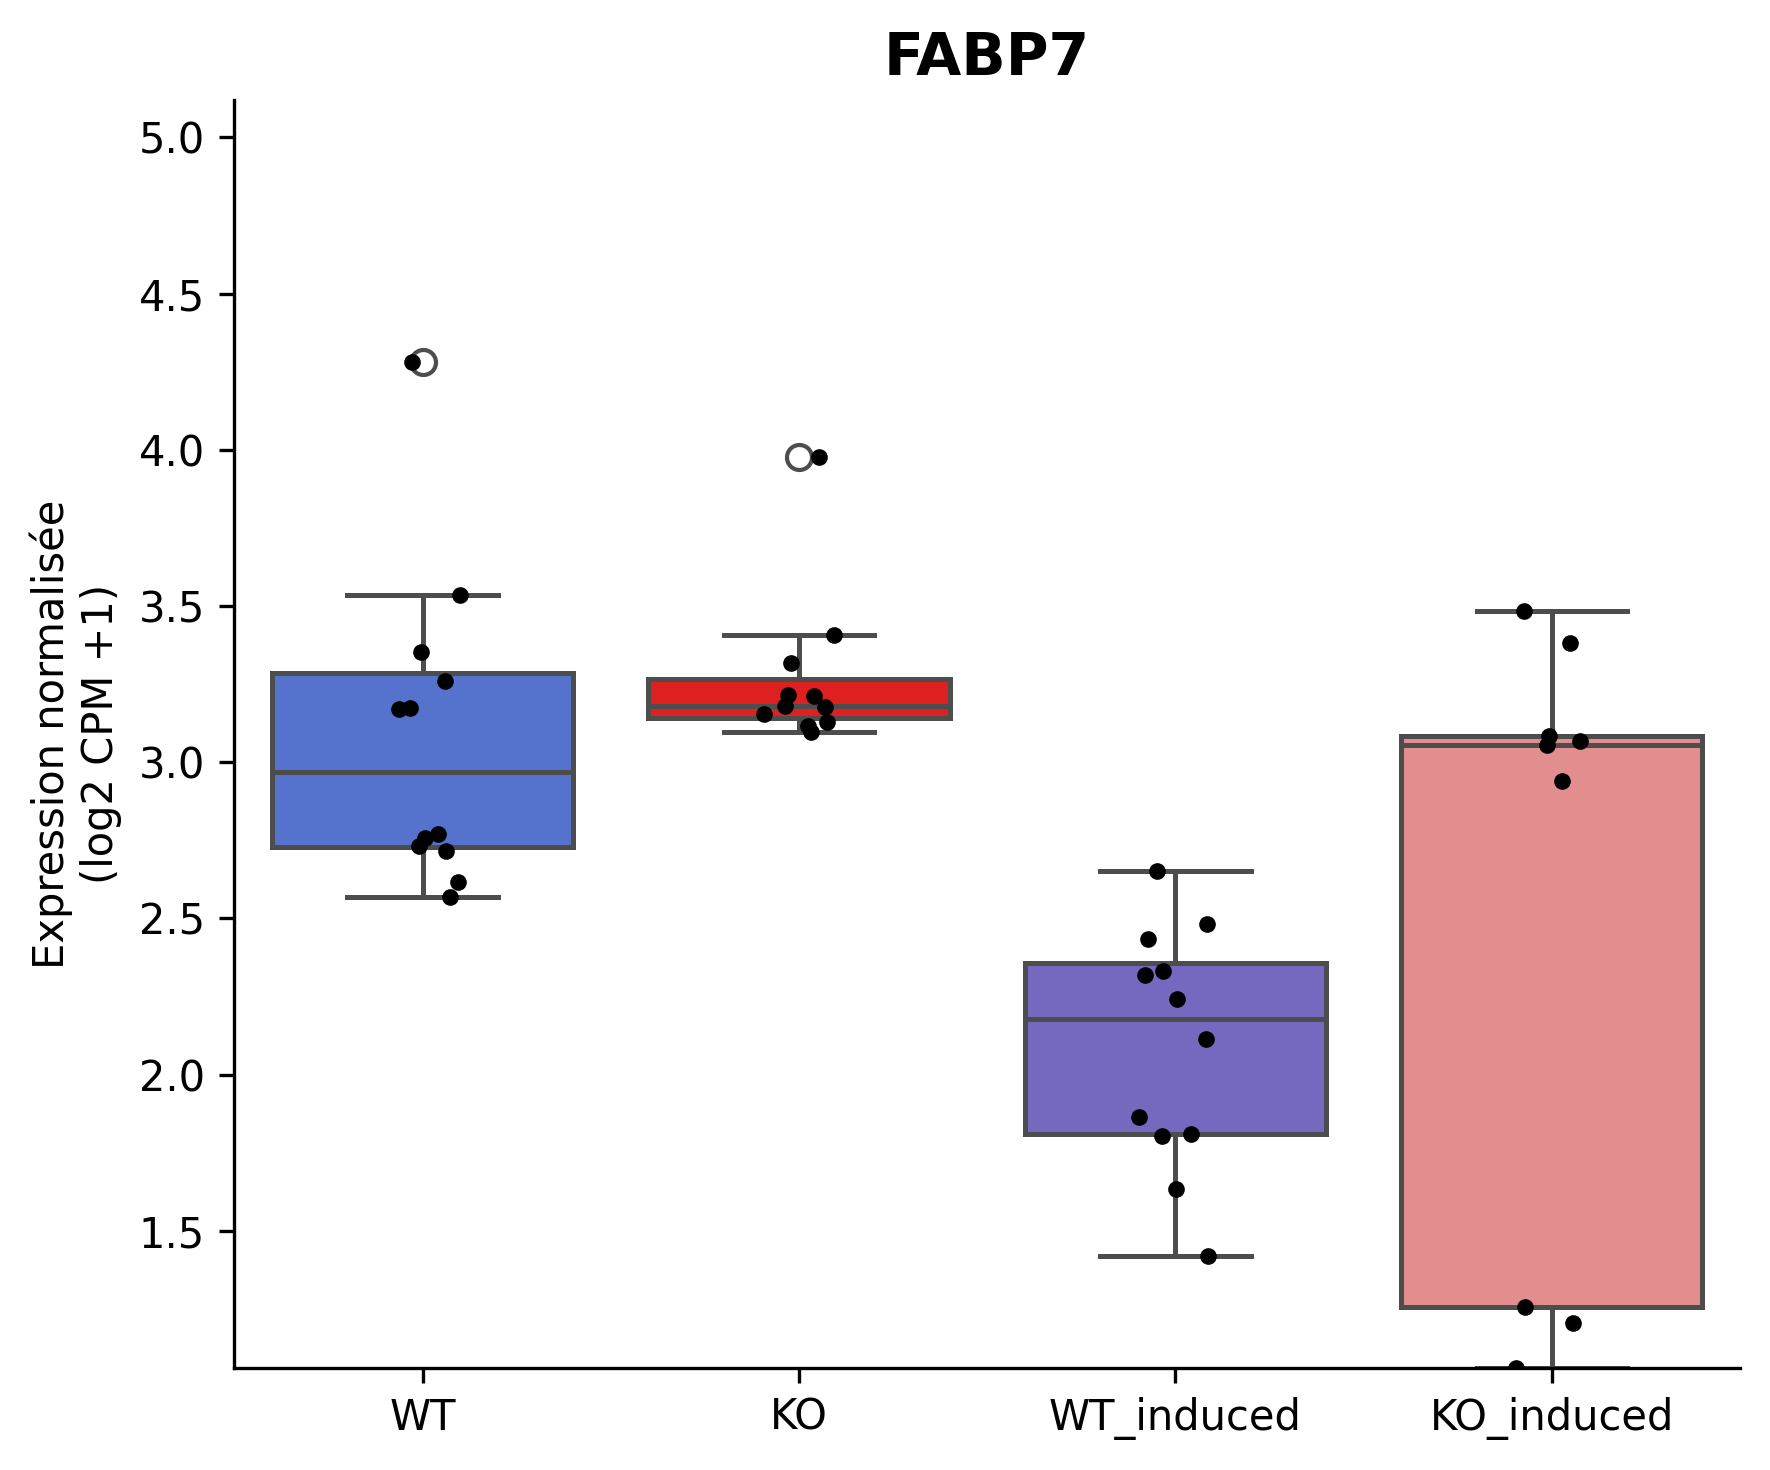

Plot : NES


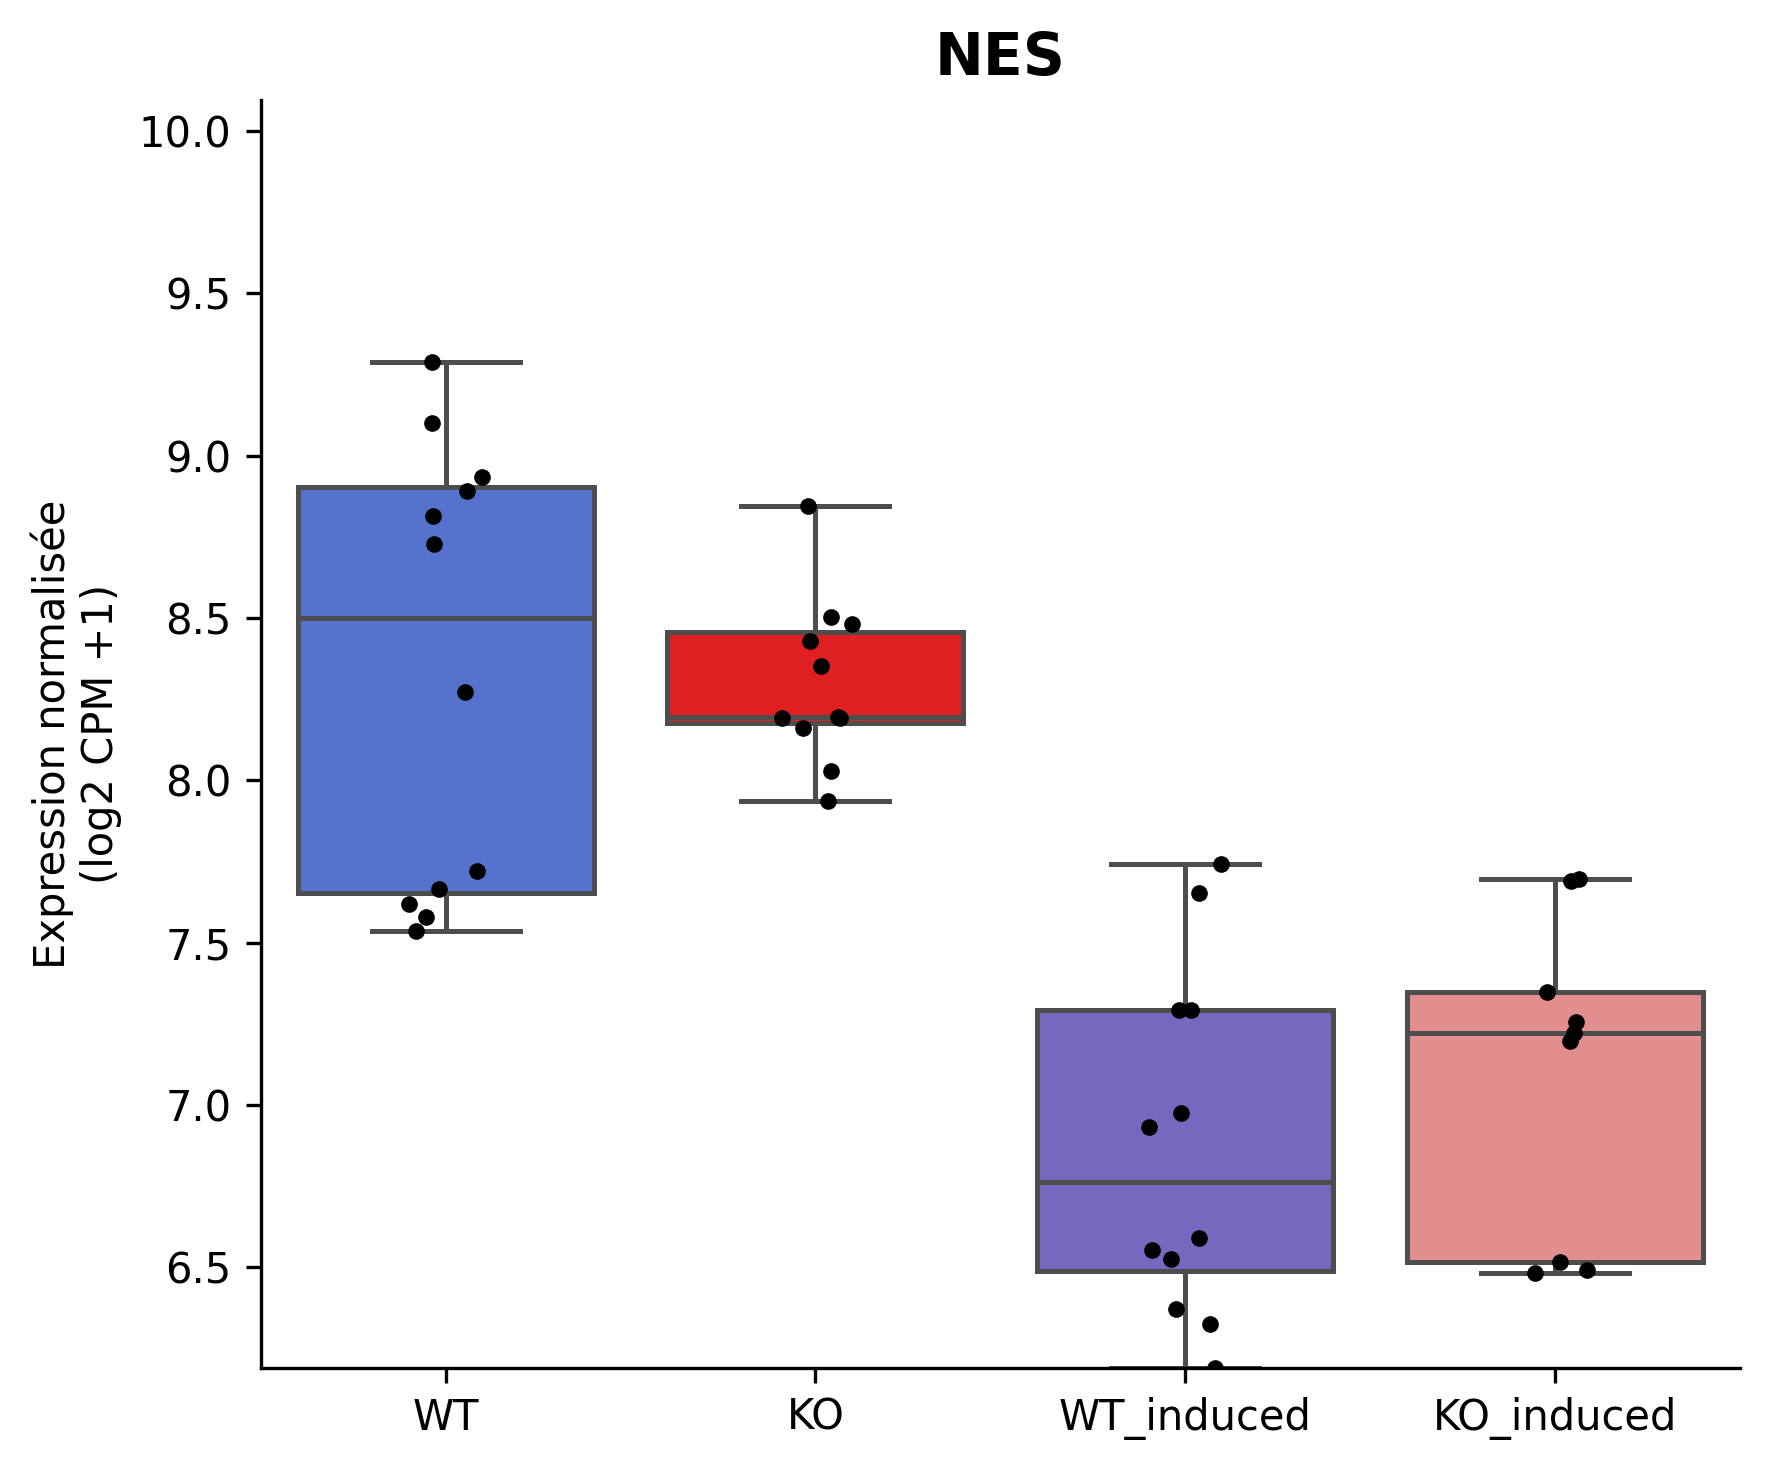

Plot : MED13L


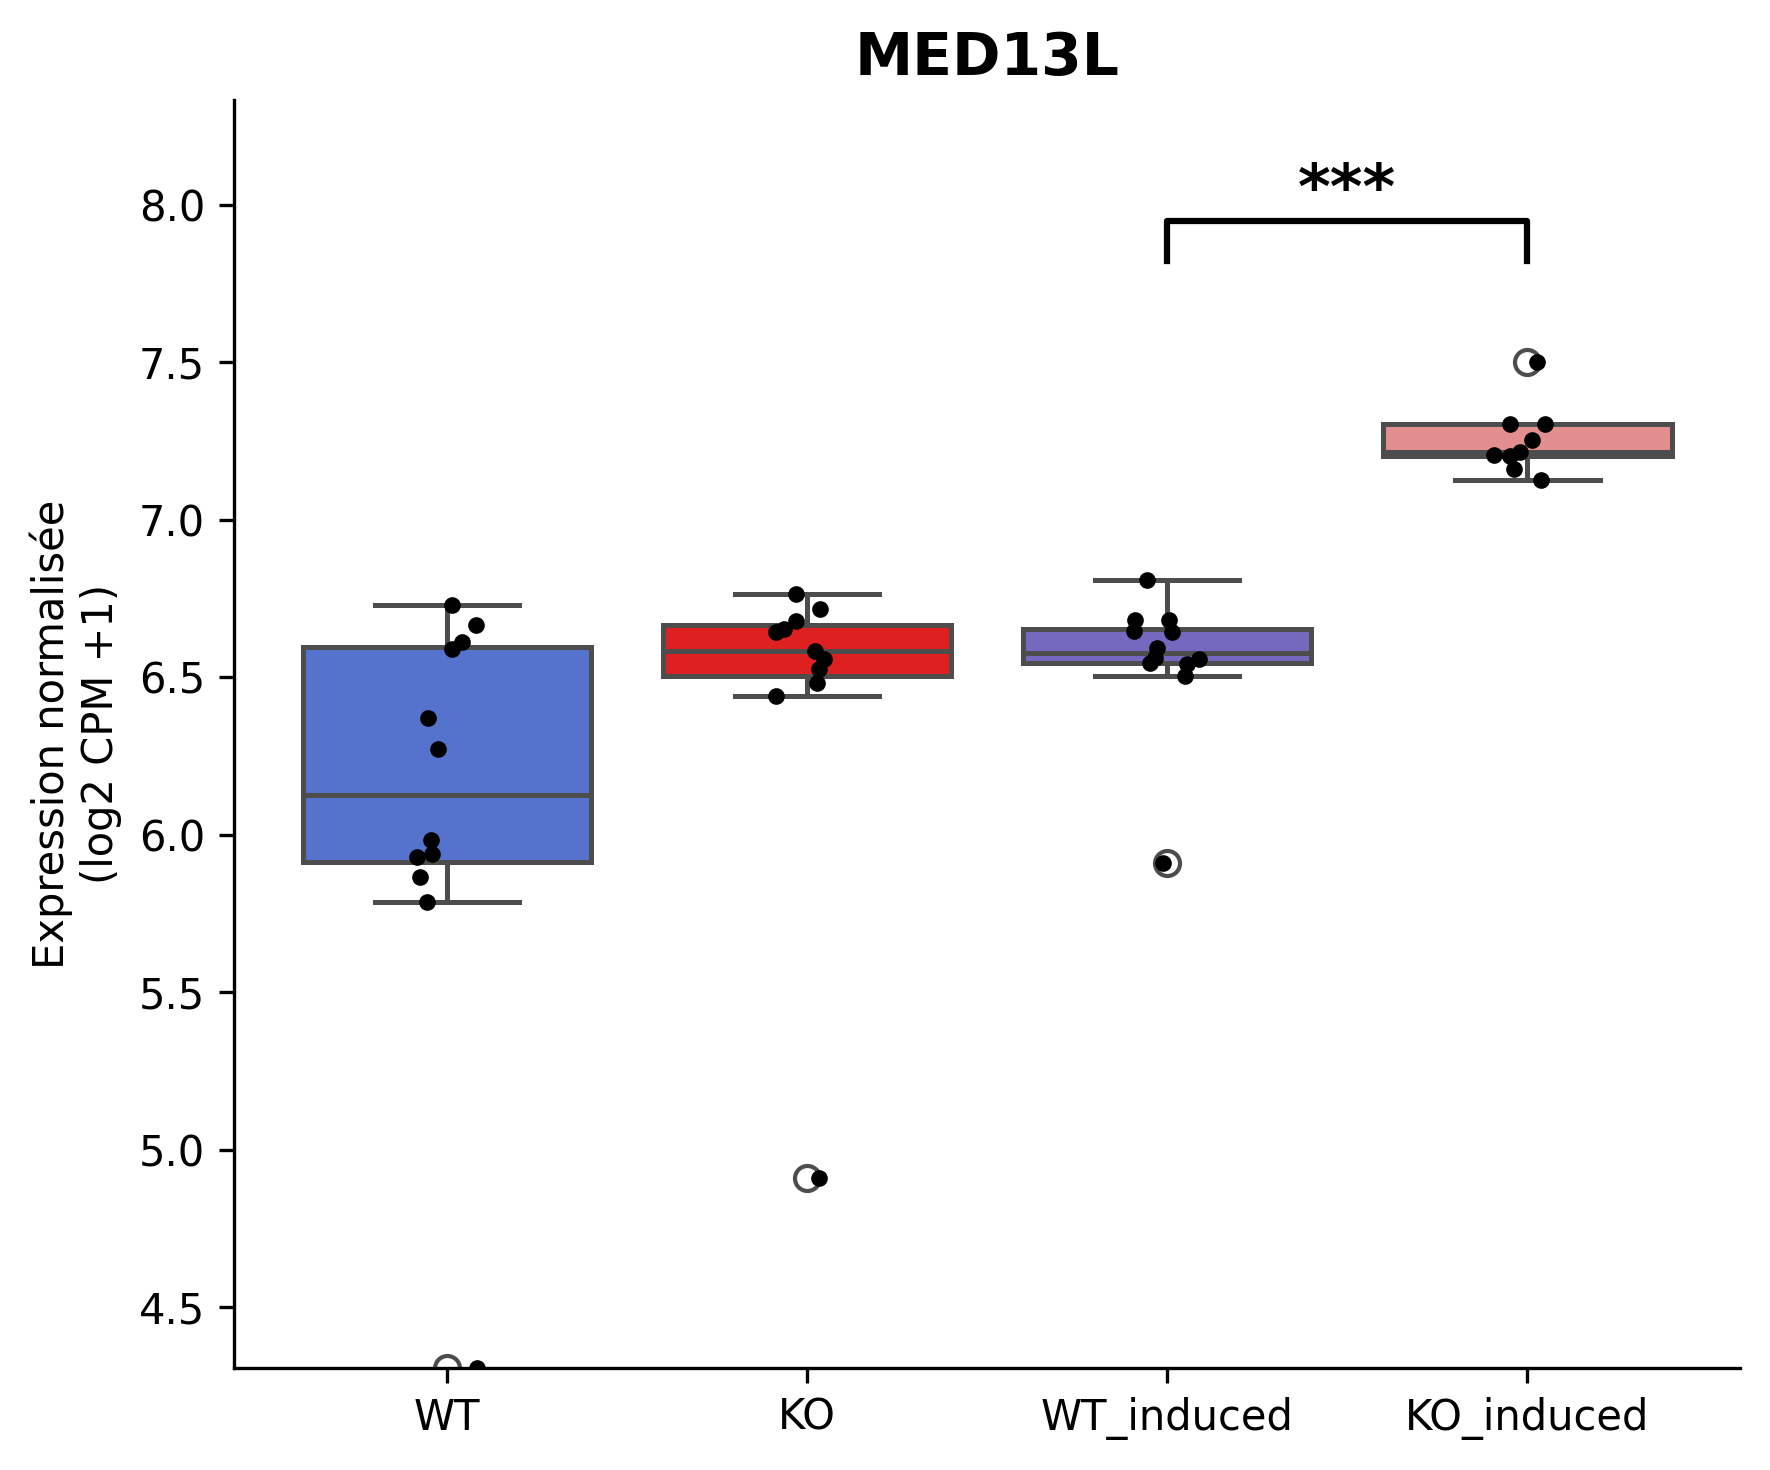

Plot : UNC5D


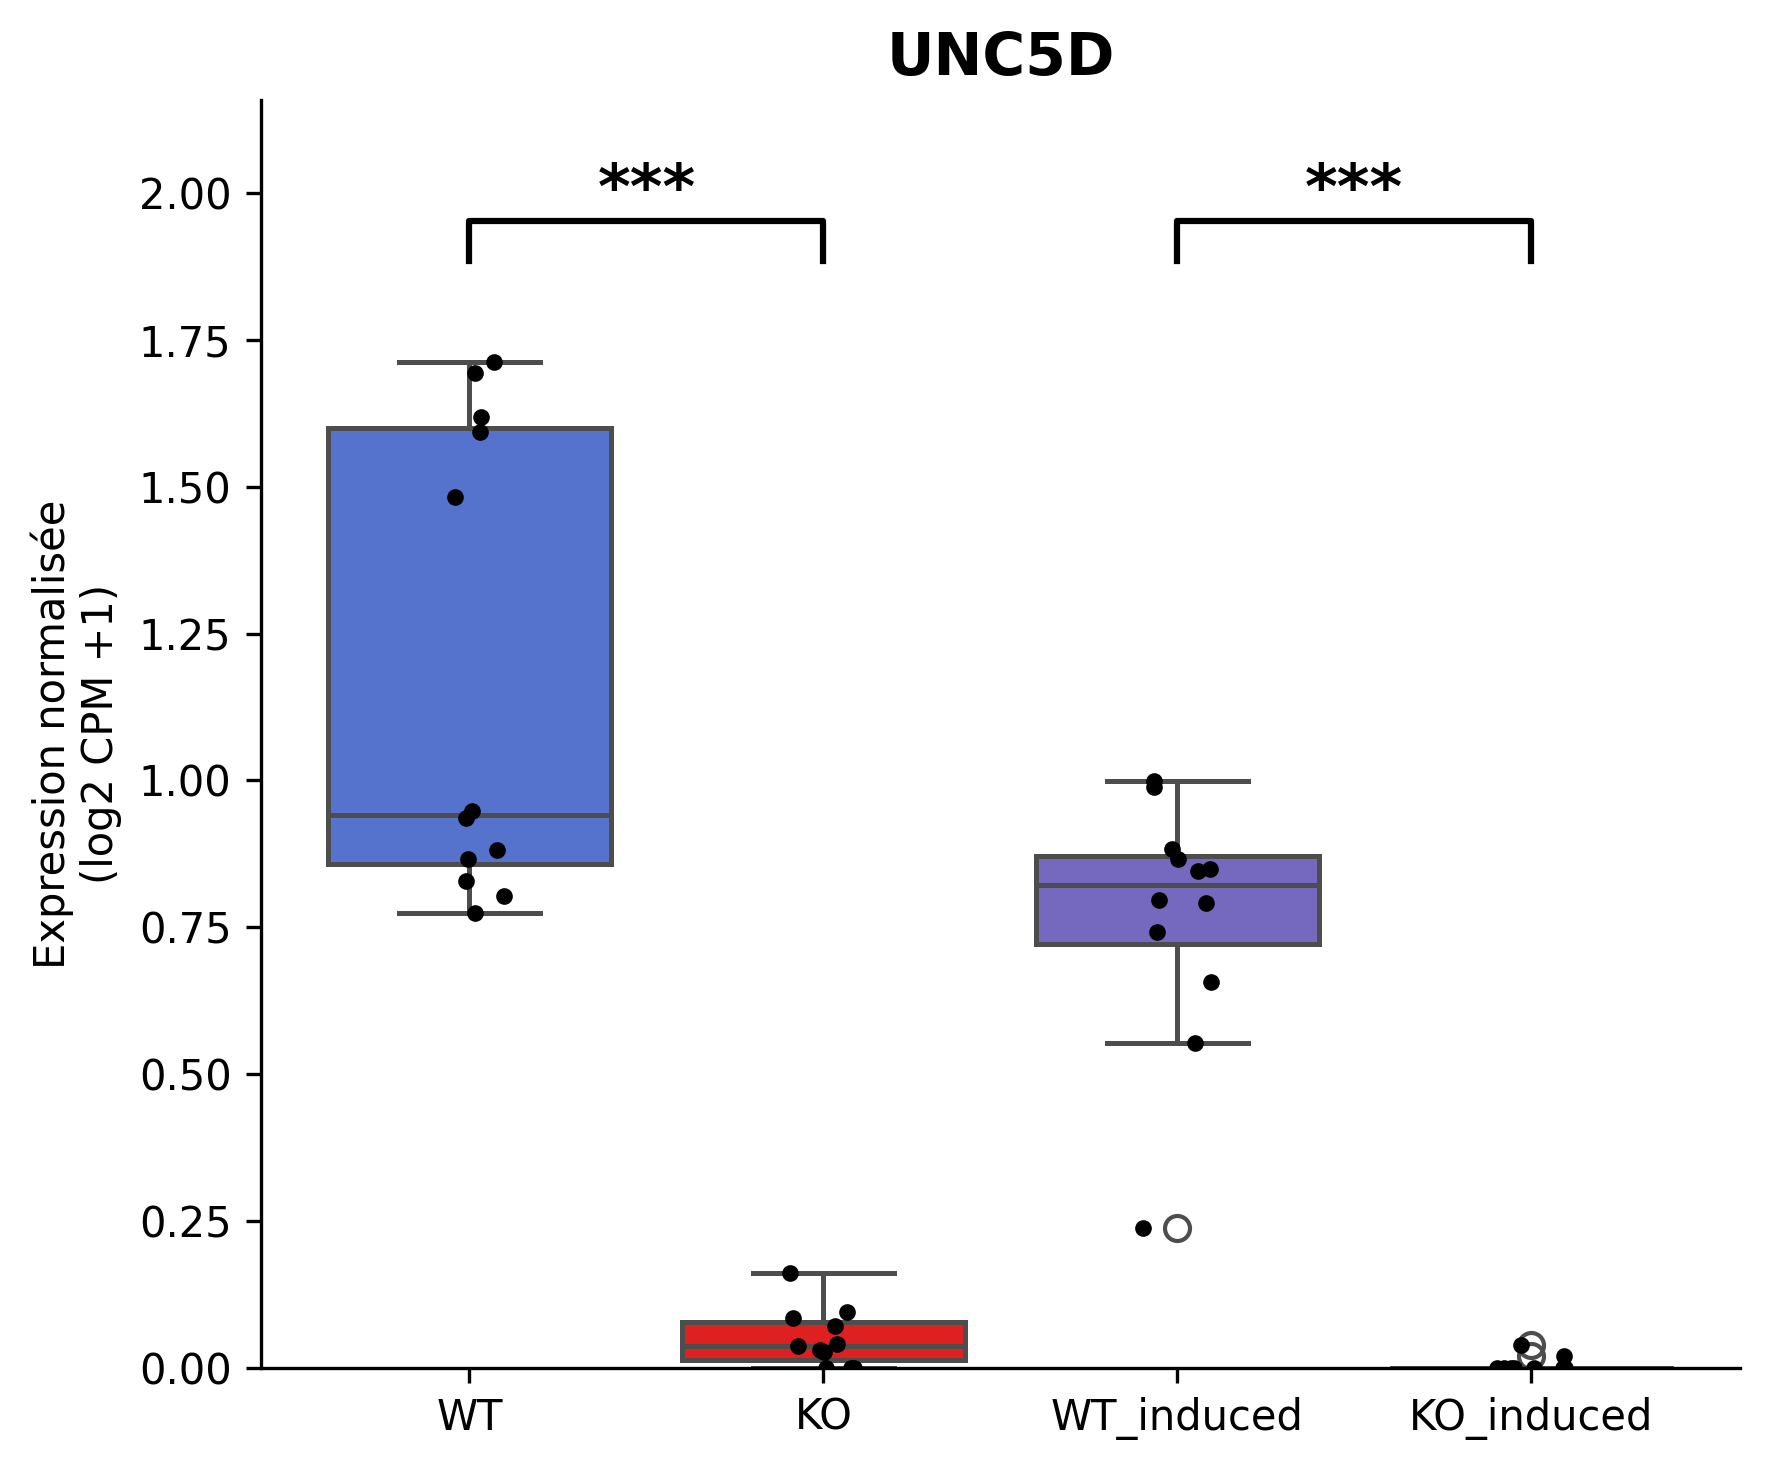

Plot : TBXT


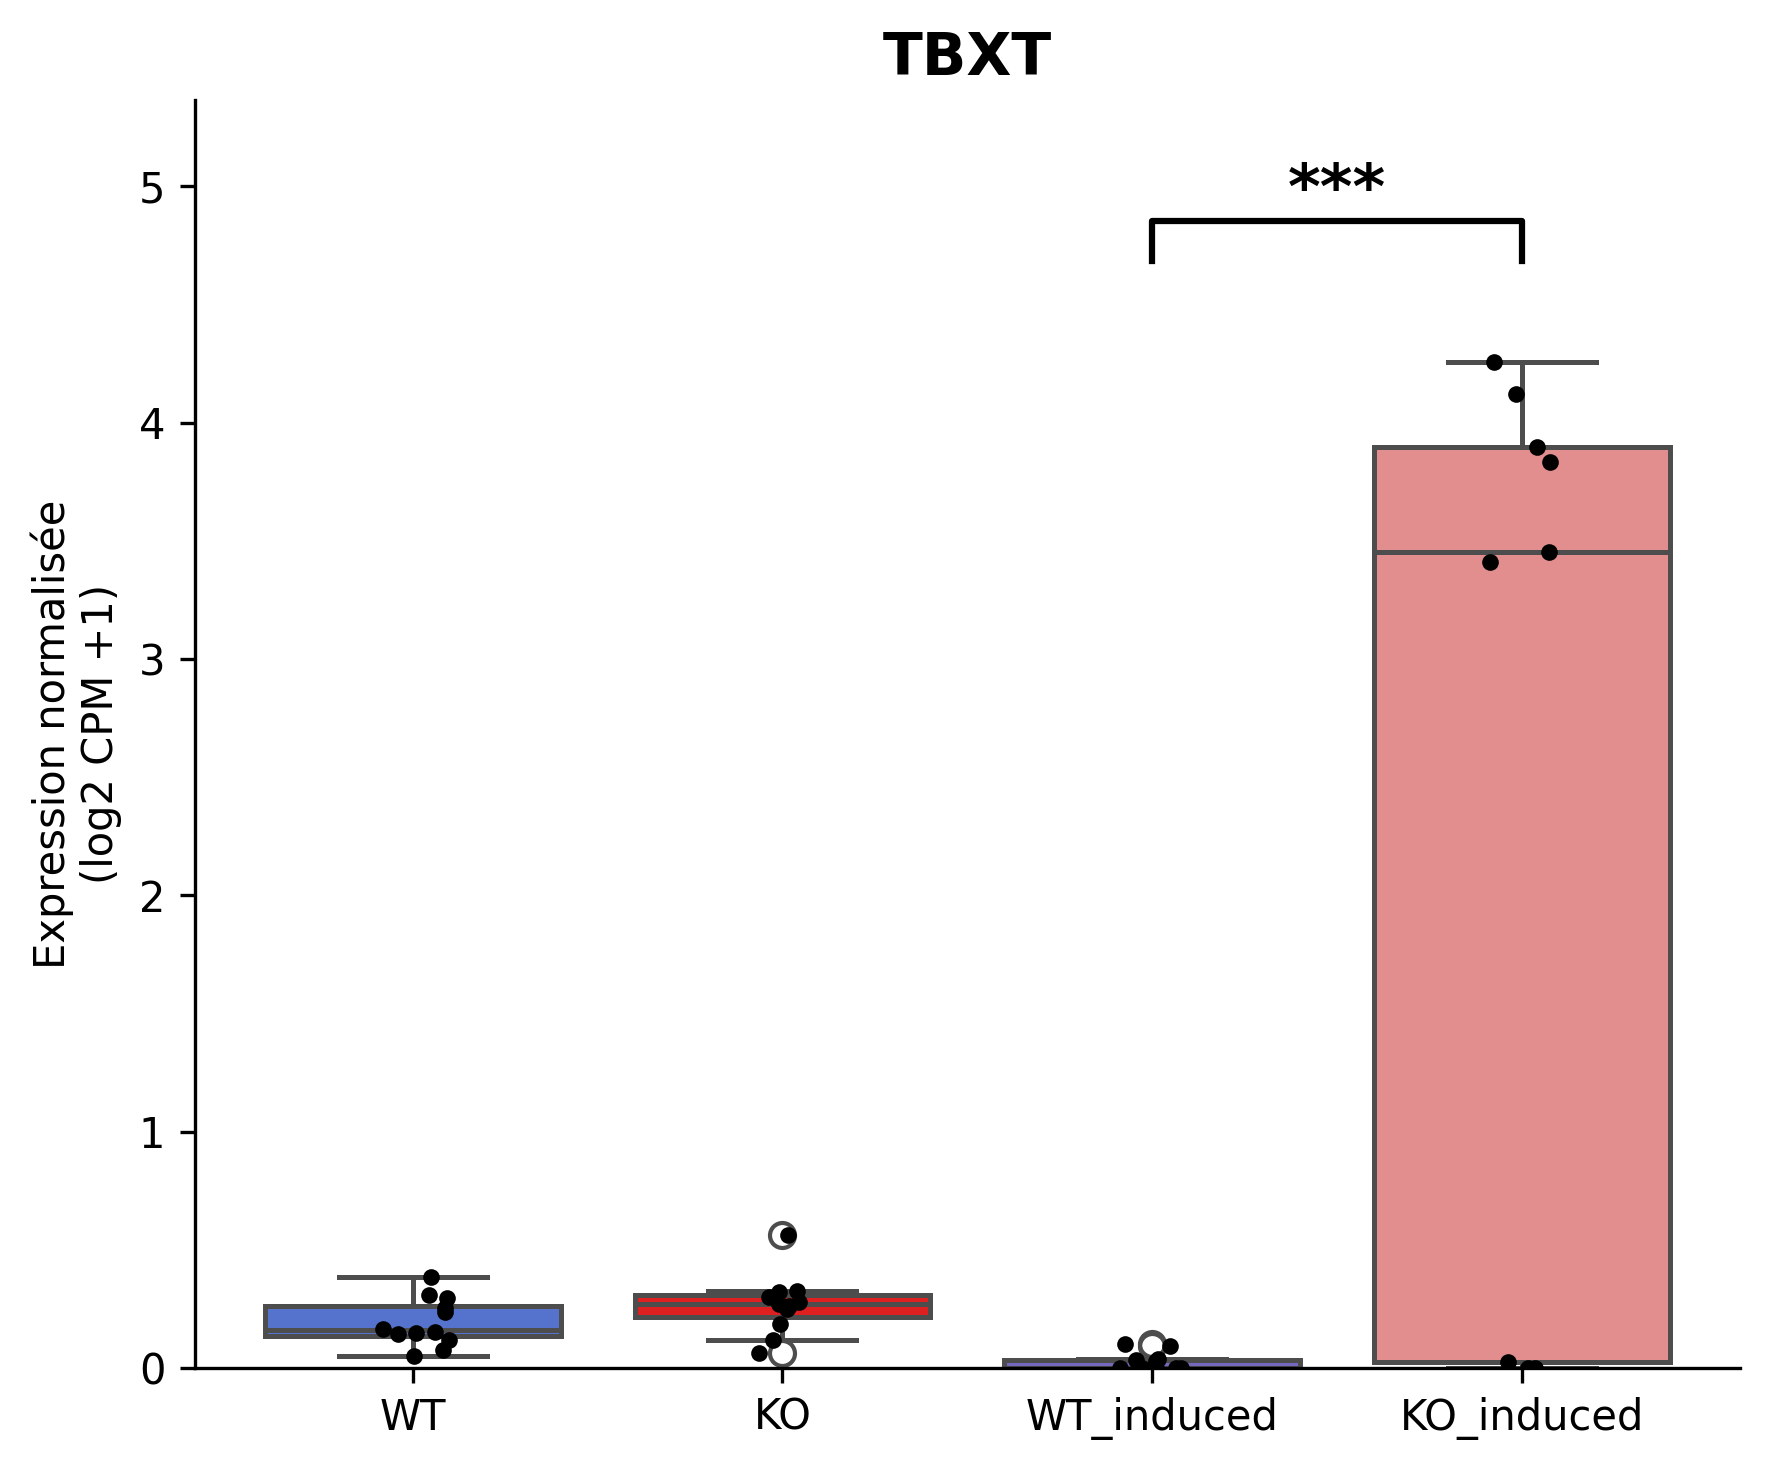

Plot : LMX1A


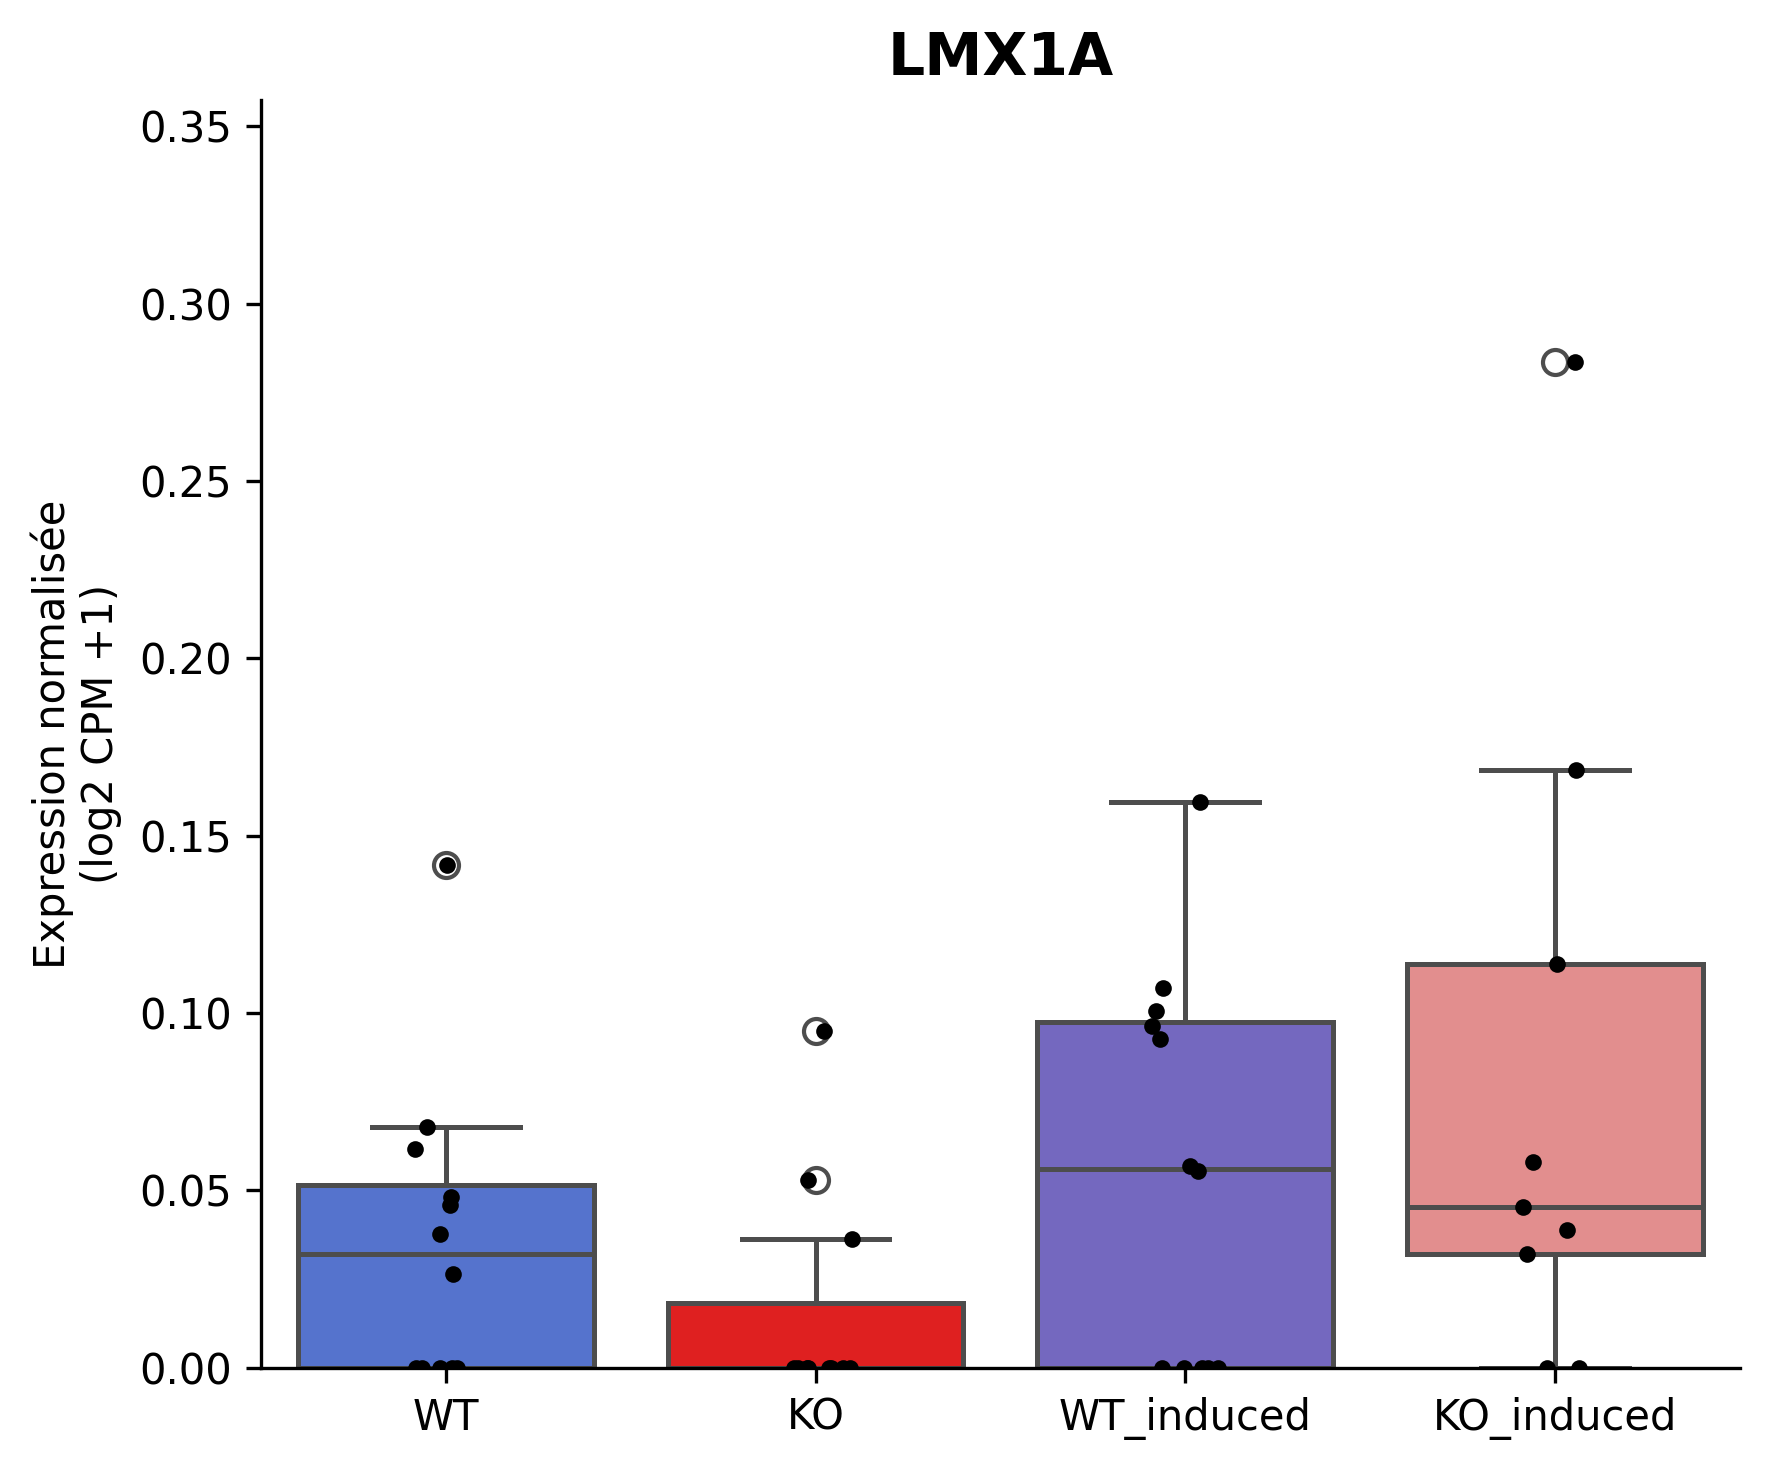

Plot : SOX11


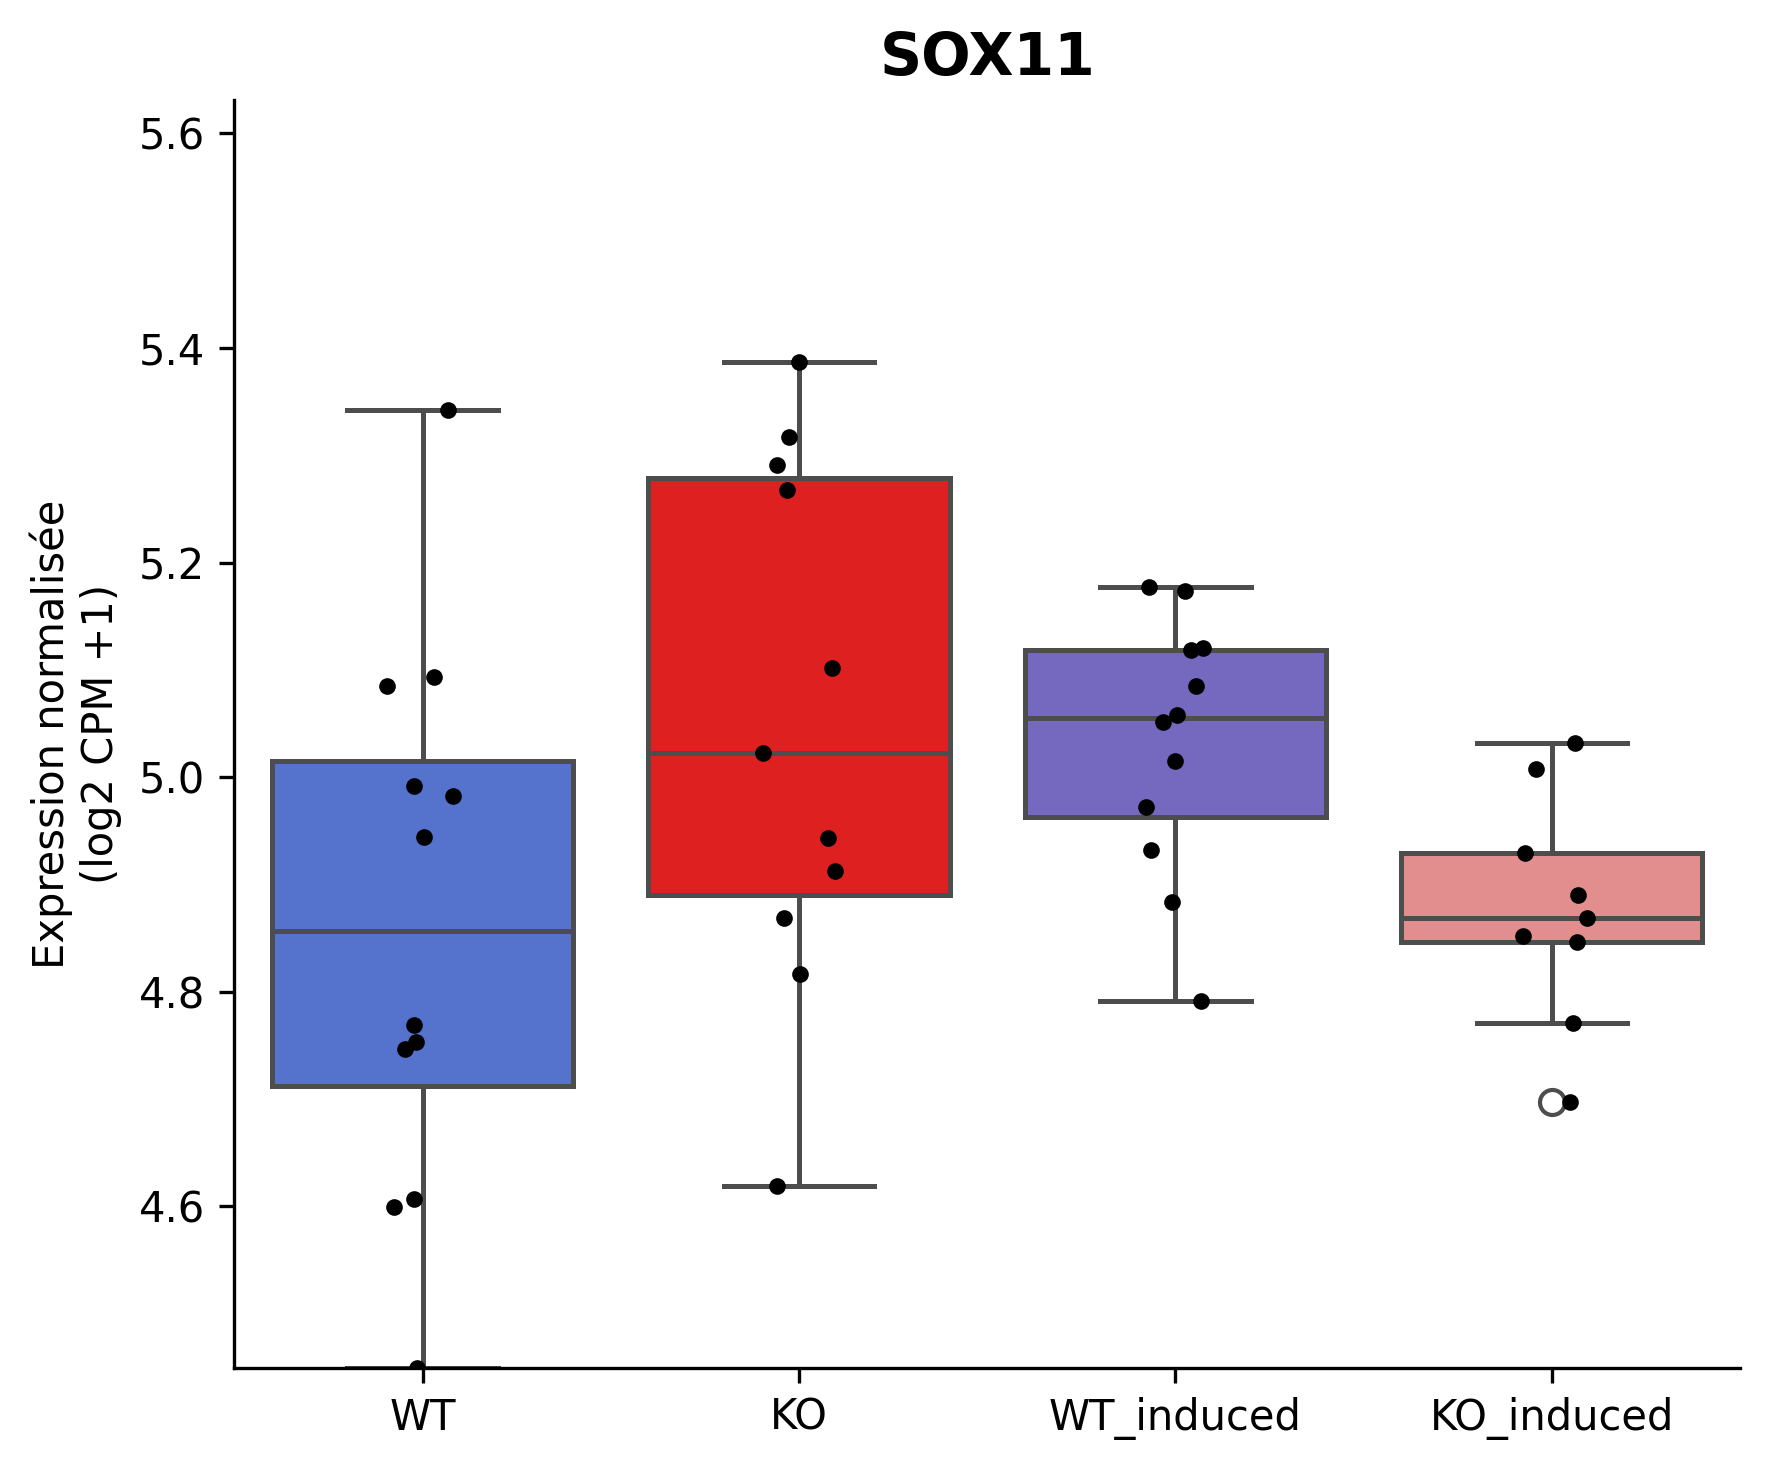

Plot : ZIC5


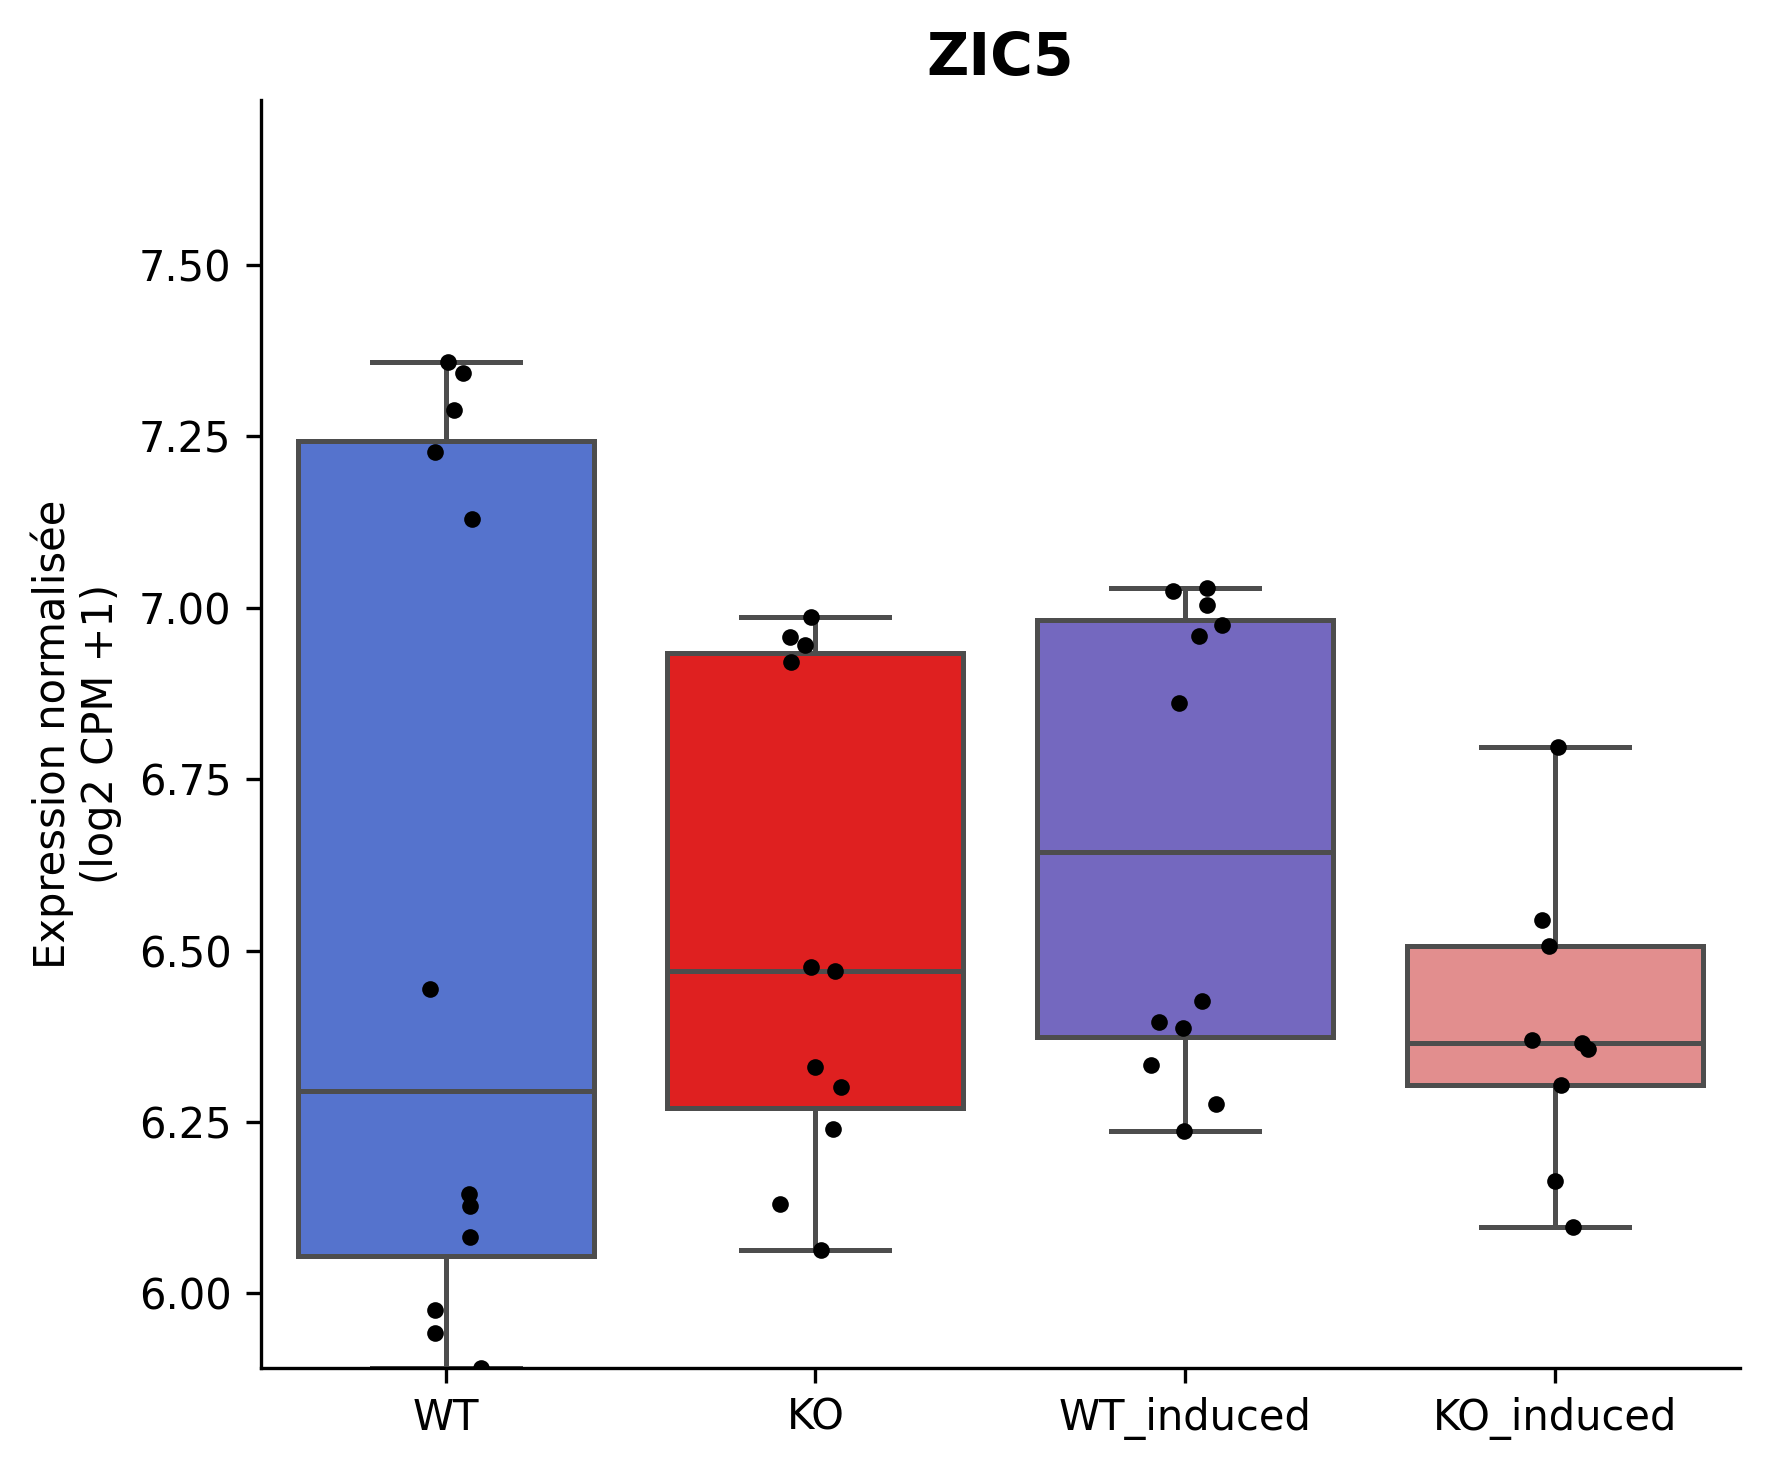

Plot : ZIC1


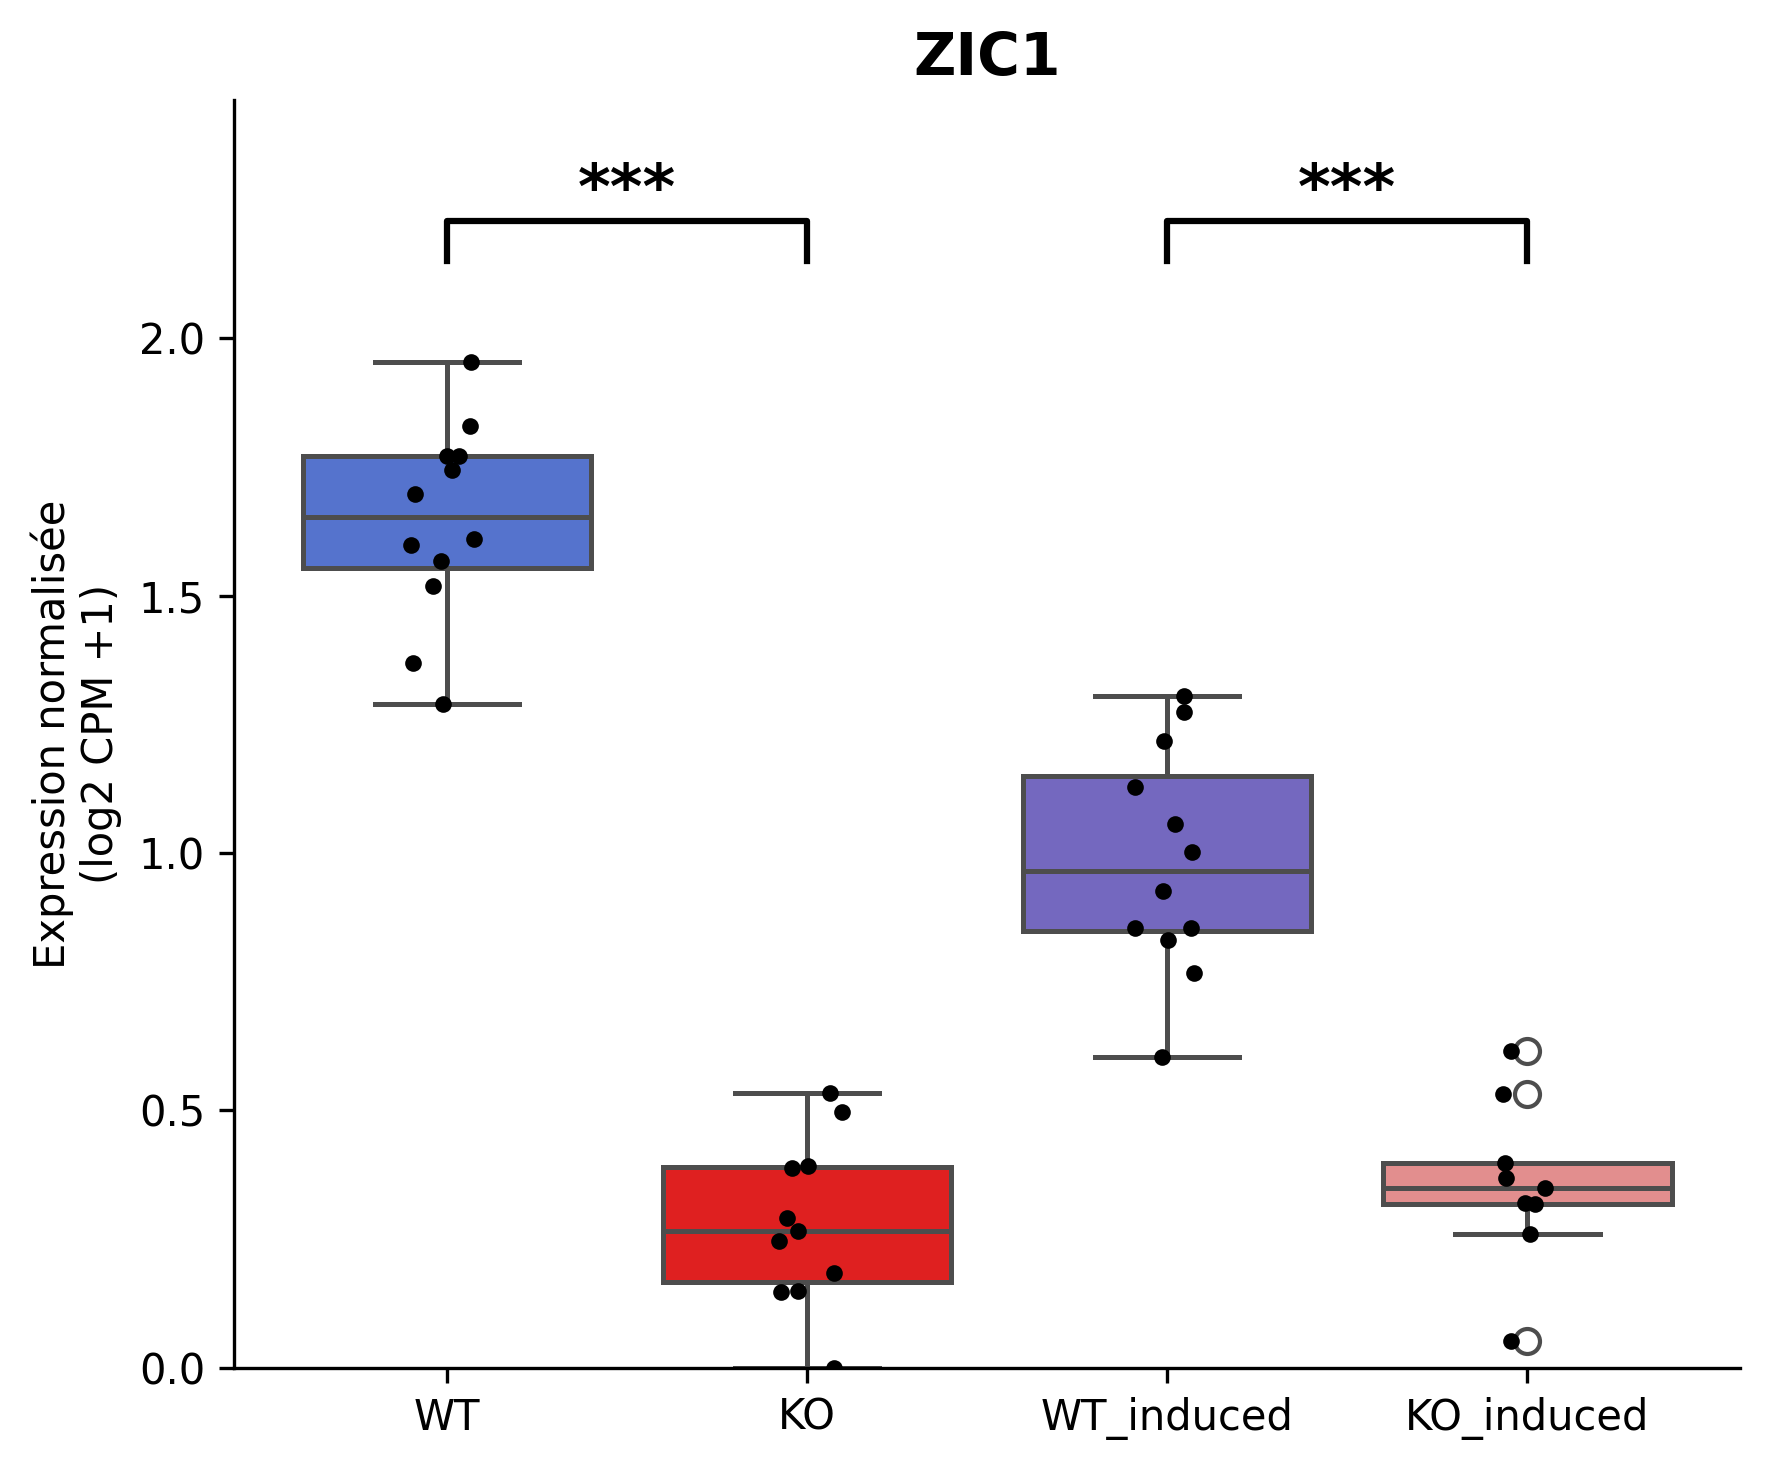

Plot : PAX3


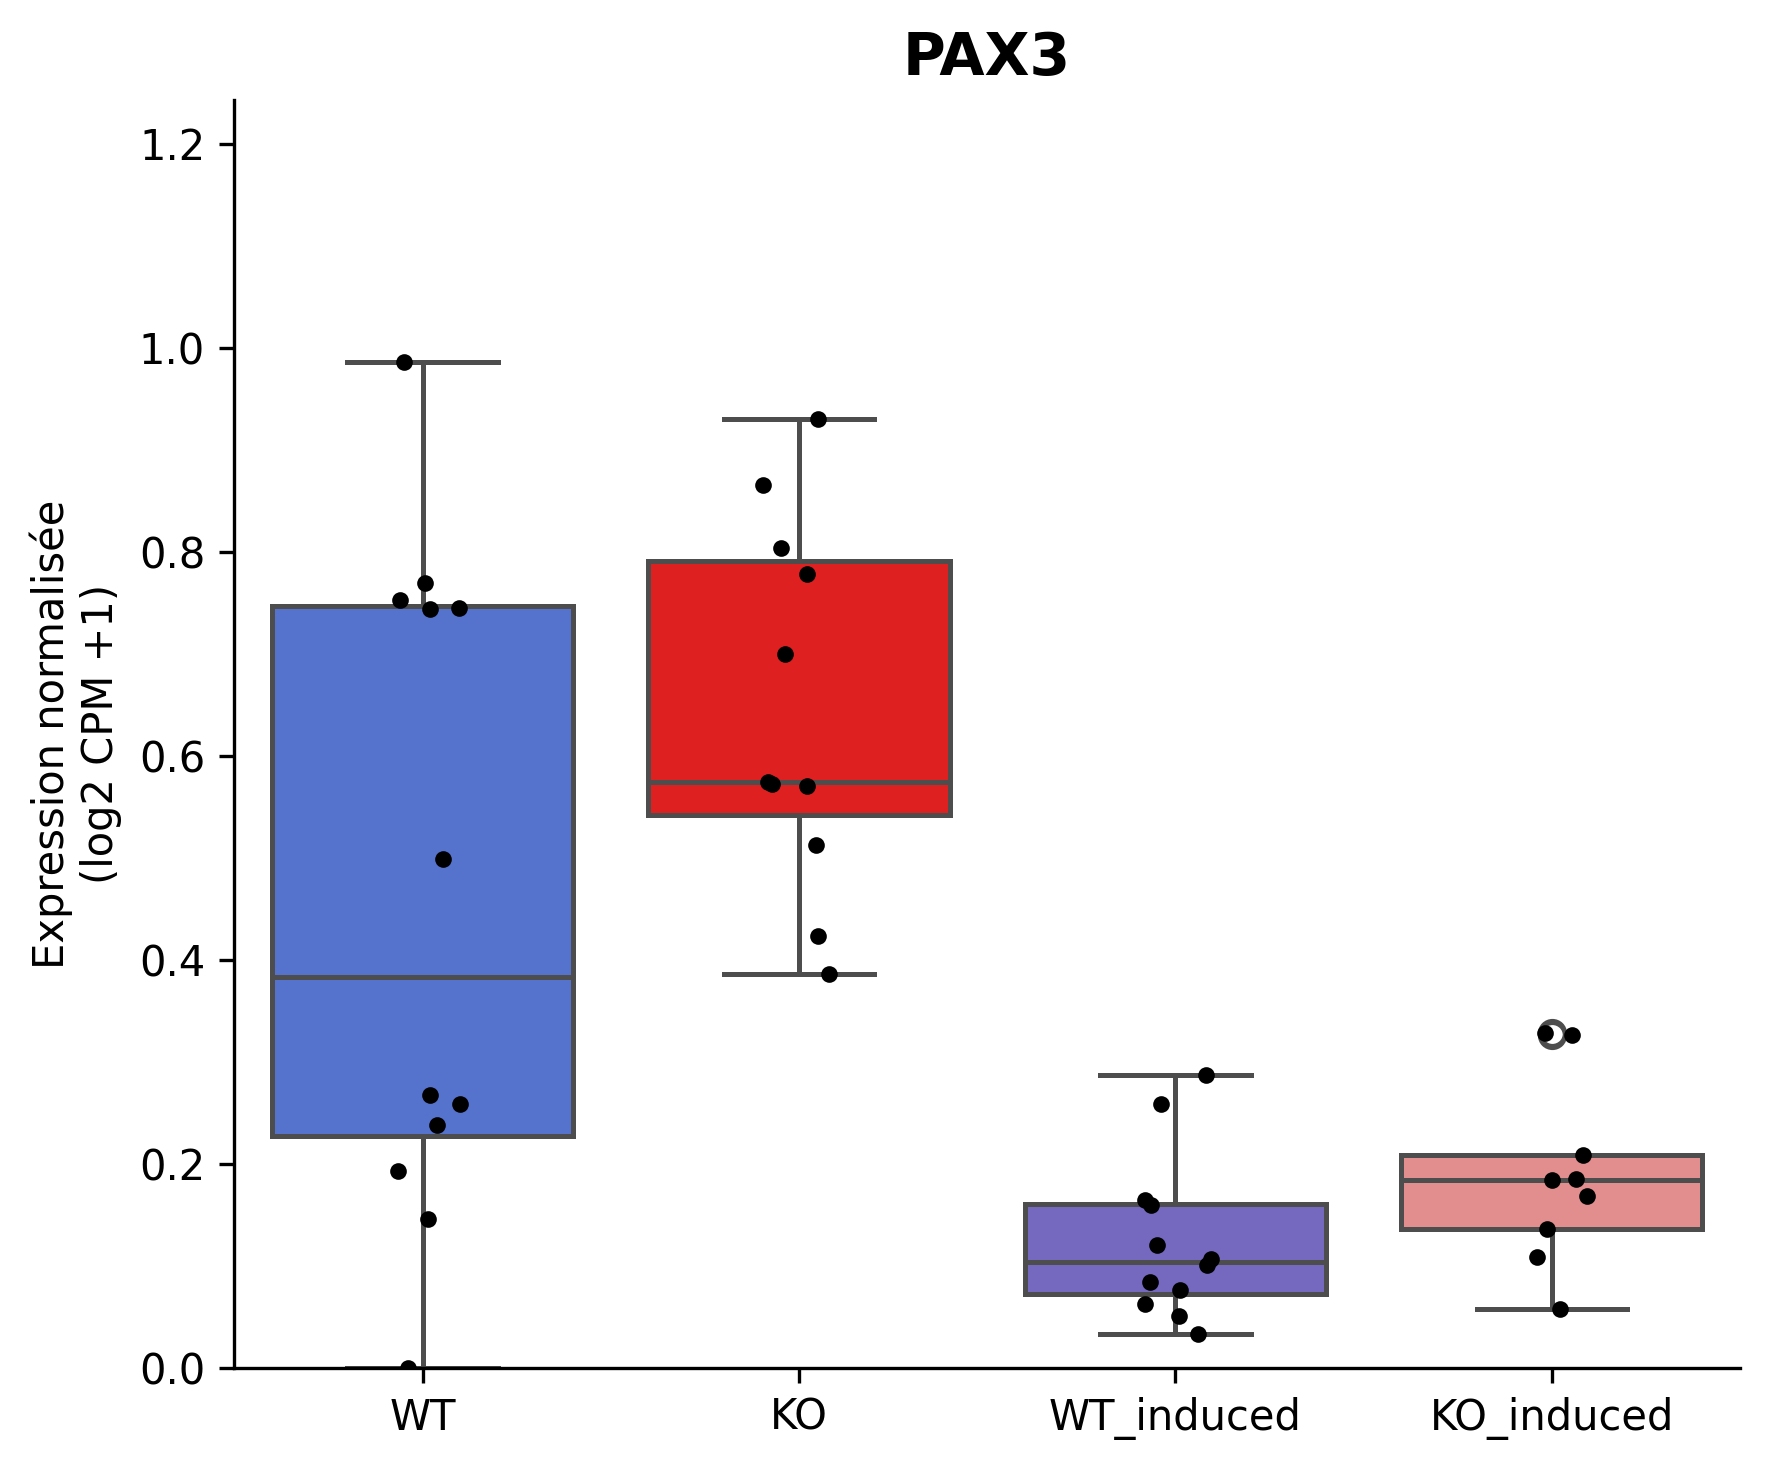

Plot : POU4F1


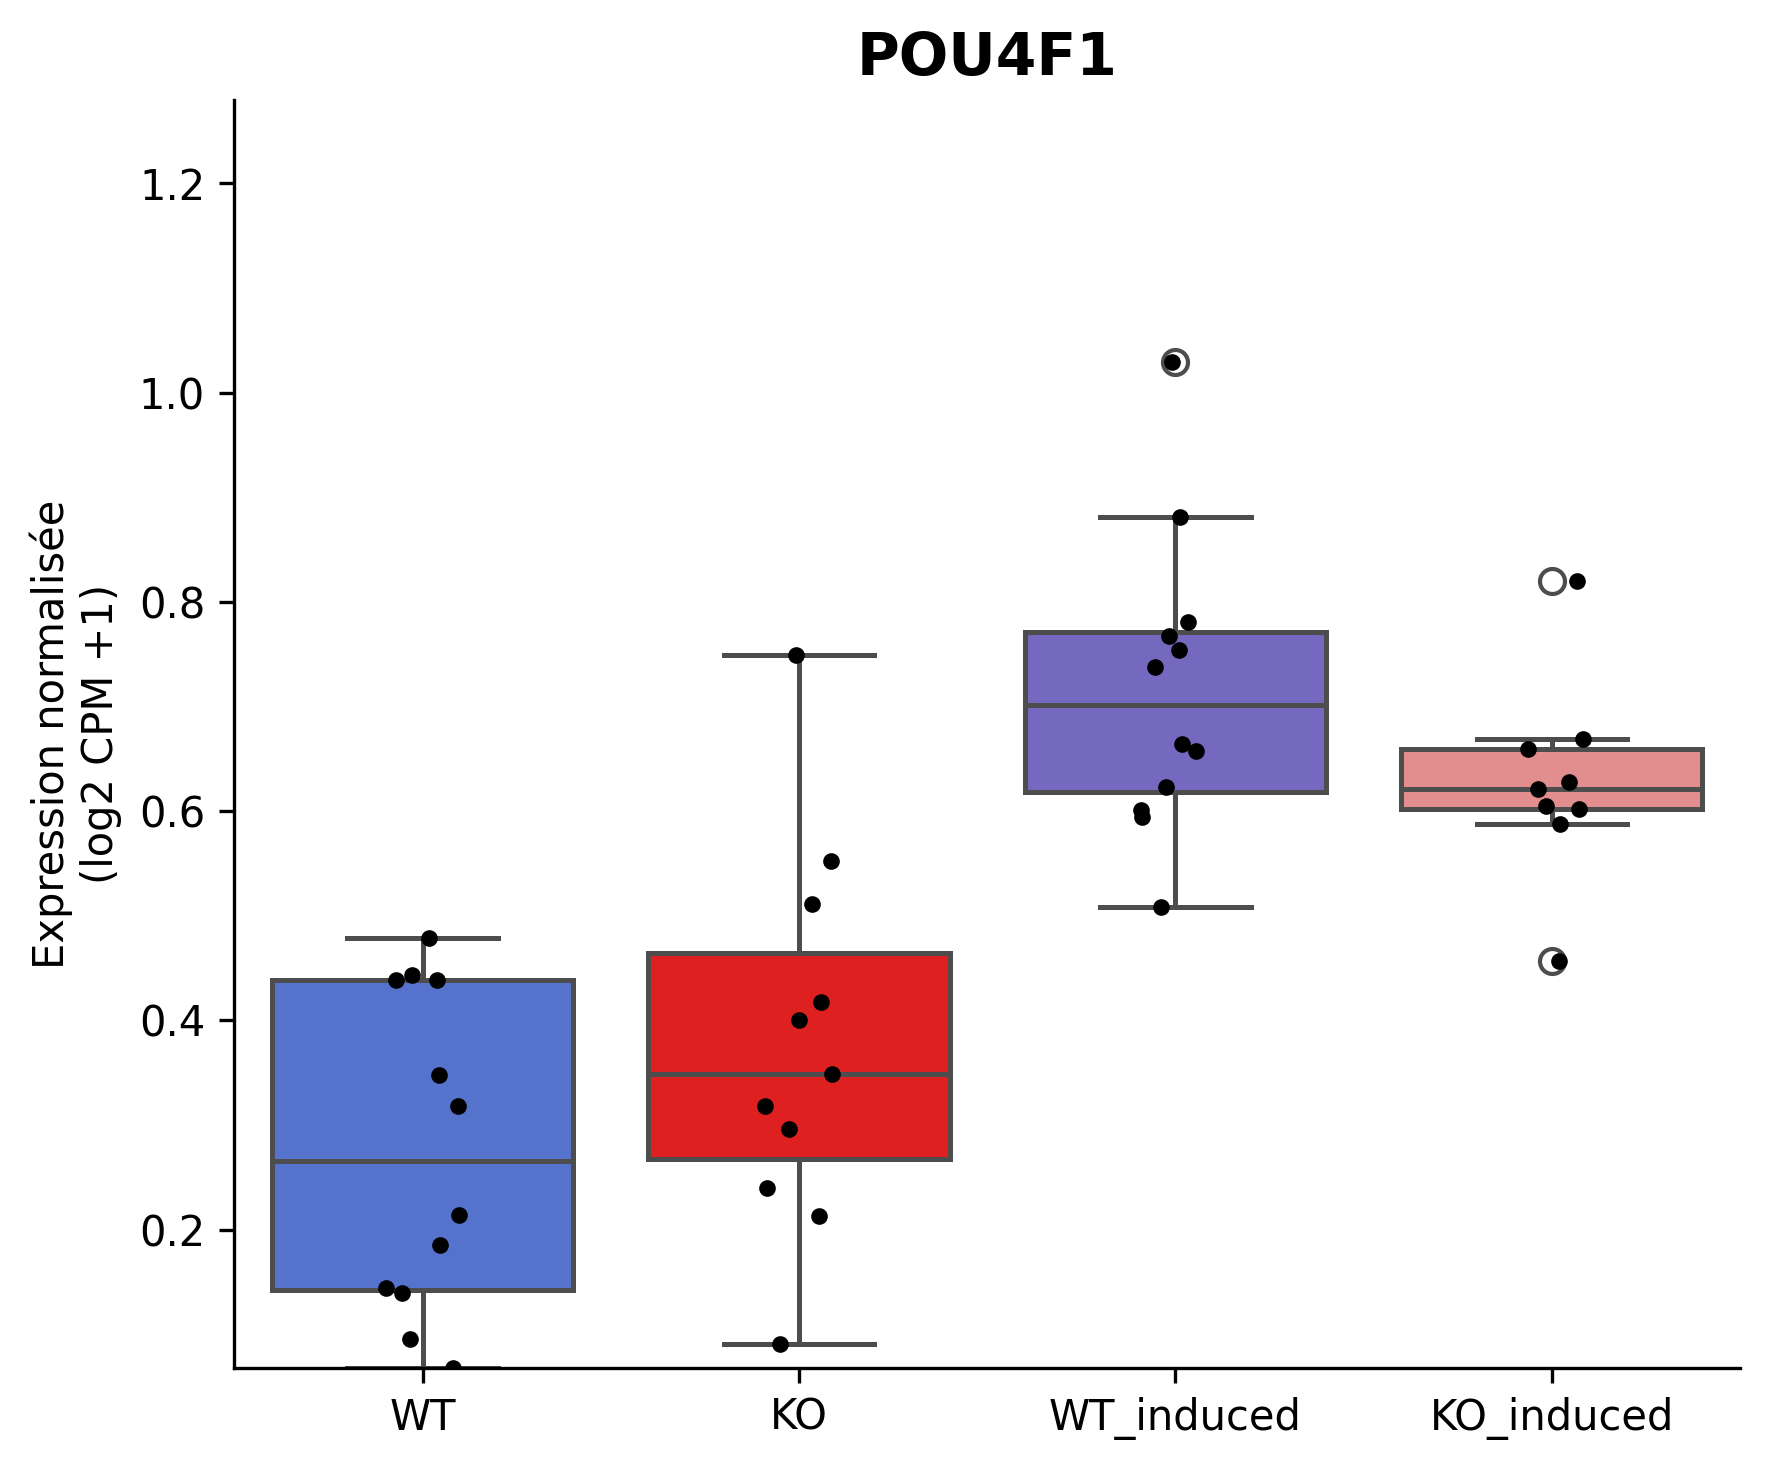

Plot : POU4F2


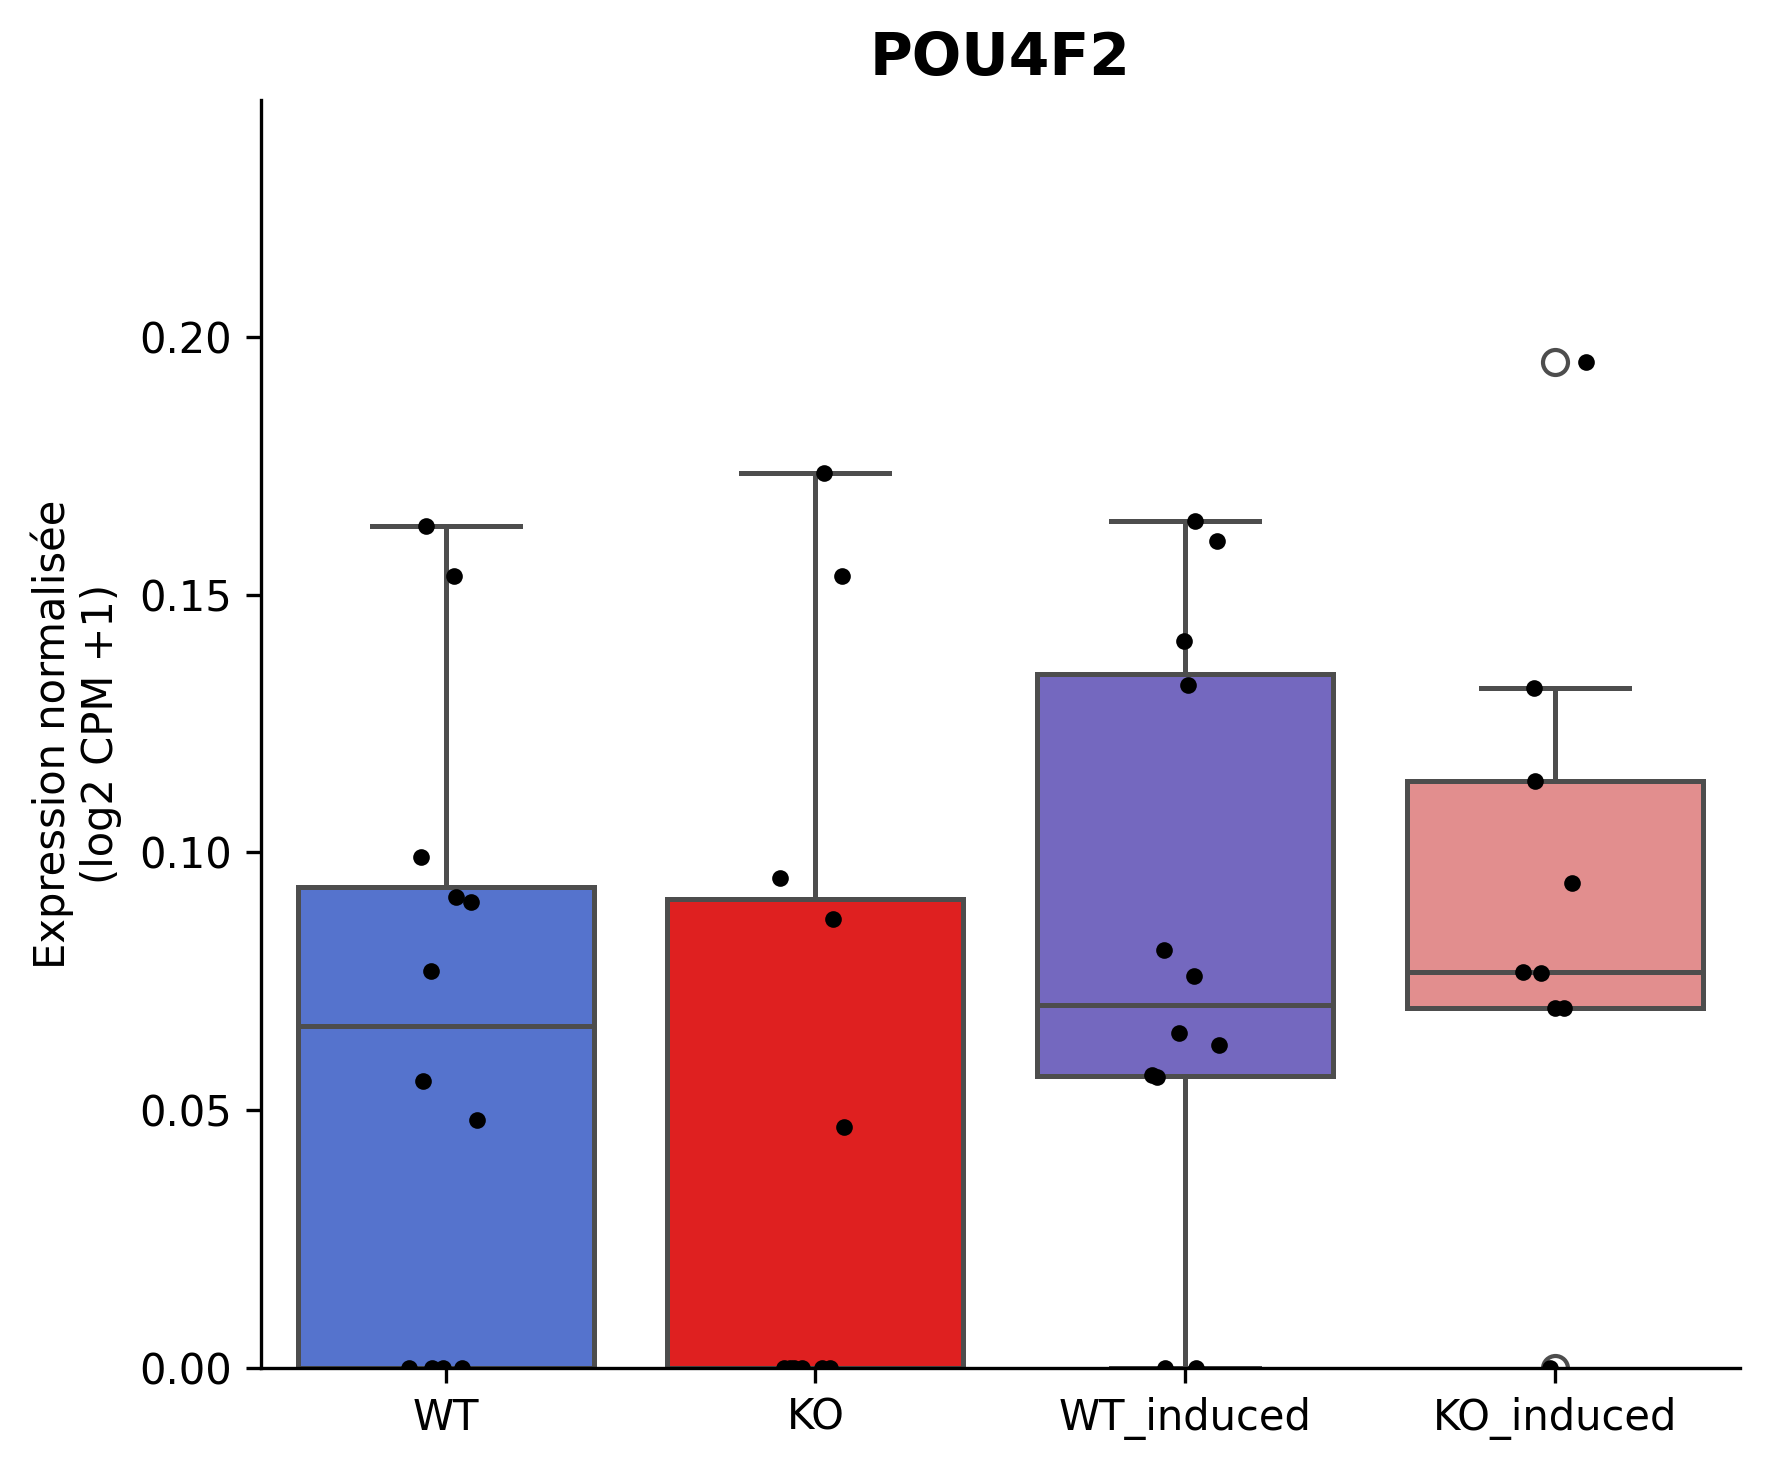

Plot : RXRG


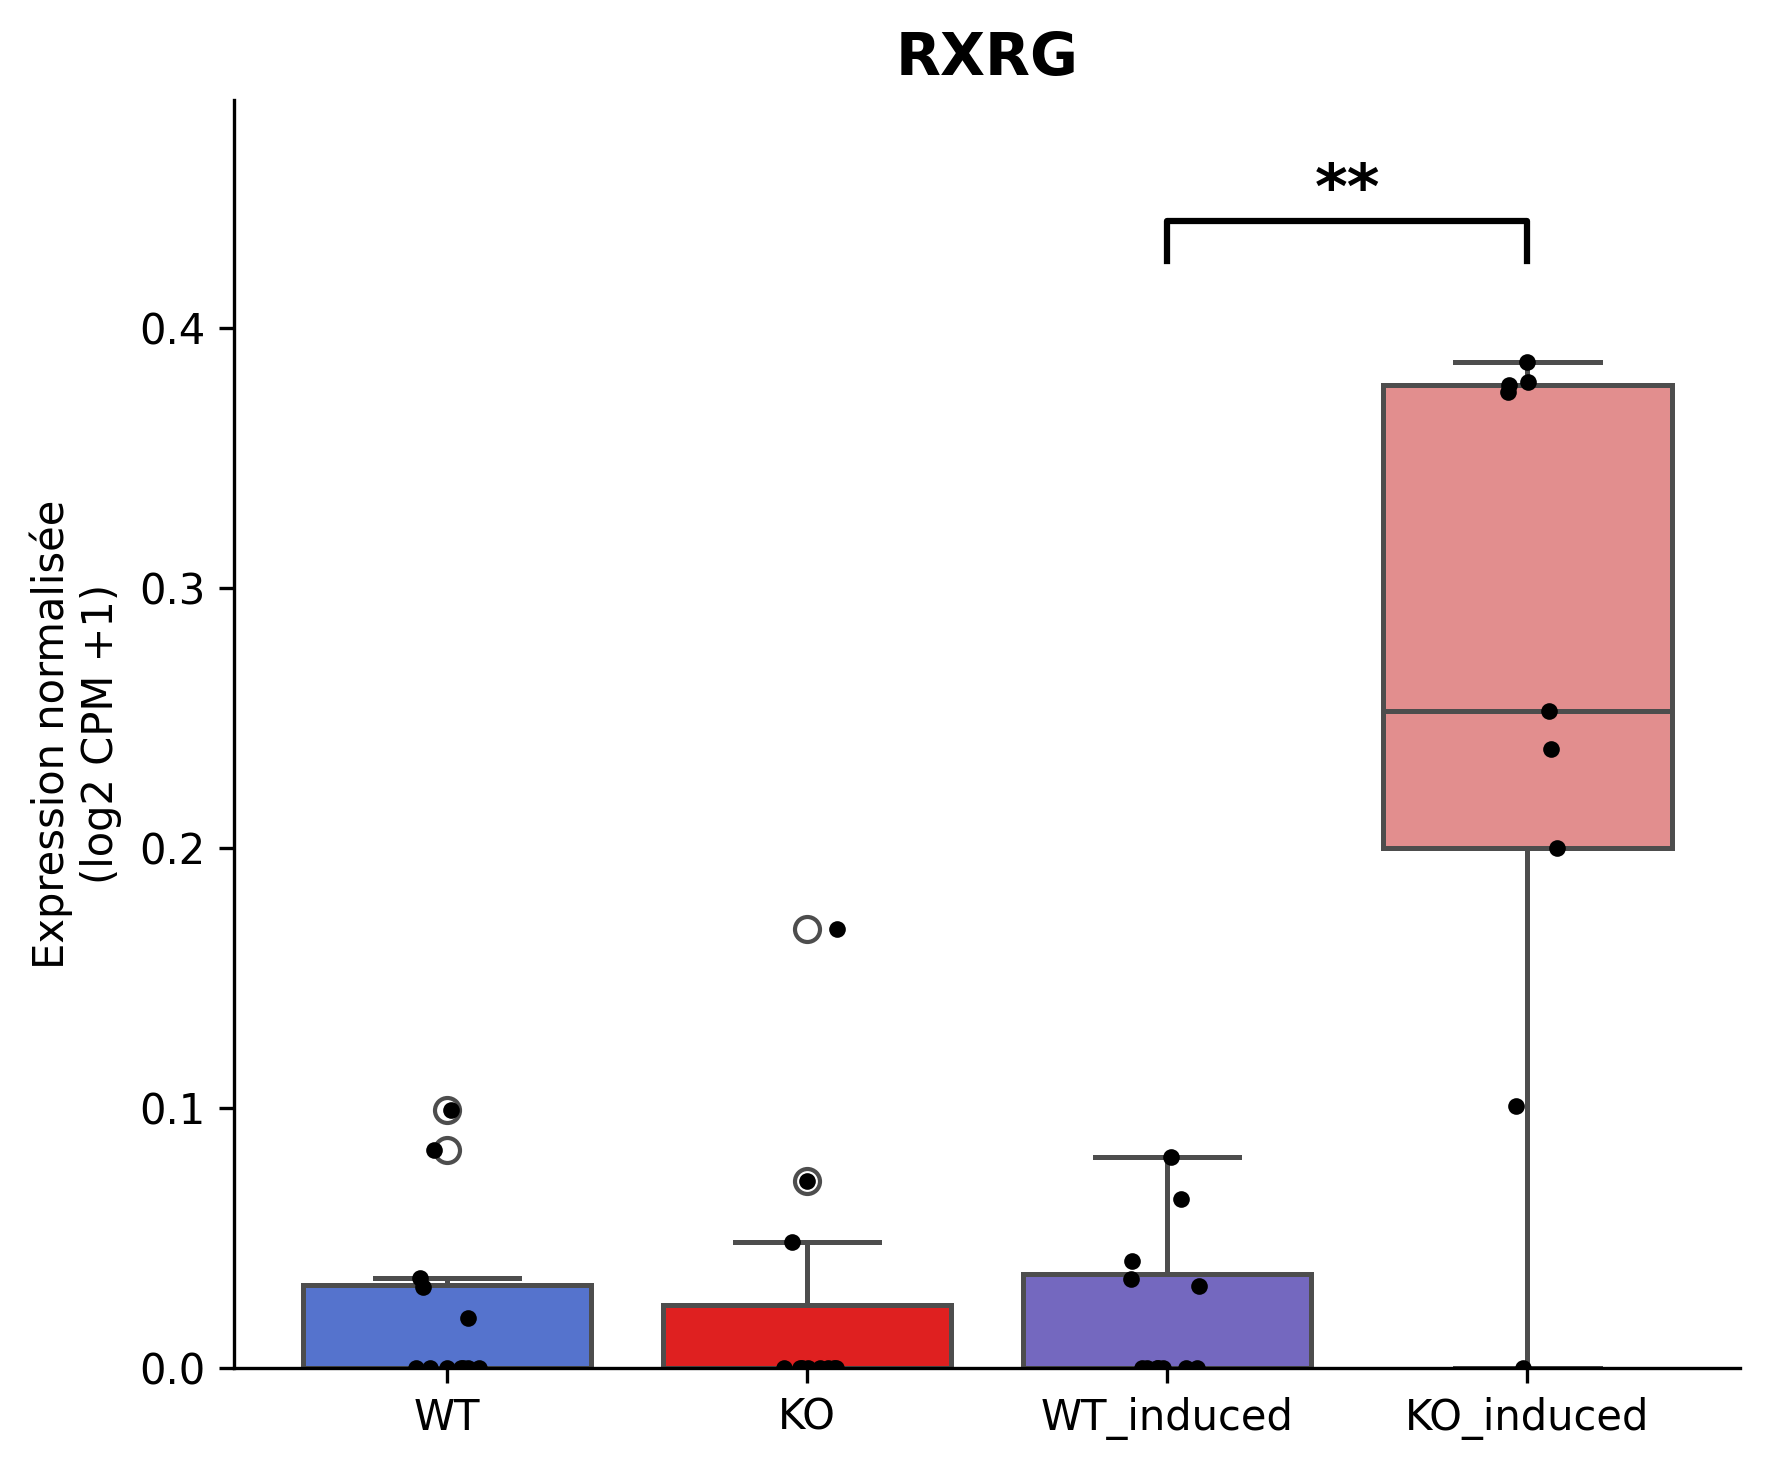

Plot : IL33


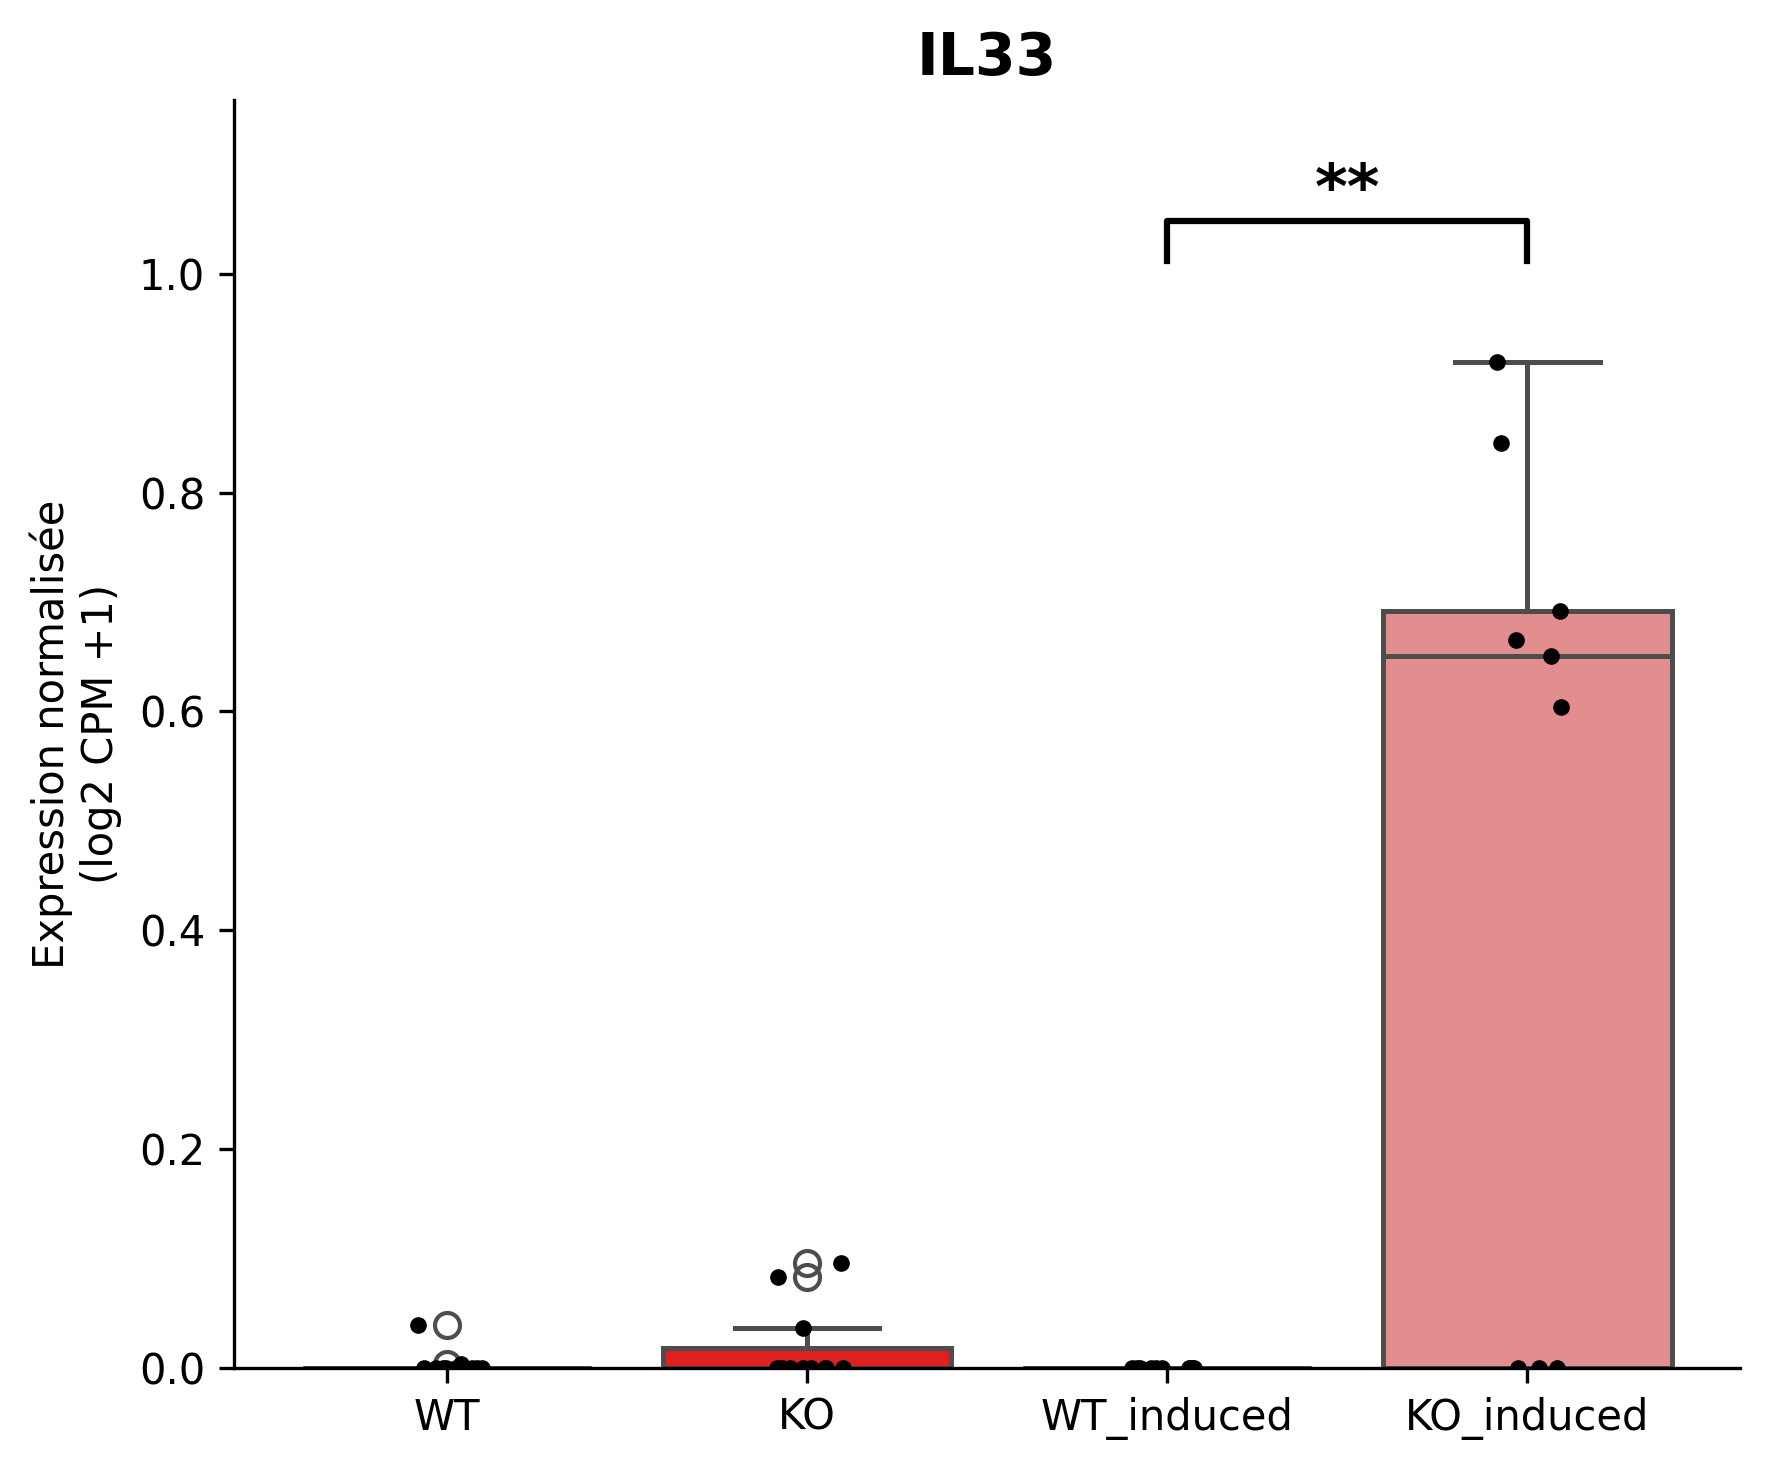

Plot : NHIP


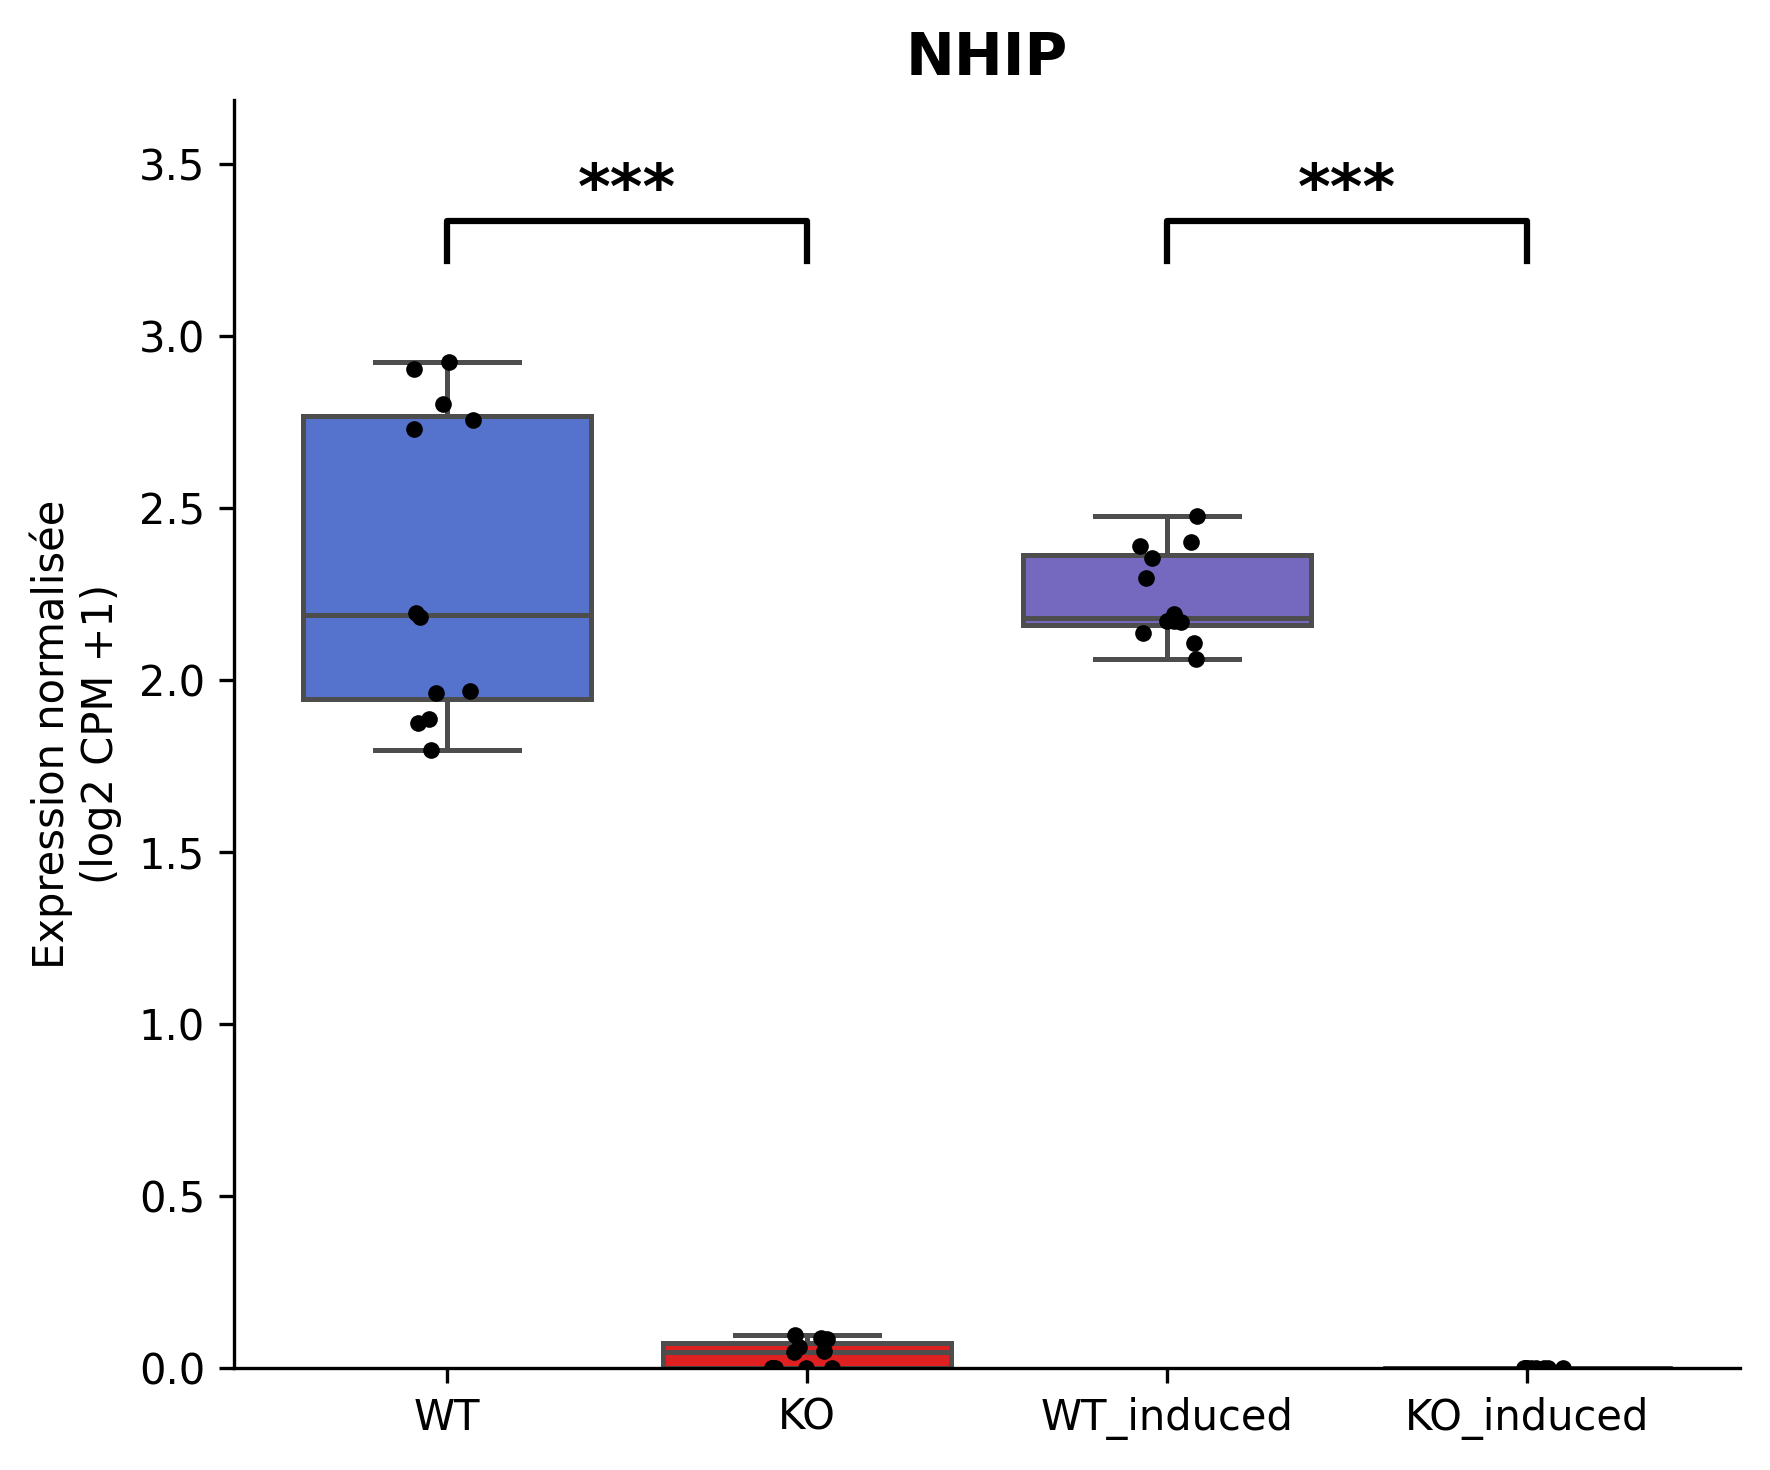

In [19]:
# Fonction : dessin du crochet
def add_significance(ax, x1, x2, y, h, text):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        lw=1.5,
        c="black"
    )

    ax.text(
        (x1+x2)/2,
        y+h,
        text,
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold"
    )

# Fonction qui convertit les padj en étoiles
def star_padj(p):
    if pd.isna(p):
        return ""
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

# Ordre des conditions
conditions_order = [
    "WT",
    "KO",
    "WT_induced",
    "KO_induced"
]

palette = {
    "WT": "royalblue",
    "KO": "red",
    "WT_induced": "slateblue",
    "KO_induced": "lightcoral"
}

# Boucle sur les gènes
for gene in selected_genes:
    if gene not in count_long["Gene name"].values:
        continue
    print("Plot :", gene)
    df = count_long[
        count_long["Gene name"] == gene
    ]

    # récupération des padj
    padj1 = deseq_KO_WT.loc[
        deseq_KO_WT["Gene name"] == gene,
        "padj"
    ]

    padj2 = deseq_KO_WT_induced.loc[
        deseq_KO_WT_induced["Gene name"] == gene,
        "padj"
    ]

    star1 = star_padj(padj1.iloc[0]) if len(padj1) > 0 else ""
    star2 = star_padj(padj2.iloc[0]) if len(padj2) > 0 else ""

    # Création de la figure
    plt.figure(figsize=(6,5), dpi=300)

    ax = sns.boxplot(
        data=df,
        x="Condition",
        y="Expression",
        order=conditions_order,
        hue="Condition",
        palette=palette,
        legend=False,
        linewidth=1.2
    )


    sns.stripplot(
        data=df,
        x="Condition",
        y="Expression",
        order=conditions_order,
        color="black",
        size=4,
        jitter=True
    )


    # Position commune des crochets
    ymin = df["Expression"].min()
    ymax = df["Expression"].max()

    amplitude = ymax - ymin

    # Si toutes les valeurs sont identiques
    if amplitude == 0:
        amplitude = ymax * 0.2

    # même hauteur pour les deux comparaisons
    y = ymax + amplitude * 0.10

    # hauteur du crochet
    h = amplitude * 0.04


    # WT vs KO
    if star1 != "":
        add_significance(
            ax,
            0,
            1,
            y,
            h,
            star1
        )

    # WT_induced vs KO_induced
    if star2 != "":
        add_significance(ax,2,3,y,h,star2)

    # Laisser une marge
    ax.set_ylim(ymin,y + 4*h)

    # Mise en forme
    plt.title(
        gene,
        fontsize=14,
        fontweight="bold"
    )

    plt.ylabel(
        "Expression normalisée\n(log2 CPM +1)"
    )

    plt.xlabel("")

    sns.despine()

    plt.tight_layout()

    plt.savefig(
        f"{gene}_expression.pdf",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()